# MLPDataset — rà soát có mục tiêu từ cache

CPU đủ. Notebook này không tải video, không sửa annotation và không chạy lại EDA. Giữ Drive và `RUN_NAME=mlpdataset-eda-261017-v3`. Notebook EDA đã chạy được giữ nguyên.

Hàng đợi82mốc/42video/10nhóm:14clip±5s cũ đã khớp hash và có quan sát thô;20mốc biên nguồn giữ HOLD theo policy;48mốc cần ngữ cảnh mới. Mặc định chỉ trích48mốc còn thiếu. Kết quả mới ở thư mục riêng cạnh run gốc. Mỗi clip/ảnh/checkpoint có hash và thời gian PTS; thành công trích ảnh không tự chứng nhận nhãn.

Protocol-v1 đã chốt quy tắc; GT/cohort vẫn chờ review. Preview0.25s không đủ chứng nhận frame cuối slide. Sau khi chạy, lưu notebook cùng outputs để tiếp tục đánh giá nội dung và quyết định các ca chưa rõ.

In [1]:
from pathlib import Path
import base64, hashlib, html, io, json, os, re, shutil, subprocess, time
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display, Markdown, HTML
RUN_NAME = "mlpdataset-eda-261017-v3" #@param {type:"string"}
USE_GOOGLE_DRIVE = True #@param {type:"boolean"}
EXTRACT_NEW_CONTEXTS = True #@param {type:"boolean"}
REVIEW_EXTRA_KEYS = [] # Optional video_id:index keys for historical/edge re-extraction.
REVIEW_MAX_MINUTES = 60 #@param {type:"number"}
REVIEW_MAX_GB = 0.75 #@param {type:"number"}
MIN_FREE_GB = 1.0 #@param {type:"number"}
SOURCE_STAGE_GB = 2.0 #@param {type:"number"}
assert re.fullmatch(r'[A-Za-z0-9_-]+',RUN_NAME)
assert 0 < REVIEW_MAX_MINUTES <= 240 and 0 < REVIEW_MAX_GB <= 8 and MIN_FREE_GB > 0
assert 0 <= SOURCE_STAGE_GB <= 8
if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/MLPDataset_EDA')/RUN_NAME
else:
    BASE = Path.cwd()/RUN_NAME
if not BASE.is_dir():
    raise FileNotFoundError('Existing run cache not found: '+str(BASE))
REVIEW_ROOT = BASE.parent/(RUN_NAME+'-targeted-review-v1')
assert shutil.which('ffmpeg') and shutil.which('ffprobe'), 'FFmpeg and ffprobe required; no automatic download.'
print('Read existing source cache:',BASE)
print('Write separate review artifacts:',REVIEW_ROOT)


Mounted at /content/drive
Read existing source cache: /content/drive/MyDrive/MLPDataset_EDA/mlpdataset-eda-261017-v3
Write separate review artifacts: /content/drive/MyDrive/MLPDataset_EDA/mlpdataset-eda-261017-v3-targeted-review-v1


In [2]:
BUNDLE_BYTES = base64.b64decode('...')
assert hashlib.sha256(BUNDLE_BYTES).hexdigest() == 'af6bd58371f8f73060622ec8b49581a150877b97b3cf646d01cdb1df72ba9443'
BUNDLE = json.loads(BUNDLE_BYTES)
QUEUE = BUNDLE['queue']; PROTOCOL = BUNDLE['protocol']
assert PROTOCOL['status'] == 'rules_frozen' and not PROTOCOL['evaluation_ready']
print(json.dumps(dict(queue=QUEUE['summary'],protocol=PROTOCOL['protocol_id'],gt_status=PROTOCOL['gt_status']),indent=2))

{
  "queue": {
    "selected_marks": 82,
    "videos": 42,
    "groups": 10,
    "historical_verified_clips": 14,
    "new_dense_contexts": 48,
    "policy_only_edges": 20
  },
  "protocol": "mlpdataset-slide-transition-protocol-v1",
  "gt_status": "pending"
}


## Helpers — kiểm tra nguồn, cache mới và thời gian PTS
Không dùng `IPython.Video(filename=...)`; MP4 được nhúng trực tiếp bằng HTML. Source staging dùng RAM/local có giới hạn; hết dung lượng thì đọc nguồn Drive.

In [3]:
"""FFmpeg primitives for targeted review; stdlib-only, safe to embed in a notebook."""
import json
import math
import re
from fractions import Fraction
from pathlib import Path


def targeted_window(mark, duration, radius):
    return dict(requested_start_s=mark-radius, requested_end_s=mark+radius,
                effective_start_s=max(0., mark-radius), effective_end_s=min(duration, mark+radius),
                truncated_start=mark-radius < 0, truncated_end=mark+radius > duration)


def targeted_timing(data, fallback_duration):
    stream = data['streams'][0]
    base = Fraction(stream['time_base'])
    if base <= 0:
        raise ValueError('Invalid video time base')
    if stream.get('start_pts') not in (None, 'N/A'):
        ticks = int(stream['start_pts'])
    else:
        exact = Fraction(stream['start_time']) / base
        if exact.denominator != 1:
            raise ValueError('Video origin cannot be represented as integer PTS')
        ticks = int(exact)
    origin = ticks * base
    format_origin = Fraction(data['format']['start_time'])
    duration = stream.get('duration')
    if duration in (None, 'N/A'):
        if origin != 0:
            raise ValueError('Nonzero origin requires video-stream duration')
        duration = fallback_duration
    duration = float(duration)
    if not math.isfinite(duration) or duration <= 0:
        raise ValueError('Invalid video duration')
    return dict(origin_s=float(origin), origin_pts_ticks=ticks, time_base=str(base),
                format_origin_s=float(format_origin), duration_s=duration)


def targeted_decode_pts(log, files, timing, window, mark):
    bases = re.findall(r'config in time_base:\s*(\d+)/(\d+)', log)
    if len(set(bases)) != 1:
        raise ValueError('Missing or changing frame time base')
    num, den = map(int, bases[0])
    if num <= 0 or den <= 0:
        raise ValueError('Invalid selected-frame time base')
    entries = re.findall(r'\bn:\s*(\d+)\s+pts:\s*(-?\d+)\s+pts_time:', log)
    if not files or [int(n) for n, _ in entries] != list(range(len(files))):
        raise ValueError('Frame/showinfo index mismatch')
    if [p.name for p in files] != [f'frame-{i:04d}.png' for i in range(1, len(files)+1)]:
        raise ValueError('Noncontiguous frame sequence')
    origin = Fraction(timing['origin_pts_ticks']) * Fraction(timing['time_base'])
    rows = []
    for _, raw in entries:
        ticks = int(raw)
        elapsed = float(Fraction(ticks*num, den)-origin)
        if not window['effective_start_s']-.002 <= elapsed <= window['effective_end_s']+.002:
            raise ValueError('Frame outside source window')
        if rows and elapsed <= rows[-1]['source_elapsed_s']:
            raise ValueError('Nonmonotonic PTS')
        rows.append(dict(source_pts_ticks=ticks, source_time_base=f'{num}/{den}',
                         source_elapsed_s=elapsed, offset_s=elapsed-mark))
    return rows


In [4]:
"""Verified, bounded runtime staging for sequential preview extraction."""
import hashlib
import os
from pathlib import Path
import shutil
import tempfile
import time
from collections import OrderedDict


class SourceBindingMismatchError(RuntimeError):
    """Source bytes no longer match the bound media identity."""


class PreviewSourceStager:
    CHUNK = 1024 * 1024
    FREE_FLOOR = 256 * 1024 * 1024

    def __init__(self, max_bytes=2 * 1024**3, enabled=True, local_parent=None,
                 ram_candidates=None, memory_available_bytes=None):
        self.max_bytes = max(0, int(max_bytes))
        self.enabled = bool(enabled)
        self.local_parent = Path(local_parent) if local_parent is not None else None
        self.ram_candidates = [Path(p) for p in (ram_candidates if ram_candidates is not None else ['/dev/shm'])]
        self.memory_available_bytes = memory_available_bytes
        self.root = None
        self.parent = None
        self.root_identity = None
        self.entries = OrderedDict()
        self.memo = {}
        self.closed = False
        self.metrics = dict(mode='not_started', cap_bytes=0, current_bytes=0, peak_bytes=0,
                            copies=0, hits=0, fallbacks=0, copy_seconds=0.0,
                            fallback_reasons={})

    @staticmethod
    def fingerprint(path):
        stat = path.stat()
        return (stat.st_size, stat.st_mtime_ns, stat.st_ctime_ns)

    def memory_available(self):
        if self.memory_available_bytes is not None:
            return int(self.memory_available_bytes)
        try:
            with open('/proc/meminfo', encoding='ascii') as handle:
                for line in handle:
                    if line.startswith('MemAvailable:'):
                        return int(line.split()[1]) * 1024
        except OSError:
            pass
        try:
            return os.sysconf('SC_AVPHYS_PAGES') * os.sysconf('SC_PAGE_SIZE')
        except (AttributeError, ValueError, OSError):
            return 0  # Unknown RAM capacity: choose disk scratch.

    def fallback(self, source, reason, key=None, memoize=False):
        self.metrics['fallbacks'] += 1
        reasons = self.metrics['fallback_reasons']
        reasons[reason] = reasons.get(reason, 0) + 1
        if memoize and key is not None:
            self.memo[key] = reason
        return source

    def initialize(self, required_bytes):
        if self.root is not None:
            return
        memory_cap = max(0, self.memory_available() // 4 - self.FREE_FLOOR)
        candidates = []
        if self.local_parent is None:
            candidates.extend((path, 'ram', memory_cap) for path in self.ram_candidates)
        local = self.local_parent or (Path('/content') if Path('/content').is_dir() else Path(tempfile.gettempdir()))
        candidates.append((local, 'local', self.max_bytes))
        for parent, mode, memory_limit in candidates:
            try:
                if not parent.is_dir():
                    continue
                cap = min(self.max_bytes, memory_limit,
                          max(0, shutil.disk_usage(parent).free - self.FREE_FLOOR))
                if cap <= 0 or cap < required_bytes:
                    continue
                root = Path(tempfile.mkdtemp(prefix='mlp-preview-stage-', dir=str(parent))).resolve()
                self.root, self.parent = root, parent.resolve()
                stat = root.stat()
                self.root_identity = (stat.st_dev, stat.st_ino)
                self.metrics.update(mode=mode, cap_bytes=cap)
                return
            except OSError:
                continue
        self.metrics['mode'] = 'unavailable'

    def expired(self, deadline):
        if time.monotonic() >= deadline:
            raise TimeoutError('staging deadline reached')

    def remove_entry(self, key):
        entry = self.entries.pop(key)
        entry['path'].unlink(missing_ok=True)
        self.metrics['current_bytes'] -= entry['size']

    def verify(self, path, expected, deadline):
        digest = hashlib.sha256()
        with path.open('rb') as handle:
            while True:
                self.expired(deadline)
                block = handle.read(self.CHUNK)
                if not block:
                    break
                digest.update(block)
        self.expired(deadline)
        return digest.hexdigest() == expected

    def get(self, source_path, expected_sha256, deadline):
        source = Path(source_path)
        if self.closed or not self.enabled or self.max_bytes == 0:
            return self.fallback(source, 'disabled_or_closed')
        part = None
        copy_started = None
        key = None
        try:
            self.expired(deadline)
            resolved = source.resolve(strict=True)
            original_stat = self.fingerprint(resolved)
            expected = str(expected_sha256).lower()
            if len(expected) != 64 or any(c not in '0123456789abcdef' for c in expected):
                return self.fallback(source, 'invalid_expected_sha256')
            key = (str(resolved), *original_stat, expected)
            if key in self.memo:
                return self.fallback(source, self.memo[key])
            if key in self.entries:
                entry = self.entries[key]
                try:
                    valid = self.fingerprint(entry['path']) == entry['stat']
                    if not valid:
                        valid = self.verify(entry['path'], expected, deadline)
                    if valid:
                        entry['stat'] = self.fingerprint(entry['path'])
                        self.entries.move_to_end(key)
                        self.metrics['hits'] += 1
                        return entry['path']
                except OSError:
                    pass
                self.remove_entry(key)
            size = original_stat[0]
            if size > self.max_bytes:
                return self.fallback(source, 'insufficient_capacity', key, True)
            self.initialize(size)
            if self.root is None or size > self.metrics['cap_bytes']:
                return self.fallback(source, 'insufficient_capacity', key, True)
            while self.entries and self.metrics['current_bytes'] + size > self.metrics['cap_bytes']:
                self.remove_entry(next(iter(self.entries)))
            if shutil.disk_usage(self.root).free - self.FREE_FLOOR < size:
                return self.fallback(source, 'insufficient_free_space', key, True)
            target = self.root / (hashlib.sha256(repr(key).encode()).hexdigest() + resolved.suffix)
            part = target.with_suffix(target.suffix + '.part')
            digest = hashlib.sha256()
            copied = 0
            copy_started = time.monotonic()
            with resolved.open('rb') as src, part.open('xb') as dst:
                while True:
                    self.expired(deadline)
                    block = src.read(self.CHUNK)
                    if not block:
                        break
                    if (self.metrics['current_bytes'] + copied + len(block) > self.metrics['cap_bytes']
                            or shutil.disk_usage(self.root).free < self.FREE_FLOOR + len(block)):
                        raise OSError('scratch space exhausted')
                    dst.write(block)
                    digest.update(block)
                    copied += len(block)
                    self.metrics['peak_bytes'] = max(self.metrics['peak_bytes'], self.metrics['current_bytes'] + copied)
            self.expired(deadline)
            if digest.hexdigest() != expected or self.fingerprint(resolved) != original_stat:
                raise SourceBindingMismatchError('Source digest or fingerprint changed during staging')
            part.replace(target)
            part = None
            self.entries[key] = dict(path=target, size=copied, stat=self.fingerprint(target))
            self.metrics['current_bytes'] += copied
            self.metrics['copies'] += 1
            return target
        except (OSError, TimeoutError, ValueError) as error:
            reason = type(error).__name__ + ': ' + str(error)
            return self.fallback(source, reason, key, str(error) == 'scratch space exhausted')
        finally:
            if part is not None:
                part.unlink(missing_ok=True)
            if copy_started is not None:
                self.metrics['copy_seconds'] += time.monotonic() - copy_started

    def stats(self):
        return {**self.metrics, 'fallback_reasons': dict(self.metrics['fallback_reasons'])}

    def close(self):
        if self.root is not None and self.root.exists():
            stat = self.root.lstat()
            if (not self.root.is_symlink() and self.root.parent == self.parent
                    and self.root.name.startswith('mlp-preview-stage-')
                    and (stat.st_dev, stat.st_ino) == self.root_identity):
                shutil.rmtree(self.root)
                self.entries.clear()
                self.metrics['current_bytes'] = 0
        self.closed = True


In [5]:
"""Bounded cached-source review. No downloads or writes to the original source cache.

Embed the media module first, then this module in a standalone notebook. Construct
one ReviewRunner per session and call run_case sequentially. stage_getter, when
provided, has signature (source_path, expected_sha256, absolute_monotonic_deadline)
and must return a verified local copy; its lifecycle belongs to the caller.
Only status='ready' certifies complete frame, clip and log artifacts. It never
certifies human adjudication. All paths returned are relative to review_root.
"""
import hashlib
import json
import math
import os
from pathlib import Path
import shutil
import subprocess
import tempfile
import time
import uuid

if 'targeted_timing' not in globals():
    from mlpdataset_targeted_media import targeted_timing, targeted_window, targeted_decode_pts


class ReviewLimitError(RuntimeError):
    pass


class ReviewRunner:
    VERSION = 'mlpdataset-targeted-review-v1'

    def __init__(self, base, review_root, max_minutes=60, max_bytes=.75*1024**3,
                 min_free_bytes=1024**3, radius=5, interval=.25, width=480,
                 process_timeout=60, max_clip_bytes=5*1024**2, stage_getter=None):
        self.base = Path(base).resolve(strict=True)
        self.root = Path(review_root).resolve()
        if self.root == self.base or self.base in self.root.parents:
            raise ValueError('review_root must be outside source cache')
        self.root.mkdir(parents=True, exist_ok=True)
        self.config = dict(version=self.VERSION, radius=float(radius), interval=float(interval),
                           width=int(width), max_clip_bytes=int(max_clip_bytes))
        if any(not math.isfinite(v) or v <= 0 for v in
               (radius, interval, width, process_timeout, max_minutes, max_bytes, max_clip_bytes)):
            raise ValueError('Extraction configuration must be positive and finite')
        if not math.isfinite(min_free_bytes) or min_free_bytes < 0:
            raise ValueError('Free-space floor must be finite and nonnegative')
        self.deadline = time.monotonic()+float(max_minutes)*60
        self.max_bytes, self.min_free_bytes = int(max_bytes), int(min_free_bytes)
        self.process_timeout, self.stage_getter = float(process_timeout), stage_getter
        self.verified = {}
        self.metrics = dict(source_hashes=0, source_cache_hits=0, cases_ready=0, cache_hits=0,
                            process_launches=0, failures=0)

    @staticmethod
    def fingerprint(path):
        s = path.stat()
        return (s.st_dev, s.st_ino, s.st_size, s.st_mtime_ns, s.st_ctime_ns)

    def check_deadline(self):
        if time.monotonic() >= self.deadline:
            raise ReviewLimitError('deadline')

    def digest(self, path):
        h = hashlib.sha256()
        with path.open('rb') as handle:
            while True:
                self.check_deadline()
                block = handle.read(1024*1024)
                if not block:
                    break
                h.update(block)
        self.check_deadline()
        return h.hexdigest()

    @staticmethod
    def canonical(value):
        return json.dumps(value, sort_keys=True, separators=(',', ':'), allow_nan=False)

    def source(self, case):
        relative = Path(case['source_relative_path'])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Invalid source relative path')
        video_id = str(case['video_id'])
        if len(relative.parts) < 3 or relative.parts[:2] != ('videos', video_id):
            raise ValueError('Source must be videos/{video_id}/file')
        source = (self.base/relative).resolve(strict=True)
        if self.base not in source.parents or not source.is_file():
            raise ValueError('Source escapes cache')
        expected = str(case['source_sha256']).lower()
        if len(expected) != 64 or any(c not in '0123456789abcdef' for c in expected):
            raise ValueError('Invalid source SHA256')
        fingerprint = self.fingerprint(source)
        key = str(source)
        if key in self.verified:
            if self.verified[key] != (fingerprint, expected):
                raise ReviewLimitError('source_changed')
            self.metrics['source_cache_hits'] += 1
        else:
            self.metrics['source_hashes'] += 1
            if self.digest(source) != expected:
                raise ReviewLimitError('source_mismatch')
            if self.fingerprint(source) != fingerprint:
                raise ReviewLimitError('source_changed')
            self.verified[key] = (fingerprint, expected)
        return source, fingerprint

    @staticmethod
    def tree_bytes(path):
        return sum(p.stat().st_size for p in path.rglob('*') if p.is_file())

    def run_process(self, command, log, stage):
        # One root snapshot per process; subsequent polls only inspect owned stage.
        baseline = self.tree_bytes(self.root)-self.tree_bytes(stage)
        self.check_deadline()
        process_deadline = min(self.deadline, time.monotonic()+self.process_timeout)
        process = None
        def enforce():
            self.check_deadline()
            if baseline+self.tree_bytes(stage) > self.max_bytes:
                raise ReviewLimitError('quota')
            if shutil.disk_usage(self.root).free < self.min_free_bytes:
                raise ReviewLimitError('free_space')
            if time.monotonic() >= process_deadline:
                raise ReviewLimitError('process_timeout')
        enforce()
        try:
            with log.open('wb') as output:
                enforce()
                process = subprocess.Popen(command, stdout=output, stderr=subprocess.STDOUT)
                self.metrics['process_launches'] += 1
                while process.poll() is None:
                    enforce()
                    time.sleep(.05)
                enforce()
                if process.returncode:
                    raise RuntimeError(f'FFmpeg/ffprobe exit {process.returncode}; see {log.name}')
        finally:
            if process is not None and process.poll() is None:
                process.kill()
                process.wait()

    def artifact(self, path):
        return dict(relative_path=path.relative_to(self.root).as_posix(),
                    sha256=self.digest(path), size_bytes=path.stat().st_size)

    def checkpoint(self, folder, result, name='checkpoint.json'):
        temp = folder/('checkpoint-'+uuid.uuid4().hex+'.tmp')
        try:
            temp.write_text(self.canonical(result), encoding='utf-8')
            os.replace(temp, folder/name)
        finally:
            temp.unlink(missing_ok=True)

    def failed_attempt(self, folder, result):
        # A later attempt cannot erase a previously committed extraction. This
        # preserves history only: cached() must still validate every artifact.
        try:
            previous = json.loads((folder/'checkpoint.json').read_text(encoding='utf-8'))
            preserve = (isinstance(previous, dict) and previous.get('status') == 'ready' and
                        previous.get('binding') == result.get('binding'))
        except (OSError, ValueError, TypeError):
            preserve = False
        self.checkpoint(folder, result, 'last-attempt.json' if preserve else 'checkpoint.json')

    def cached(self, folder, binding):
        try:
            result = json.loads((folder/'checkpoint.json').read_text(encoding='utf-8'))
            if result['binding'] != binding or result['status'] != 'ready':
                return None
            artifacts = result['artifacts']
            expected = {f['relative_path'] for f in result['frames']}
            expected.update([result['clip']['relative_path'], result['log']['relative_path'],
                             result['probe']['relative_path'], result['clip_log']['relative_path']])
            if not artifacts or expected != {a['relative_path'] for a in artifacts}:
                return None
            for entry in artifacts:
                path = (self.root/entry['relative_path']).resolve(strict=True)
                if self.root not in path.parents or path.stat().st_size != entry['size_bytes']:
                    return None
                if self.digest(path) != entry['sha256']:
                    return None
            probe = json.loads((self.root/result['probe']['relative_path']).read_text(encoding='utf-8'))
            timing = targeted_timing(probe, binding['case']['duration_s'])
            window = targeted_window(binding['case']['annotation_s'], timing['duration_s'], self.config['radius'])
            window['input_seek_s'] = timing['origin_s']+window['effective_start_s']-timing['format_origin_s']
            if result['timing'] != timing or result['window'] != window:
                return None
            log = (self.root/result['log']['relative_path']).read_text(encoding='utf-8', errors='replace')
            rows = targeted_decode_pts(log, [self.root/f['relative_path'] for f in result['frames']],
                                       timing, window, binding['case']['annotation_s'])
            for row, frame in zip(rows, result['frames']):
                if any(frame[k] != v for k, v in row.items()):
                    return None
            if any(next(a for a in artifacts if a['relative_path'] == f['relative_path']) !=
                   {k: f[k] for k in ('relative_path', 'sha256', 'size_bytes')} for f in result['frames']):
                return None
            for name in ('clip', 'log', 'probe', 'clip_log'):
                if result[name] not in artifacts:
                    return None
            return result
        except (OSError, ValueError, KeyError, TypeError, StopIteration):
            return None

    def run_case(self, case):
        stage = None
        folder = None
        result = dict(status='failed', frames=[], artifacts=[], error='')
        try:
            normalized = {k: case[k] for k in ('video_id', 'annotation_index', 'annotation_s',
                          'source_sha256', 'source_relative_path', 'duration_s')}
            normalized['annotation_s'] = float(normalized['annotation_s'])
            normalized['duration_s'] = float(normalized['duration_s'])
            if not math.isfinite(normalized['annotation_s']) or not math.isfinite(normalized['duration_s']) or normalized['duration_s'] <= 0:
                raise ValueError('Invalid annotation or duration')
            binding = dict(case=normalized, config=self.config.copy())
            key = hashlib.sha256(self.canonical(binding).encode()).hexdigest()
            result.update(case_key=key, binding=binding)
            folder = self.root/key
            folder.mkdir(exist_ok=True)
            if folder.is_symlink() or folder.resolve() != folder:
                folder = None
                raise ValueError('Case output directory escapes review root')
            self.check_deadline()
            source, fingerprint = self.source(normalized)
            hit = self.cached(folder, binding)
            if hit is not None:
                self.metrics['cache_hits'] += 1
                return hit
            self.check_deadline()
            media = Path(self.stage_getter(source, normalized['source_sha256'], self.deadline)) if self.stage_getter else source
            self.check_deadline()
            if self.fingerprint(source) != fingerprint:
                raise ReviewLimitError('source_changed')
            stage = Path(tempfile.mkdtemp(prefix='scratch-', dir=folder))
            probe_path = stage/'probe.json'
            self.run_process(['ffprobe', '-v', 'error', '-select_streams', 'v:0', '-show_entries',
                             'stream=start_time,start_pts,time_base,duration:format=start_time',
                             '-of', 'json', str(media)], probe_path, stage)
            timing = targeted_timing(json.loads(probe_path.read_text(encoding='utf-8')), normalized['duration_s'])
            window = targeted_window(normalized['annotation_s'], timing['duration_s'], self.config['radius'])
            result.update(timing=timing, window=window)
            if window['effective_end_s'] <= window['effective_start_s']:
                result['status'] = 'outside_video'
                self.checkpoint(folder, result)
                return result
            window['input_seek_s'] = timing['origin_s']+window['effective_start_s']-timing['format_origin_s']
            start, span = window['input_seek_s'], window['effective_end_s']-window['effective_start_s']
            vf = f"select='isnan(prev_selected_t)+gte(t-prev_selected_t,{self.config['interval']})',scale={self.config['width']}:-2,showinfo"
            frame_log = stage/'frames.log'
            self.run_process(['ffmpeg', '-nostdin', '-hide_banner', '-v', 'info', '-y', '-copyts',
                              '-ss', str(start), '-t', str(span), '-i', str(media), '-map', '0:v:0',
                              '-an', '-vf', vf, '-fps_mode', 'vfr', '-start_number', '1',
                              str(stage/'frame-%04d.png')], frame_log, stage)
            files = sorted(stage.glob('frame-*.png'))
            rows = targeted_decode_pts(frame_log.read_text(encoding='utf-8', errors='replace'),
                                       files, timing, window, normalized['annotation_s'])
            clip, clip_log = stage/'clip.mp4', stage/'clip.log'
            self.run_process(['ffmpeg', '-nostdin', '-v', 'error', '-y', '-ss', str(start), '-t', str(span),
                              '-i', str(media), '-map', '0:v:0', '-an', '-vf', f"scale={self.config['width']}:-2",
                              '-c:v', 'libx264', '-preset', 'veryfast', '-crf', '28', '-maxrate', '500k',
                              '-bufsize', '1000k', '-movflags', '+faststart', str(clip)], clip_log, stage)
            if not clip.is_file() or not 0 < clip.stat().st_size <= self.config['max_clip_bytes']:
                raise ReviewLimitError('clip_size_limit')
            if self.fingerprint(source) != fingerprint:
                raise ReviewLimitError('source_changed')
            self.check_deadline()
            published = folder/('artifacts-'+uuid.uuid4().hex)
            stage.rename(published)
            stage = published  # Cleanup still owns every file until checkpoint is committed.
            frames = [dict(**self.artifact(published/p.name), **row) for p, row in zip(files, rows)]
            result.update(status='ready', frames=frames, clip=self.artifact(published/'clip.mp4'),
                          log=self.artifact(published/'frames.log'), probe=self.artifact(published/'probe.json'),
                          clip_log=self.artifact(published/'clip.log'))
            result['artifacts'] = [{k: f[k] for k in ('relative_path', 'sha256', 'size_bytes')} for f in frames]
            result['artifacts'].extend(result[n] for n in ('clip', 'log', 'probe', 'clip_log'))
            self.checkpoint(folder, result)
            stage = None
            self.metrics['cases_ready'] += 1
            return result
        except (Exception, KeyboardInterrupt) as exc:
            self.metrics['failures'] += 1
            result.update(status='interrupted' if isinstance(exc, KeyboardInterrupt) else
                          str(exc) if isinstance(exc, ReviewLimitError) else 'failed',
                          error=f'{type(exc).__name__}: {exc}'[:500], frames=[], artifacts=[])
            for name in ('clip', 'log', 'probe', 'clip_log'):
                result.pop(name, None)
            if folder is not None:
                self.failed_attempt(folder, result)
            return result
        finally:
            if stage is not None:
                # Only the flat, uniquely-created scratch directory owned by this call.
                for path in stage.iterdir():
                    if path.is_file() or path.is_symlink():
                        path.unlink()
                stage.rmdir()

    def stats(self):
        return dict(self.metrics, remaining_seconds=max(0., self.deadline-time.monotonic()),
                    review_root=str(self.root))


In [6]:
"""Read-only run binding and inline review presentation; no annotation decisions."""
import base64
import hashlib
import html
import io
import json
import os
from pathlib import Path
import uuid


def review_digest(path):
    value = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024*1024), b''):
            value.update(block)
    return value.hexdigest()


def validate_review_inputs(base, queue):
    import pandas as pd
    base = Path(base).resolve(strict=True)
    for item in queue['required_drive_exports']:
        relative = Path(item['relative_path'])
        if relative.is_absolute() or '..' in relative.parts:
            raise ValueError('Invalid input artifact path')
        path = (base/relative).resolve(strict=True)
        if base not in path.parents or review_digest(path) != item['sha256']:
            raise ValueError('Input artifact mismatch: '+str(relative))
    videos = pd.read_csv(base/'analysis/video-ledger.csv')
    marks = pd.read_csv(base/'analysis/boundary-ledger.csv')
    if (len(videos) != queue['inventory']['videos'] or len(marks) != queue['inventory']['marks']
            or videos.video_id.duplicated().any() or marks.duplicated(['video_id', 'index']).any()):
        raise ValueError('Full inventory identity/count mismatch')
    if len({(c['video_id'], c['annotation_index']) for c in queue['cases']}) != len(queue['cases']):
        raise ValueError('Duplicate review case')
    checked = {}
    for case in queue['cases']:
        vid = case['video_id']
        hit = marks[(marks.video_id == vid) & (marks['index'] == case['annotation_index'])]
        video = videos[videos.video_id == vid]
        if len(hit) != 1 or len(video) != 1 or abs(float(hit.iloc[0].time_s)-case['annotation_s']) > 1e-8:
            raise ValueError('Released mark identity changed: '+vid)
        if str(video.iloc[0].annotation_sha256) != case['annotation_sha256']:
            raise ValueError('Annotation source hash mismatch: '+vid)
        if vid not in checked:
            state_path = base/'videos'/vid/'state.json'
            state = json.loads(state_path.read_text(encoding='utf8'))
            if (state.get('status') != 'downloaded' or state['identity']['video_id'] != vid
                    or state['sha256'] != case['source_sha256']):
                raise ValueError('Media checkpoint mismatch: '+vid)
            checked[vid] = state
        state = checked[vid]
        if (state['sha256'] != case['source_sha256']
                or case['source_relative_path'] != f"videos/{vid}/{state['file_name']}"):
            raise ValueError('Source path/binding changed: '+vid)
        source_relative = Path(case['source_relative_path'])
        if source_relative.is_absolute() or '..' in source_relative.parts:
            raise ValueError('Invalid cached media relative path')
        source = (base/source_relative).resolve(strict=True)
        if base not in source.parents or not source.is_file():
            raise ValueError('Media path escaped existing cache')
    return dict(videos=len(videos), marks=len(marks), selected_sources=len(checked),
                selected_marks=len(queue['cases']), actual_source_bytes_rehashed=False)


def save_review_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name+'.'+uuid.uuid4().hex+'.tmp')
    try:
        temp.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf8')
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def video_html(data, expected_hash):
    if hashlib.sha256(data).hexdigest() != expected_hash:
        raise ValueError('Embedded review clip hash mismatch')
    encoded = base64.b64encode(data).decode('ascii')
    return '<video controls preload="metadata" style="max-width:720px;width:100%" src="data:video/mp4;base64,'+encoded+'"></video>'


def render_review_case(case, result, root):
    """All selected frames retained inline, separate from human review disposition."""
    from PIL import Image
    escape = html.escape
    root = Path(root).resolve()
    label = f"{case['video_id']} mark{case['annotation_index']} @ {case['annotation_s']:.4f}s"
    parts = ['<details><summary>'+escape(label+' — '+result['status'])+'</summary>',
             '<p>'+escape('; '.join(case['reasons']))+'</p>',
             '<p>Semantic/native endpoint: UNREVIEWED. Requested sampling does not certify GT.</p>']
    if result['status'] != 'ready':
        parts.append('<pre>'+escape(str(result.get('error', 'No dense output for this case'))[:1000])+'</pre></details>')
        return ''.join(parts), dict(rendered_frames=0, display_failures=0)
    failures = frames = 0
    window = result['window']
    parts.append('<pre>'+escape(json.dumps(dict(window=window, timing=result['timing']), indent=2))+'</pre>')
    parts.append('<p>Playback is reset; nominal source start='+escape(str(window['effective_start_s']))+
                 's. Use measured original frame PTS below for timing; clip playback is illustrative.</p>')
    try:
        clip = result['clip'];path = (root/clip['relative_path']).resolve(strict=True)
        path.relative_to(root)
        parts.append(video_html(path.read_bytes(), clip['sha256']))
    except Exception as exc:
        failures += 1
        parts.append('<p>Clip display unavailable: '+escape(str(exc))+'</p>')
    parts.append('<div style="display:flex;flex-wrap:wrap;gap:4px">')
    for frame in result['frames']:
        caption = (f"source={frame['source_elapsed_s']:.6f}s; offset={frame['offset_s']:+.6f}s; "
                   f"PTS={frame['source_pts_ticks']} * {frame['source_time_base']}")
        parts.append('<figure style="margin:2px;width:230px"><figcaption>'+escape(caption)+'</figcaption>')
        try:
            path = (root/frame['relative_path']).resolve(strict=True);path.relative_to(root)
            data = path.read_bytes()
            if hashlib.sha256(data).hexdigest() != frame['sha256']:
                raise ValueError('Frame hash mismatch')
            with Image.open(io.BytesIO(data)) as image:
                buf = io.BytesIO();image.convert('RGB').save(buf, format='JPEG', quality=85)
            parts.append('<img style="width:230px" loading="lazy" src="data:image/jpeg;base64,'+
                         base64.b64encode(buf.getvalue()).decode('ascii')+'">')
            frames += 1
        except Exception as exc:
            failures += 1;parts.append('<p>Display unavailable: '+escape(str(exc))+'</p>')
        parts.append('</figure>')
    parts.append('</div><details><summary>Complete extraction logs</summary>')
    for name in ['log', 'clip_log']:
        try:
            path = (root/result[name]['relative_path']).resolve(strict=True);path.relative_to(root)
            parts.append('<pre>'+escape(path.read_text(encoding='utf8', errors='replace'))+'</pre>')
        except OSError as exc:
            parts.append('<pre>'+escape(str(exc))+'</pre>')
    parts.append('</details></details>')
    return ''.join(parts), dict(rendered_frames=frames, display_failures=failures)


## Kiểm tra toàn bộ inventory và ràng buộc đầu vào
Cần các export trong `analysis/` và `videos/<id>/state.json` từ EDA đã hoàn tất. Hash/ID thay đổi thì dừng rõ ràng; không tự tải lại hoặc bỏ kiểm tra.

In [7]:
validated_inputs = validate_review_inputs(BASE,QUEUE)
REVIEW_ROOT.mkdir(parents=True,exist_ok=True)
print(json.dumps(validated_inputs,indent=2))
def review_table(rows,label):
    frame = rows if isinstance(rows,pd.DataFrame) else pd.DataFrame(rows)
    display(Markdown(f'**{label}: {len(frame)} rows**'))
    display(HTML('<div style="max-height:480px;overflow:auto">'+frame.to_html(index=False,max_rows=None,escape=True)+'</div>'))
case_by_key = {c['video_id']+':'+str(c['annotation_index']):c for c in QUEUE['cases']}
assert set(REVIEW_EXTRA_KEYS) <= set(case_by_key), 'Unknown review key'
queue_table = [dict(video_id=c['video_id'],index=c['annotation_index'],time_s=c['annotation_s'],group=c['group'],reasons='; '.join(c['reasons']),action=c['review_action'],new_context=c['requires_new_dense_context'],gt_disposition='hold') for c in QUEUE['cases']]
review_table(queue_table,'Full targeted queue; zero inventory exclusions')
print(json.dumps(PROTOCOL,indent=2,ensure_ascii=False))


{
  "videos": 333,
  "marks": 9021,
  "selected_sources": 42,
  "selected_marks": 82,
  "actual_source_bytes_rehashed": false
}


**Full targeted queue; zero inventory exclusions: 82 rows**

video_id,index,time_s,group,reasons,action,new_context,gt_disposition
-8QB3Rbeqoc,5,817.4560,dental,historical_dense_control,historical_coarse_review_available,False,hold
-a5-EHnZ_XA,5,355.4222,dental,original_neighbor_of_nonincreasing_row,needs_dense_context,True,hold
-a5-EHnZ_XA,6,355.4221,dental,nonincreasing_original_row,needs_dense_context,True,hold
-a5-EHnZ_XA,7,357.4221,dental,original_neighbor_of_nonincreasing_row,needs_dense_context,True,hold
077X0x07S0c,32,1966.0000,bio-4,visually_ambiguous_sparse_window,needs_dense_context,True,hold
0gf3IJFTxEA,0,29.5000,speaking,historical_dense_control,historical_coarse_review_available,False,hold
0gf3IJFTxEA,23,2780.4558,speaking,historical_dense_control,historical_coarse_review_available,False,hold
18SixEz5GDE,0,17.4132,psy-1,historical_dense_control; visually_ambiguous_sparse_window,historical_coarse_review_available,False,hold
18SixEz5GDE,13,1015.9130,psy-1,historical_dense_control; visually_ambiguous_sparse_window,historical_coarse_review_available,False,hold
18SixEz5GDE,26,2365.6396,psy-1,historical_dense_control,historical_coarse_review_available,False,hold


{
  "schema_version": 1,
  "protocol_id": "mlpdataset-slide-transition-protocol-v1",
  "date": "2026-10-19",
  "status": "rules_frozen",
  "gt_status": "pending",
  "cohort_status": "pending",
  "evaluation_ready": false,
  "candidate_cohort_version": null,
  "candidate_cohort_sha256": null,
  "documentation": "docs/mlpdataset-slide-transition-protocol.md",
  "source_instructions": {
    "path": "benchmark/experiments/outputs/mlpdataset_research_261017/sources/mlpdataset__preprocessing__mturk_slide_seg.html",
    "line_start": 675,
    "line_end": 687,
    "released_annotations_immutable": true
  },
  "inventory": {
    "sources": 333,
    "released_marks": 9021,
    "unlabeled_sources": 7,
    "unlabeled_is_negative": false,
    "structural_candidates_are_certified": false,
    "nonincreasing_rows": 15,
    "nonincreasing_sources": 11,
    "zero_previous_gaps": 9,
    "minus_0_0001_previous_gaps": 6,
    "overshooting_final_marks": 18,
    "zero_start_marks": 4,
    "all_final_rows_ex

## 14 clip lịch sử đã xác minh
Các clip được nhúng sẵn, khớp source/annotation/clip hash của snapshot EDA hiện tại. Quan sát thô chỉ xác nhận ngữ cảnh, không phải điểm GT ở độ phân giải frame gốc. Không trích lại các clip này theo mặc định.

In [8]:
historical_rows = []
for key,case in case_by_key.items():
    evidence = case.get('historical_evidence')
    if not evidence:continue
    clip = base64.b64decode(BUNDLE['historical_media'][key])
    video = video_html(clip,evidence['clip_sha256'])
    info = dict(key=key,annotation_s=case['annotation_s'],event_observation=evidence['event_observation'],window=evidence['measured_window'],timing_status=evidence['timing_status'],gt_disposition='hold')
    historical_rows.append(info)
    display(HTML('<details><summary>'+html.escape(key+' — '+evidence['event_observation'])+'</summary><pre>'+html.escape(json.dumps(info,indent=2))+'</pre>'+video+'</details>'))
review_table(historical_rows,'Historical coarse observations, not corrected GT')


**Historical coarse observations, not corrected GT: 14 rows**

key,annotation_s,event_observation,window,timing_status,gt_disposition
-8QB3Rbeqoc:5,817.4560,credits_then_fade,"{'effective_start_s': 812.456, 'effective_end_s': 819.4}",coarse_only_no_native_endpoint_certification,hold
0gf3IJFTxEA:0,29.5000,intro_to_presenter,"{'effective_start_s': 24.5, 'effective_end_s': 34.5}",coarse_only_no_native_endpoint_certification,hold
0gf3IJFTxEA:23,2780.4558,presenter_to_outro,"{'effective_start_s': 2775.4558, 'effective_end_s': 2785.4558}",coarse_only_no_native_endpoint_certification,hold
18SixEz5GDE:0,17.4132,instructional_slide_with_delayed_effect,"{'effective_start_s': 12.4132, 'effective_end_s': 22.4132}",coarse_only_no_native_endpoint_certification,hold
18SixEz5GDE:13,1015.9130,instructional_slide_with_delayed_effect,"{'effective_start_s': 1010.913, 'effective_end_s': 1020.913}",coarse_only_no_native_endpoint_certification,hold
18SixEz5GDE:26,2365.6396,instructional_slide_to_end_card,"{'effective_start_s': 2360.6396, 'effective_end_s': 2370.6396}",coarse_only_no_native_endpoint_certification,hold
2NgUY8f1pa8:0,157.9194,instructional_slide_change,"{'effective_start_s': 152.9194, 'effective_end_s': 162.9194}",coarse_only_no_native_endpoint_certification,hold
2NgUY8f1pa8:27,2019.5012,instructional_slide_change,"{'effective_start_s': 2014.5012, 'effective_end_s': 2024.5012}",coarse_only_no_native_endpoint_certification,hold
2NgUY8f1pa8:54,3990.6669,instructional_slide_to_summary,"{'effective_start_s': 3985.6669, 'effective_end_s': 3995.6669}",coarse_only_no_native_endpoint_certification,hold
2_dZ5GBlRgU:64,4152.2620,source_end_context_no_new_slide,"{'effective_start_s': 4147.262, 'effective_end_s': 4152.133333}",coarse_only_no_native_endpoint_certification,hold


## Trích ±5 giây cho ngữ cảnh còn thiếu
Chỉ48mốc cần ảnh mới theo mặc định. Cache của lượt review này được xác minh rồi tái sử dụng khi chạy lại. Tiến trình từng mốc và mọi lỗi đều hiện rõ. Receipt lưu trước gallery; dừng chạy vẫn giữ checkpoint đã hoàn tất.

In [9]:
selected_cases = [c for c in QUEUE['cases'] if (EXTRACT_NEW_CONTEXTS and c['requires_new_dense_context']) or c['video_id']+':'+str(c['annotation_index']) in REVIEW_EXTRA_KEYS]
stager = PreviewSourceStager(max_bytes=int(SOURCE_STAGE_GB*1024**3),enabled=SOURCE_STAGE_GB>0)
runner = ReviewRunner(BASE,REVIEW_ROOT,max_minutes=REVIEW_MAX_MINUTES,max_bytes=REVIEW_MAX_GB*1024**3,min_free_bytes=MIN_FREE_GB*1024**3,stage_getter=stager.get)
results = {}
selected_keys = {c['video_id']+':'+str(c['annotation_index']) for c in selected_cases}
def save_run_receipt(display_summary=None):
    all_case_statuses=[]
    for key,case in case_by_key.items():
        value=results.get(key)
        state=value['status'] if value else ('not_attempted' if key in selected_keys else case['review_action'])
        all_case_statuses.append(dict(key=key,group=case['group'],action=case['review_action'],selected_for_extraction=key in selected_keys,extraction_status=state,frames=len(value.get('frames',[])) if value else 0,error=value.get('error','') if value else '',gt_disposition='hold'))
    receipt = dict(all_case_statuses=all_case_statuses,schema_version=1,queue_id=QUEUE['queue_id'],queue_sha256=BUNDLE['queue_sha256'],protocol_sha256=BUNDLE['protocol_sha256'],input_notebook_sha256=QUEUE['input_notebook_sha256'],observed_at_utc=datetime.now(timezone.utc).isoformat(),inventory=QUEUE['inventory'],queue_summary=QUEUE['summary'],selected_for_extraction=len(selected_cases),results=results,runner=runner.stats(),source_staging=stager.stats(),historical_contexts=len(historical_rows),annotation_repairs_applied=0,semantic_certified_events=0,gt_status='pending',cohort_status='pending',evaluation_ready=False,display=display_summary or dict(status='pending_after_receipt'))
    save_review_json(REVIEW_ROOT/'review-receipt.json',receipt)
    return receipt
try:
    for position,case in enumerate(selected_cases,1):
        key = case['video_id']+':'+str(case['annotation_index'])
        print(f'Review [{position}/{len(selected_cases)}] {key}',flush=True)
        value = runner.run_case(case);results[key]=value
        save_run_receipt()
        print('  '+value['status']+'; frames='+str(len(value.get('frames',[]))),flush=True)
        if value['status']=='interrupted':raise KeyboardInterrupt('Review interrupted; completed checkpoints retained')
        if value['status']=='deadline':break
finally:
    stager.close()
    review_receipt=save_run_receipt()
print('Extraction receipt saved before gallery:',REVIEW_ROOT/'review-receipt.json')
status_rows=review_receipt['all_case_statuses']
review_table(status_rows,'All82case statuses; extraction readiness is not GT acceptance')


Review [1/48] -a5-EHnZ_XA:5
  ready; frames=38
Review [2/48] -a5-EHnZ_XA:6
  ready; frames=38
Review [3/48] -a5-EHnZ_XA:7
  ready; frames=38
Review [4/48] 077X0x07S0c:32
  ready; frames=36
Review [5/48] 1LmKuxUzGUw:0
  ready; frames=38
Review [6/48] 1LmKuxUzGUw:1
  ready; frames=38
Review [7/48] 1LmKuxUzGUw:2
  ready; frames=38
Review [8/48] 2xr4P0WGKSA:0
  ready; frames=34
Review [9/48] 2xr4P0WGKSA:26
  ready; frames=36
Review [10/48] 37z_tJD81y8:68
  ready; frames=38
Review [11/48] 3ZA33n7BrRg:12
  ready; frames=38
Review [12/48] 3ZA33n7BrRg:13
  ready; frames=38
Review [13/48] 3ZA33n7BrRg:14
  ready; frames=38
Review [14/48] 9GmySN5P408:24
  ready; frames=23
Review [15/48] DZSEErNZ1d4:8
  ready; frames=36
Review [16/48] DZSEErNZ1d4:9
  ready; frames=36
Review [17/48] DZSEErNZ1d4:10
  ready; frames=36
Review [18/48] DZSEErNZ1d4:20
  ready; frames=36
Review [19/48] DZSEErNZ1d4:21
  ready; frames=36
Review [20/48] DZSEErNZ1d4:22
  ready; frames=36
Review [21/48] DZSEErNZ1d4:23
  ready;

**All82case statuses; extraction readiness is not GT acceptance: 82 rows**

key,group,action,selected_for_extraction,extraction_status,frames,error,gt_disposition
-8QB3Rbeqoc:5,dental,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold
-a5-EHnZ_XA:5,dental,needs_dense_context,True,ready,38,,hold
-a5-EHnZ_XA:6,dental,needs_dense_context,True,ready,38,,hold
-a5-EHnZ_XA:7,dental,needs_dense_context,True,ready,38,,hold
077X0x07S0c:32,bio-4,needs_dense_context,True,ready,36,,hold
0gf3IJFTxEA:0,speaking,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold
0gf3IJFTxEA:23,speaking,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold
18SixEz5GDE:0,psy-1,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold
18SixEz5GDE:13,psy-1,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold
18SixEz5GDE:26,psy-1,historical_coarse_review_available,False,historical_coarse_review_available,0,,hold


## Ảnh và video mới — mở từng mốc để xem
Hiển thị tất cả frame được chọn, kèm PTS gốc và offset; không tự chọn điểm có chuyển động lớn làm nhãn. Lỗi hiển thị được ghi riêng, không làm mất kết quả trích ảnh.


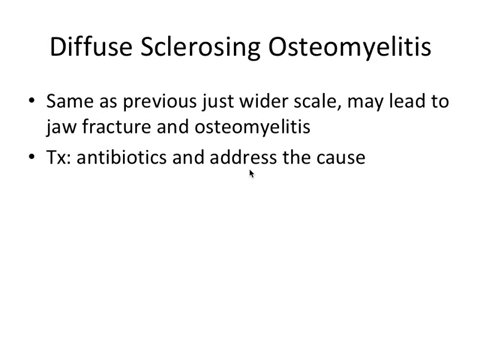
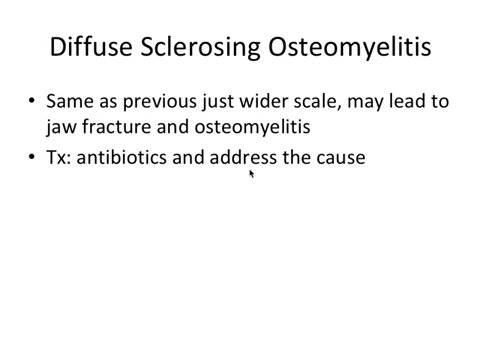
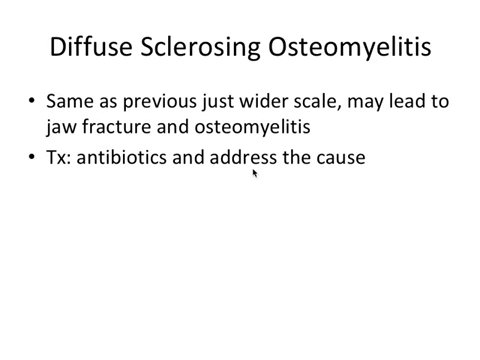
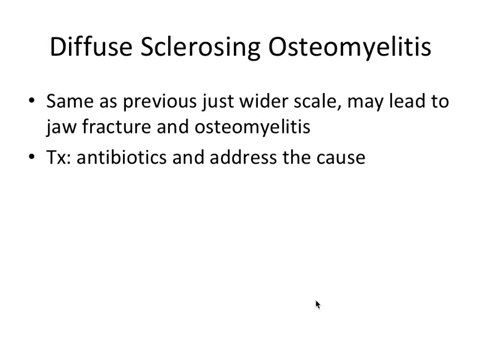
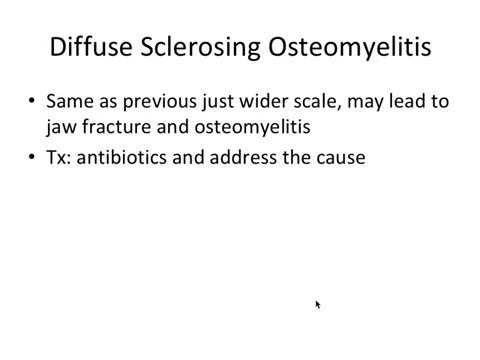
...
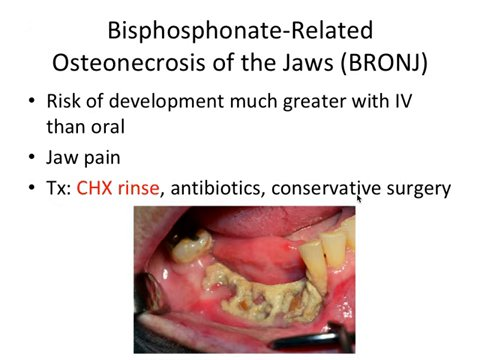
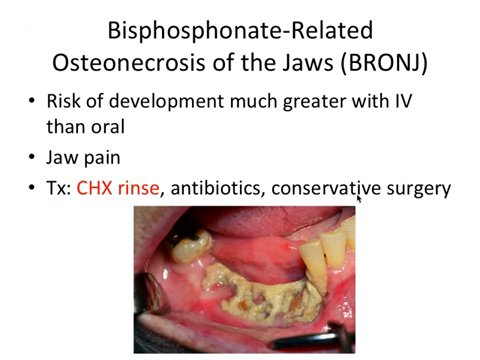
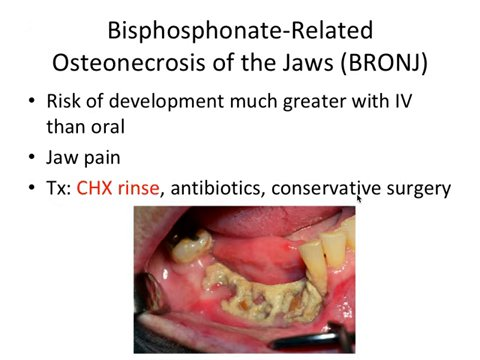
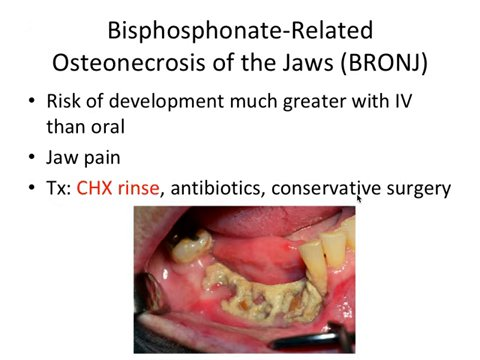
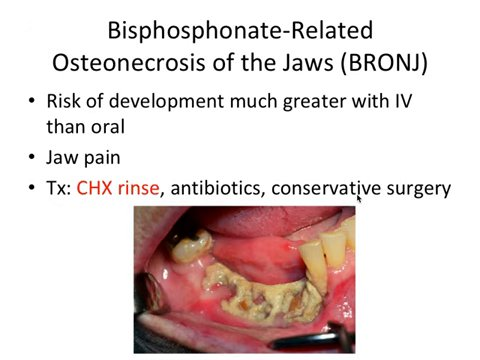

Gallery: 1 / 48 cases; 38 frames



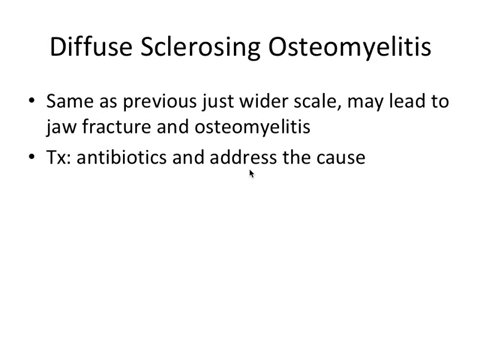
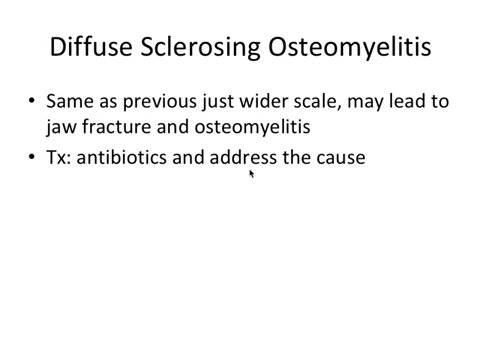
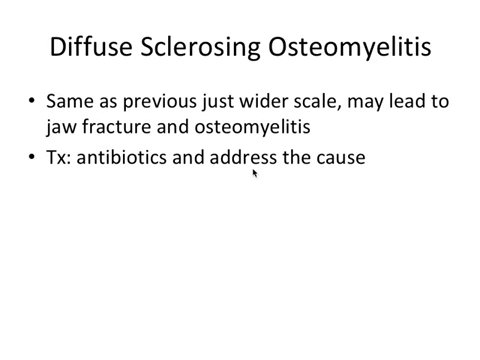
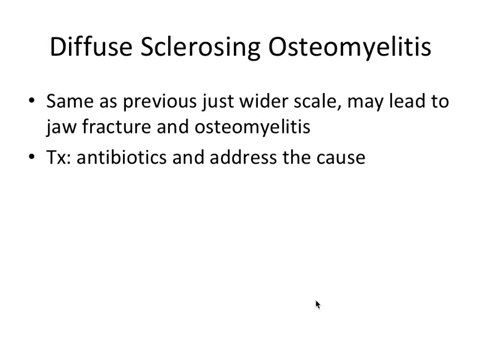
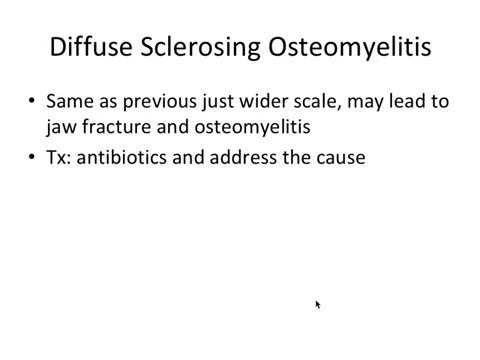
...
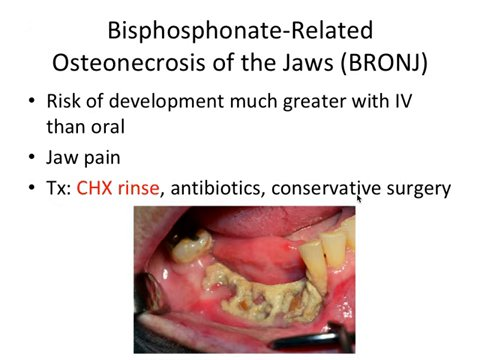
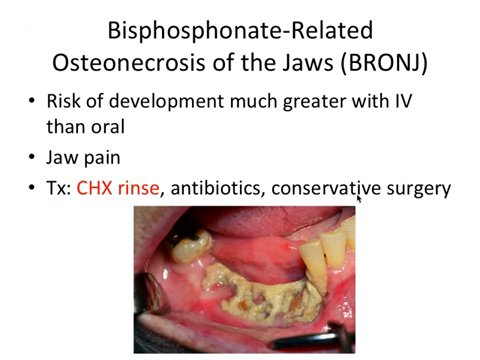
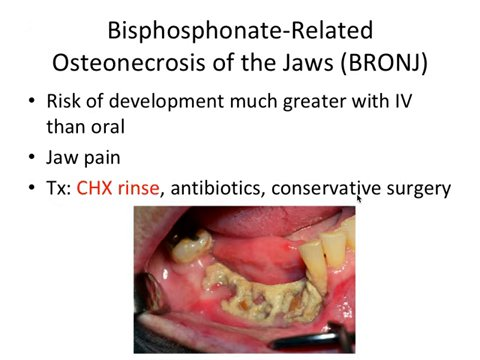
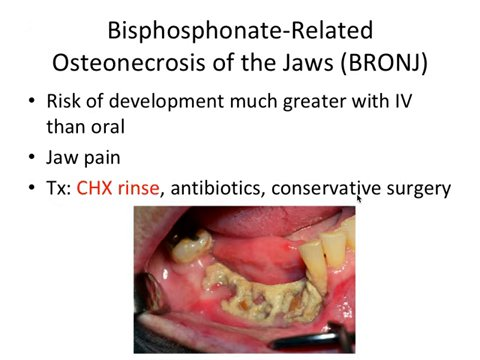
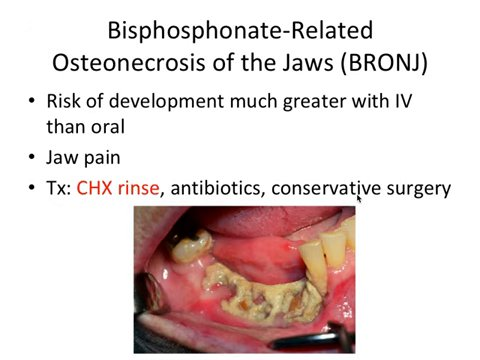

Gallery: 2 / 48 cases; 76 frames



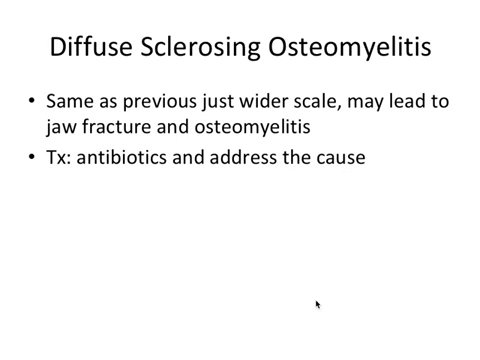
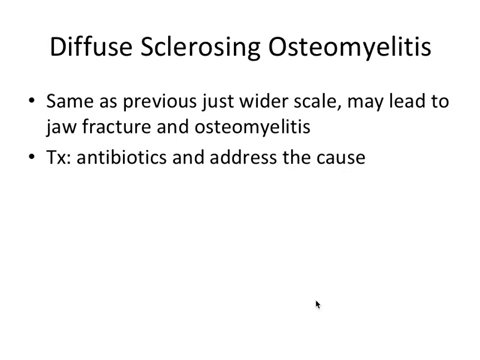
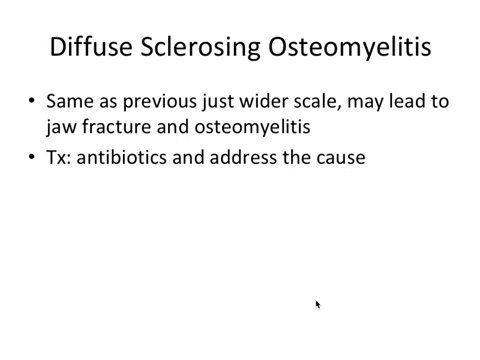
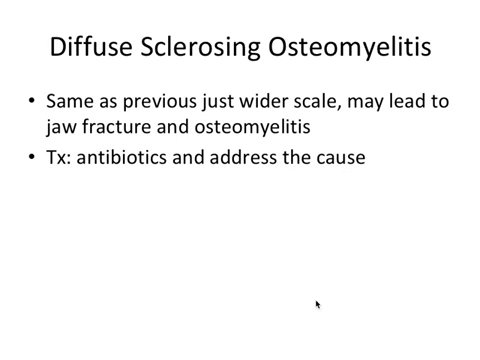
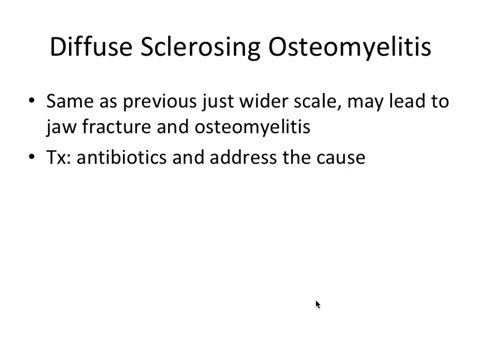
...
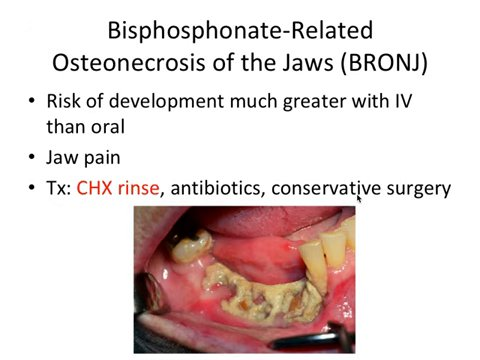
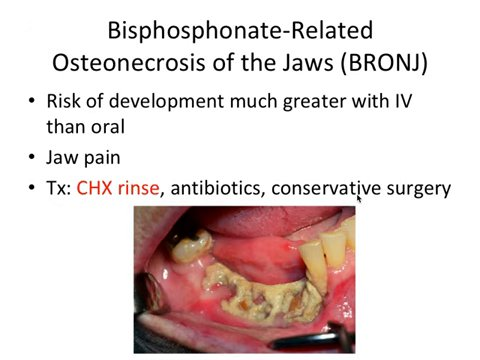
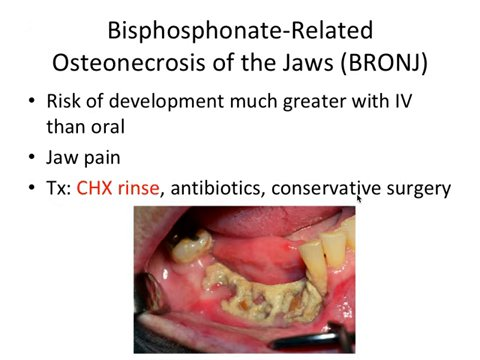
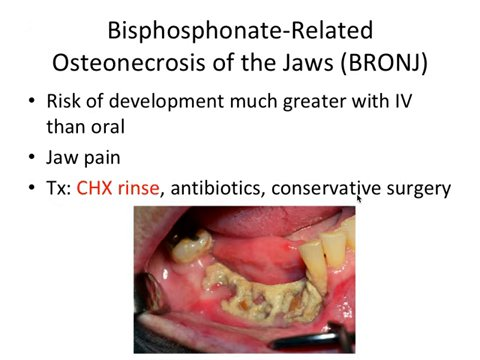
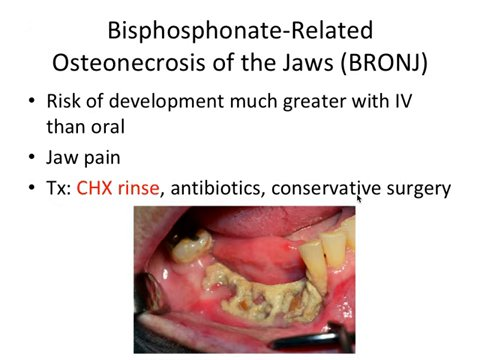

Gallery: 3 / 48 cases; 114 frames



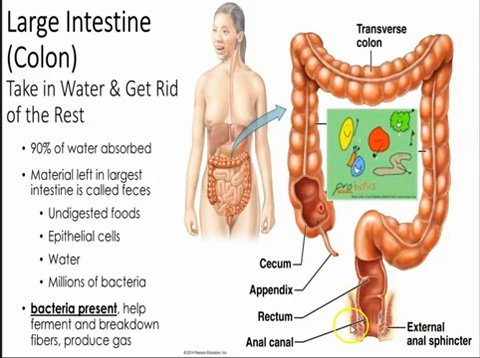
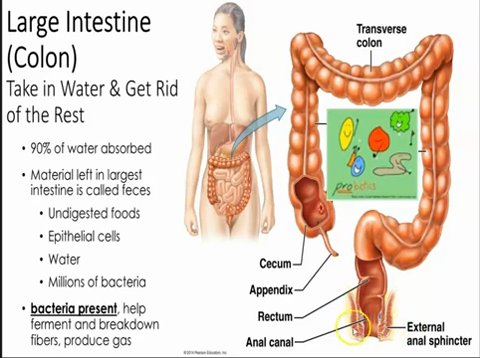
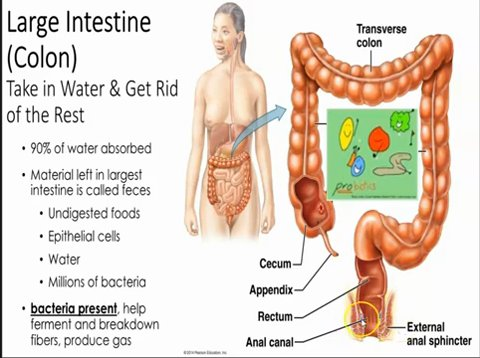
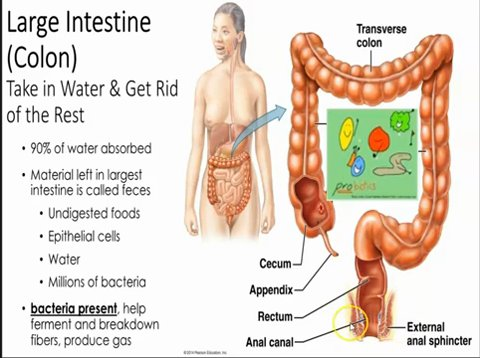
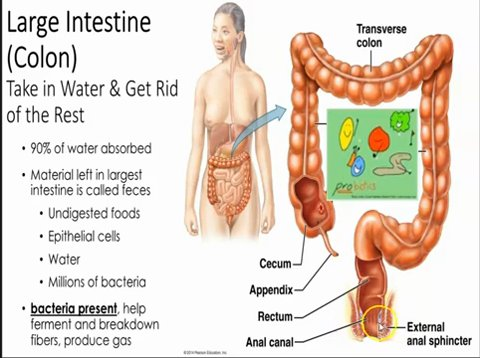
...
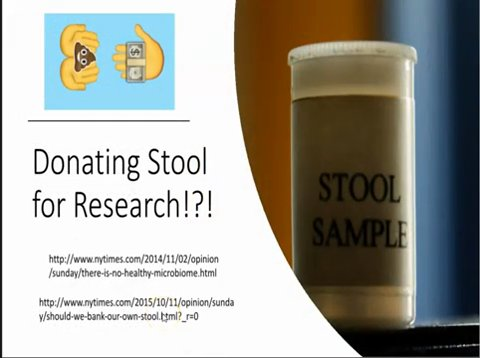
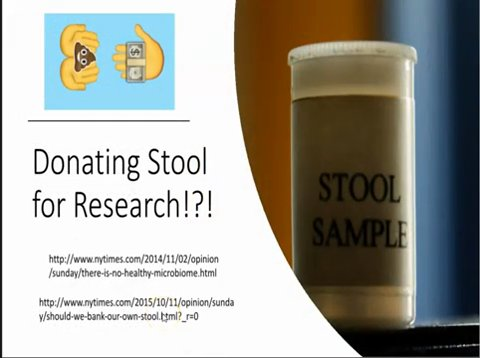
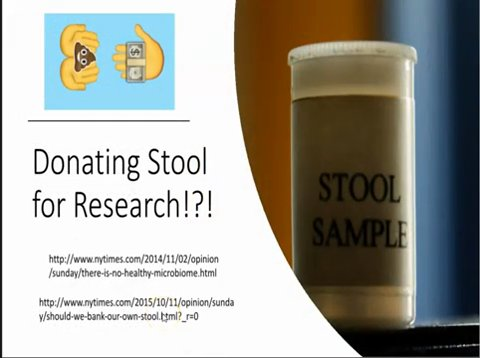
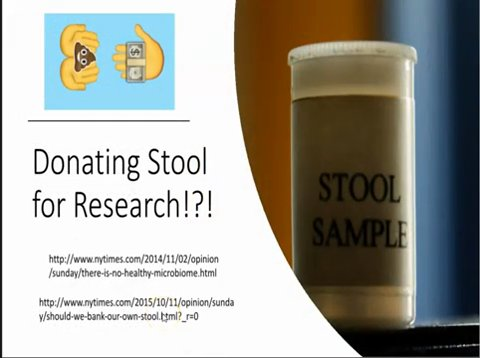
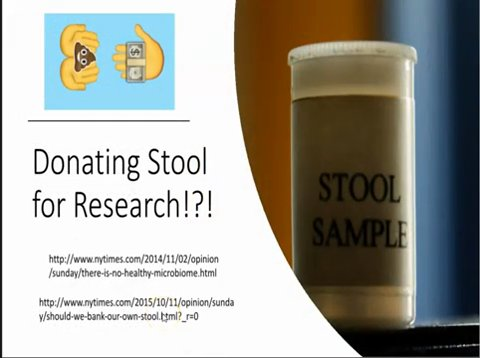

Gallery: 4 / 48 cases; 150 frames



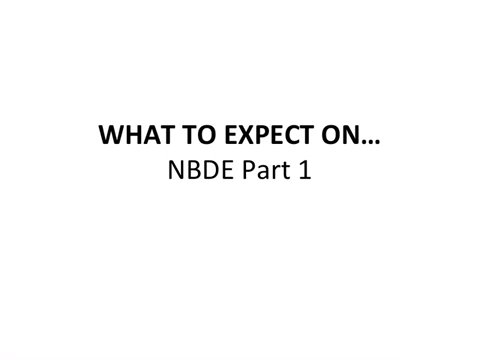
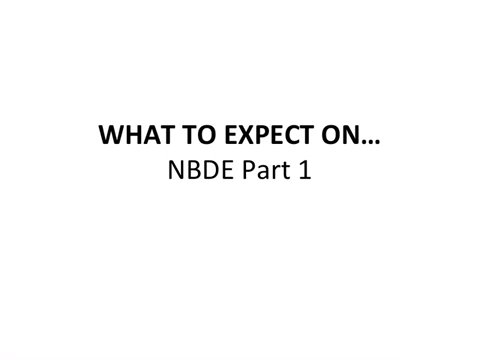
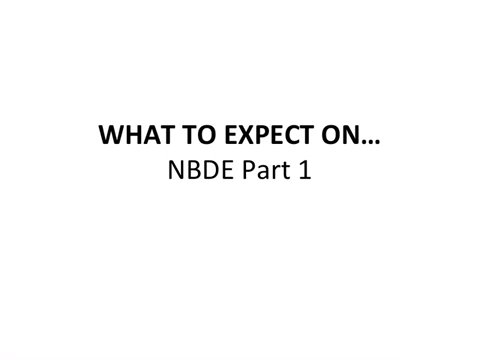
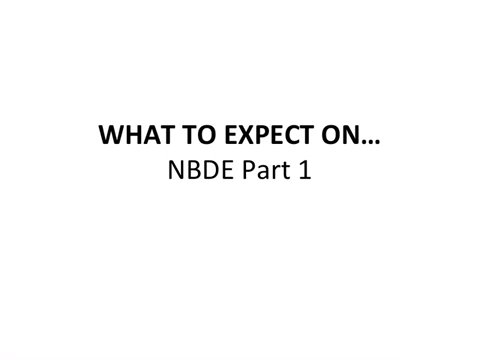
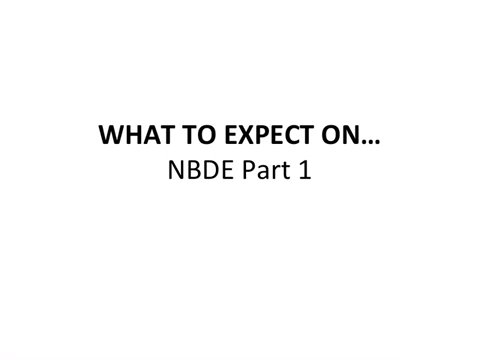
...
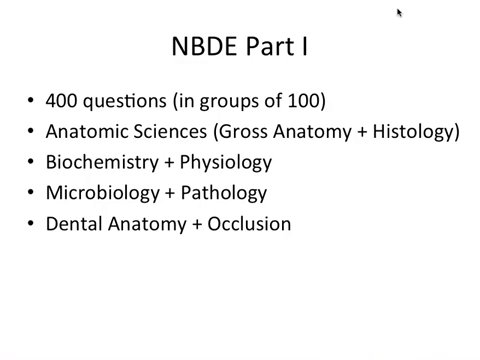
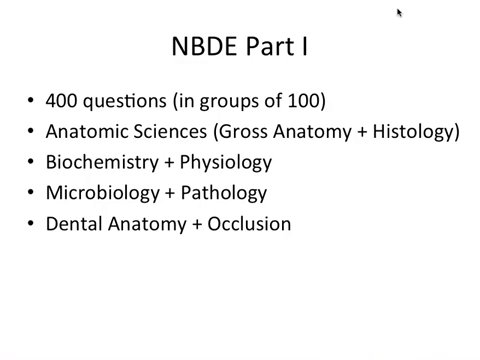
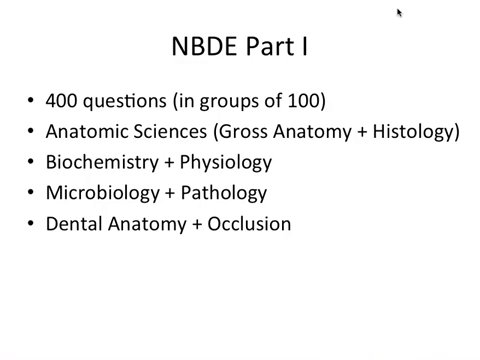
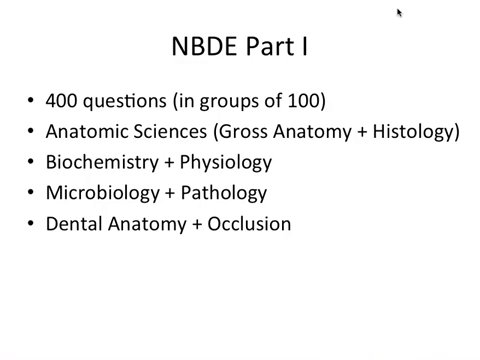
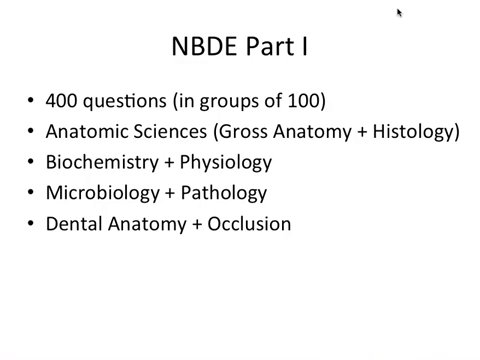

Gallery: 5 / 48 cases; 188 frames



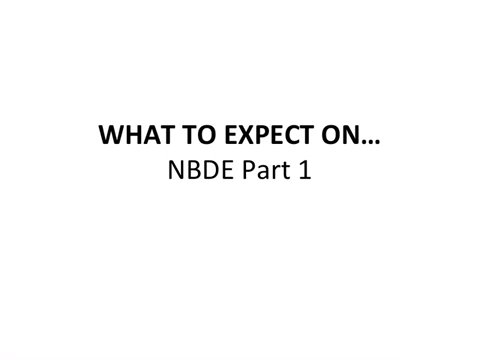
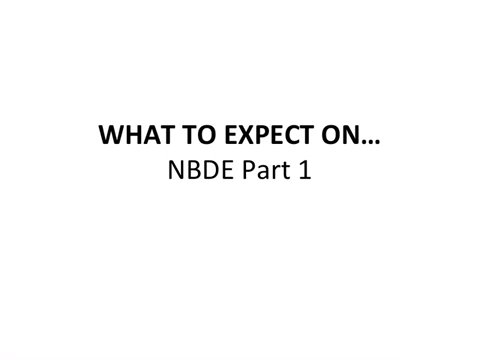
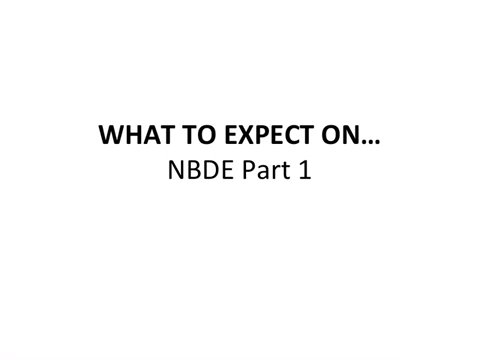
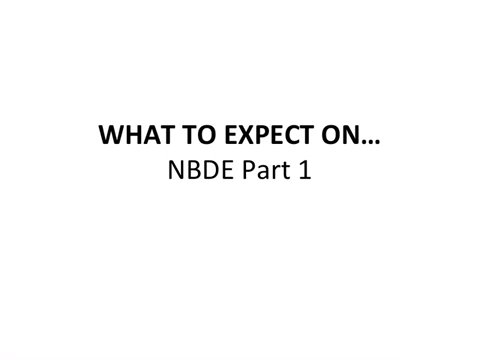
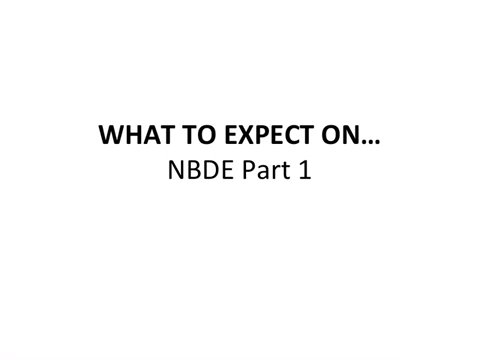
...
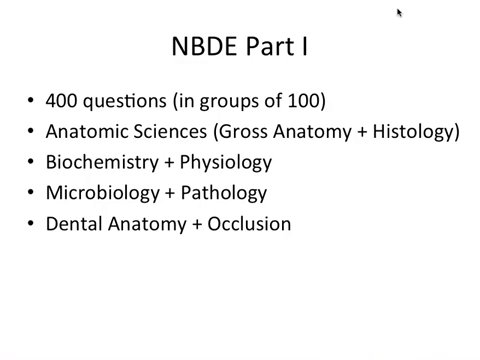
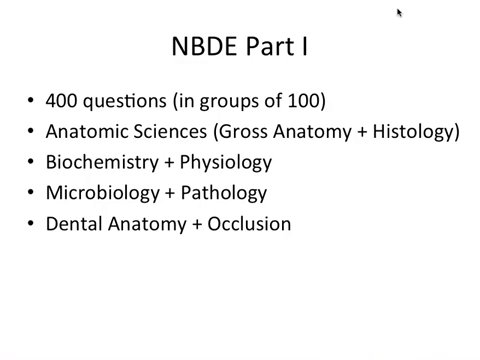
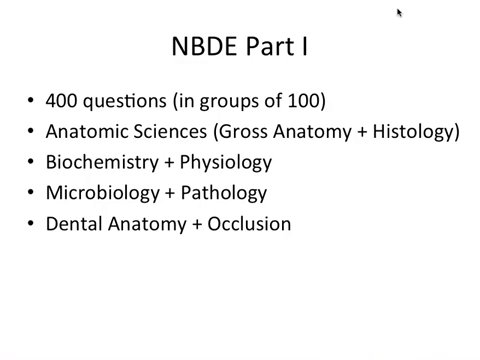
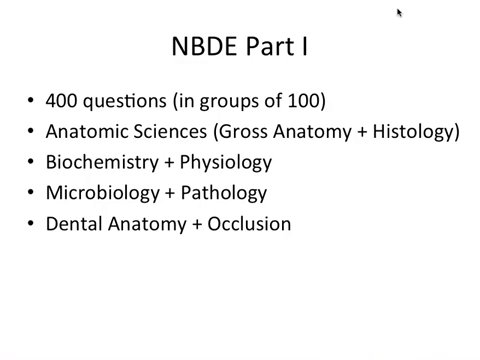
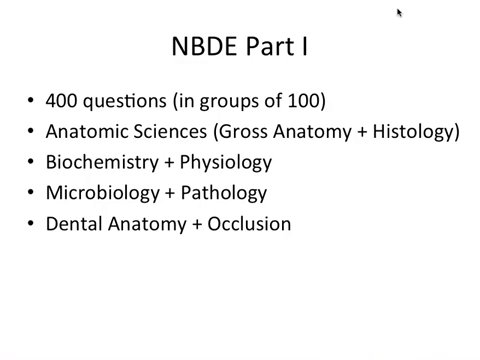

Gallery: 6 / 48 cases; 226 frames



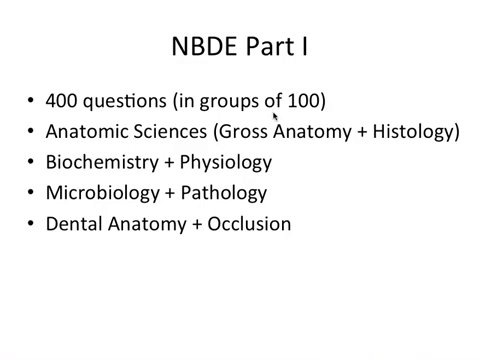
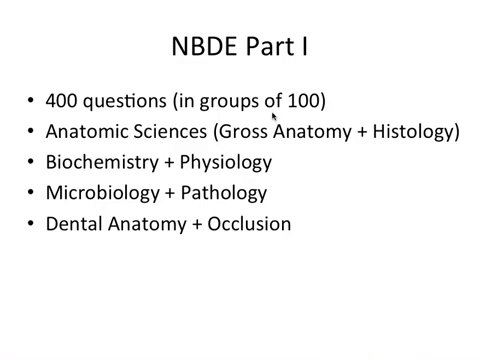
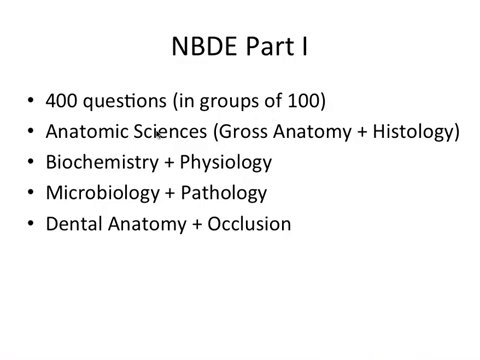
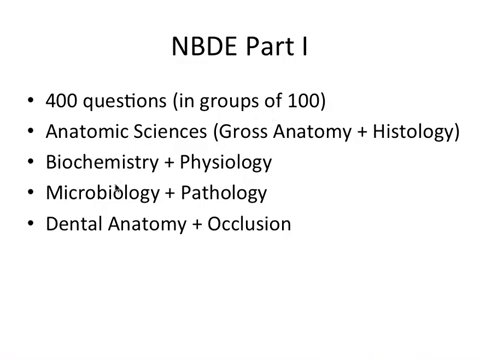
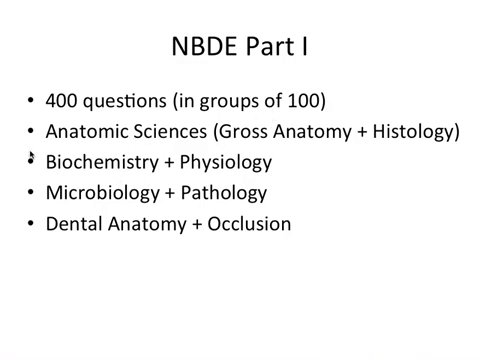
...
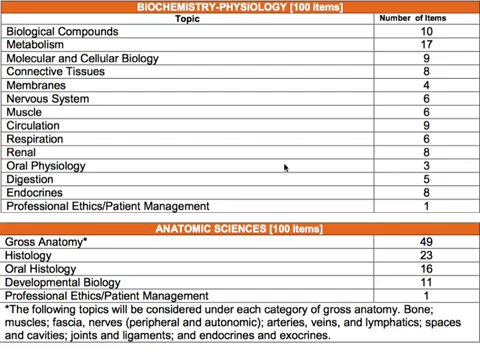
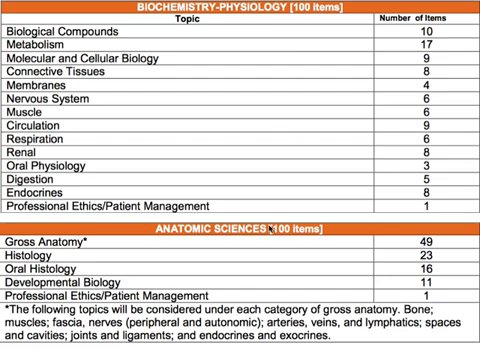
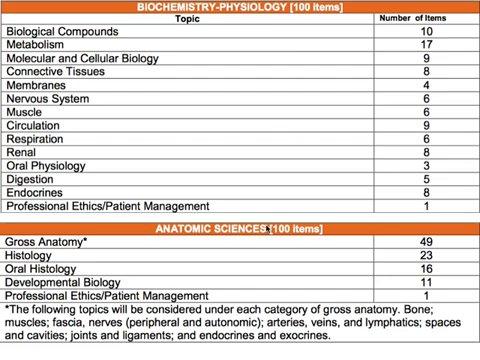
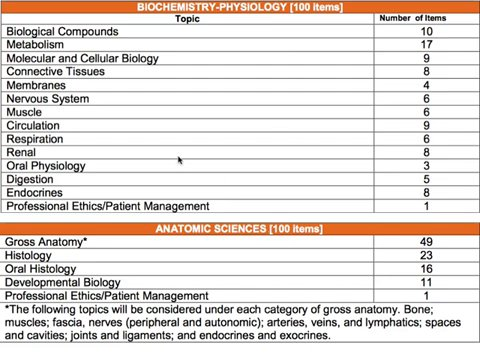
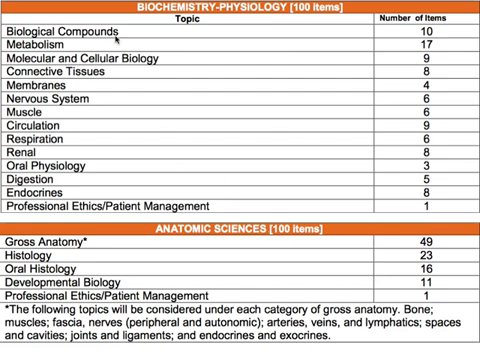

Gallery: 7 / 48 cases; 264 frames



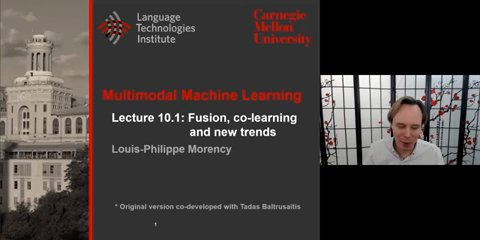
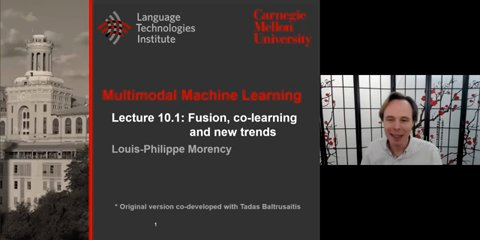
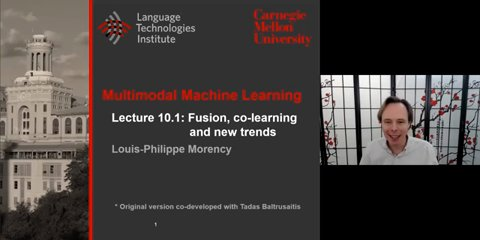
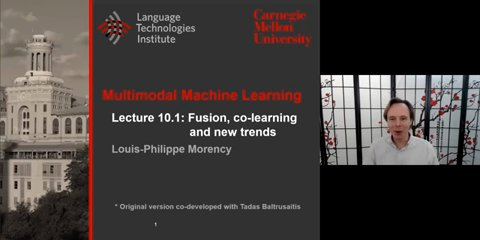
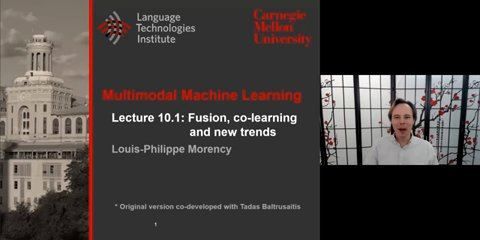
...
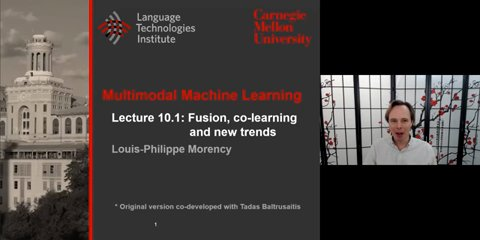
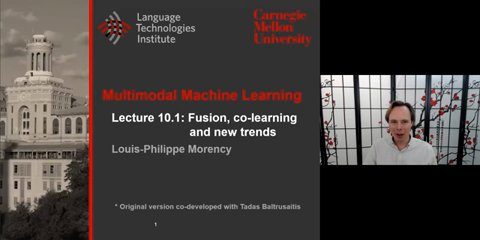
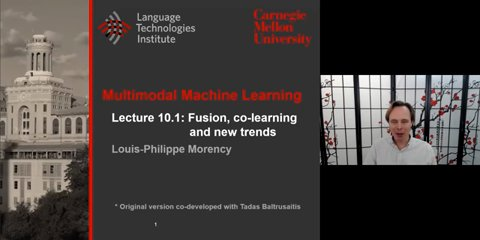
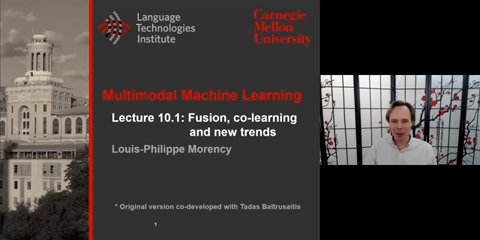
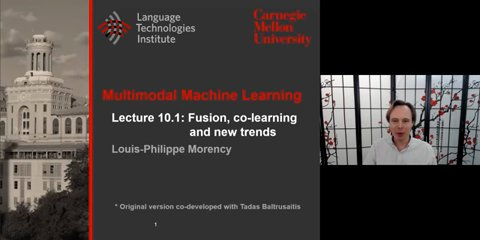

Gallery: 8 / 48 cases; 298 frames



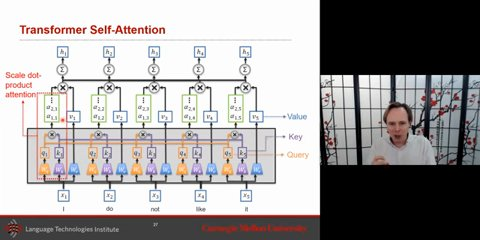
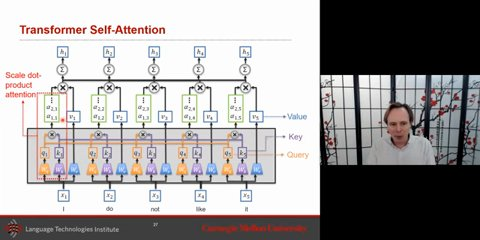
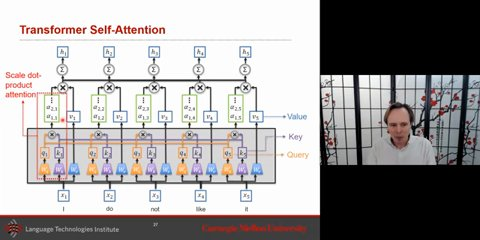
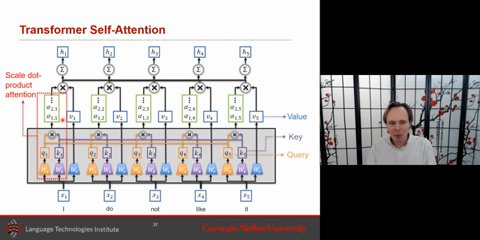
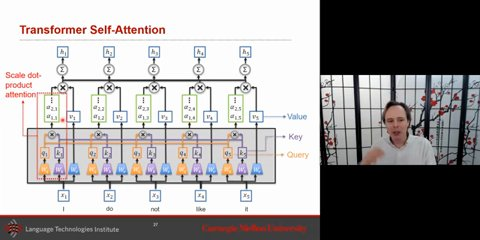
...
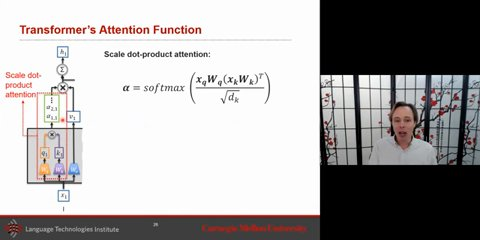
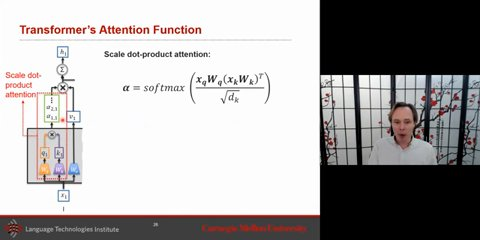
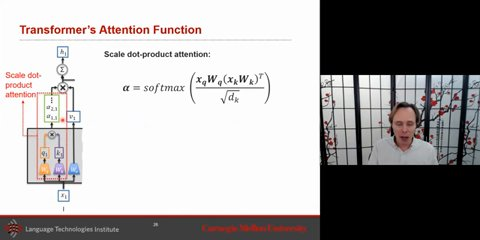
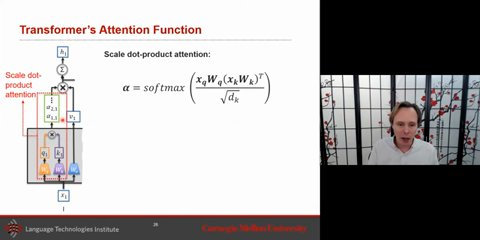
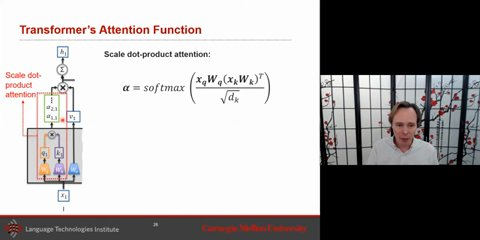

Gallery: 9 / 48 cases; 334 frames



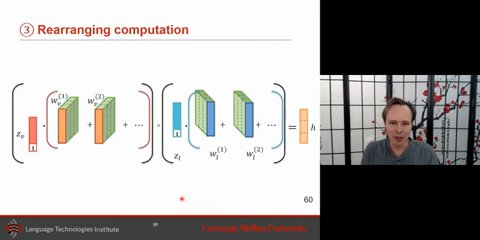
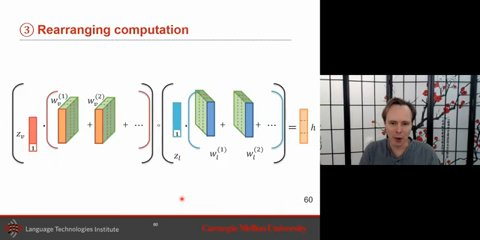
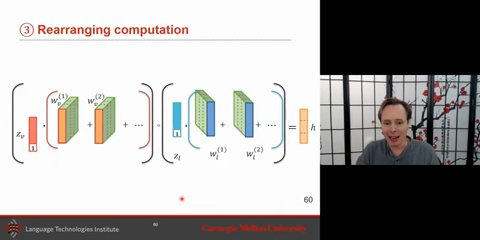
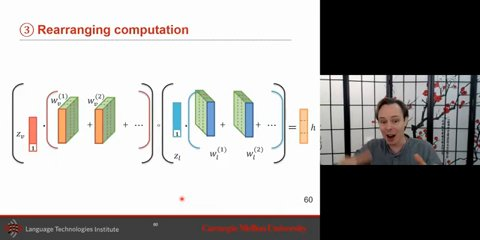
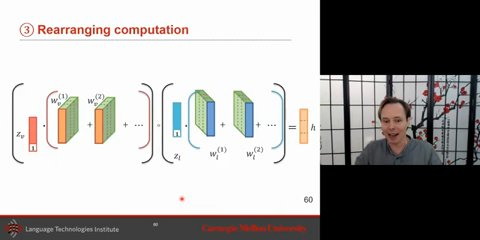
...
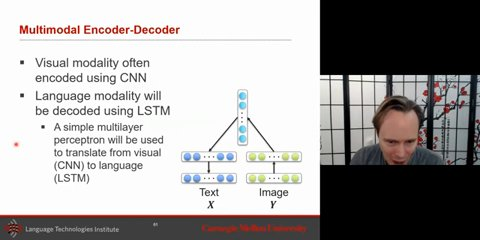
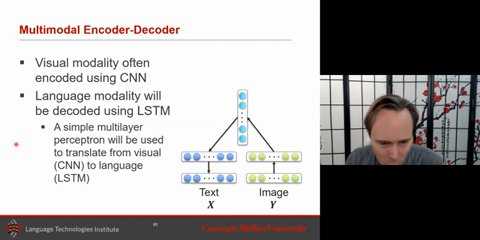
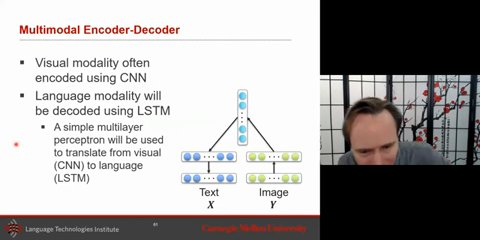
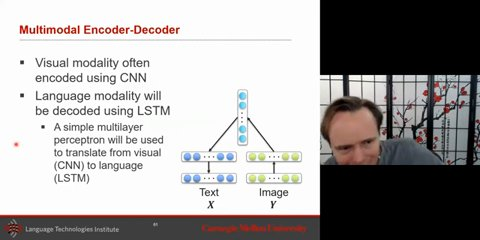
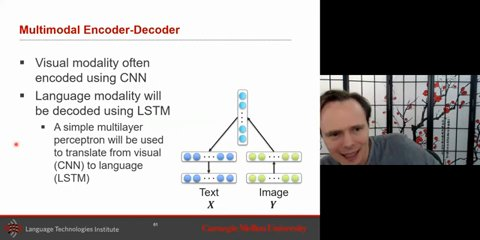

Gallery: 10 / 48 cases; 372 frames



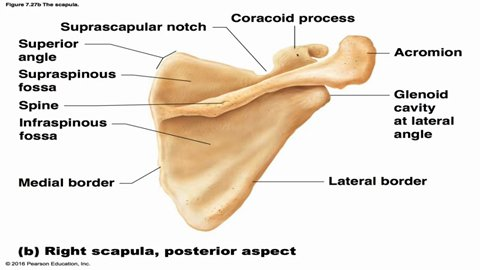
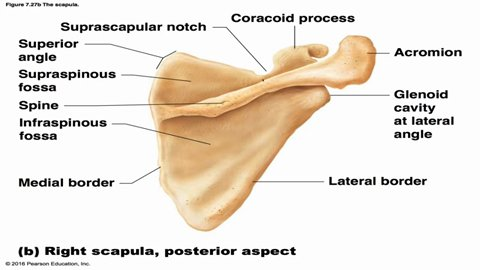
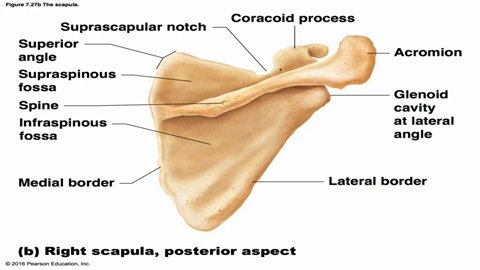
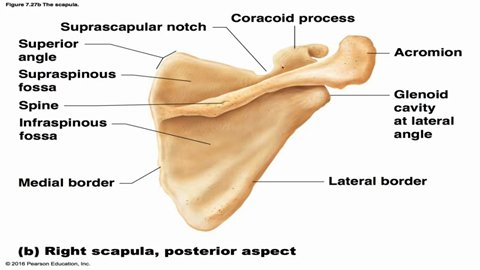
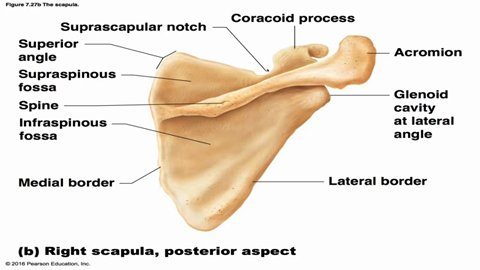
...
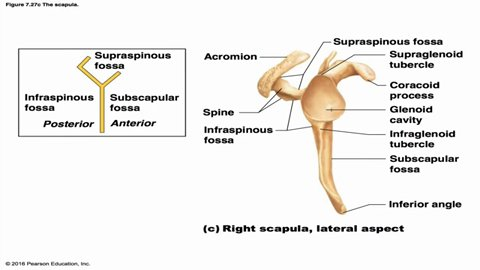
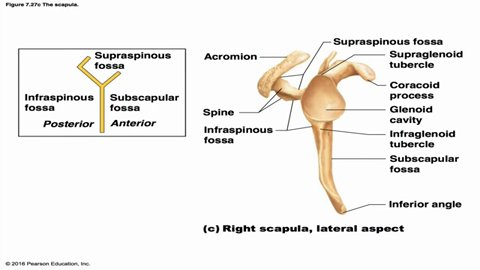
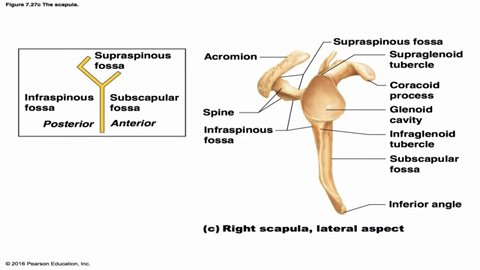
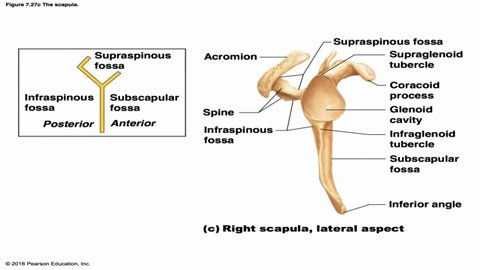
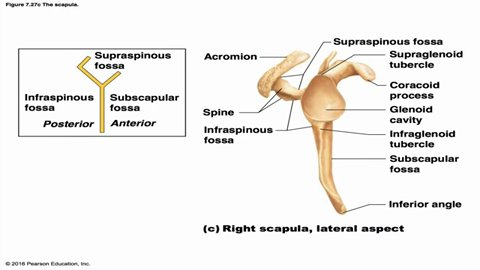

Gallery: 11 / 48 cases; 410 frames



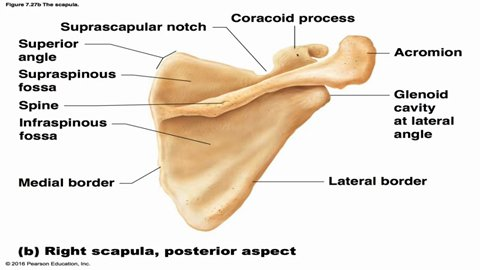
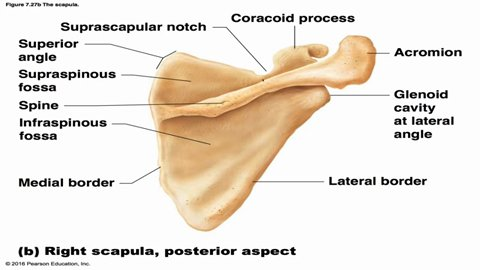
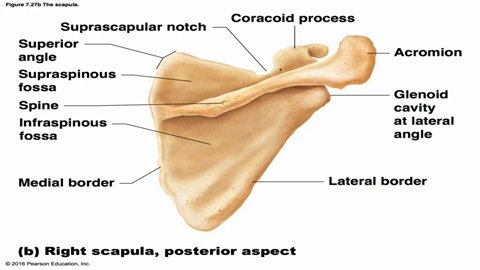
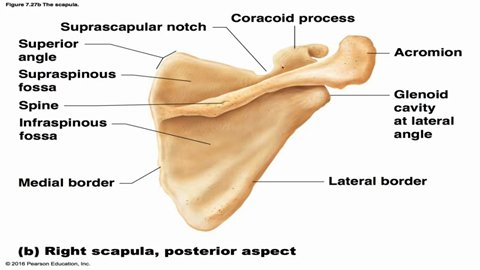
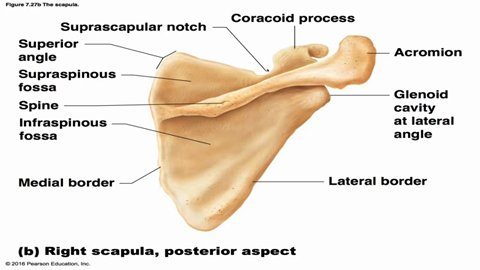
...
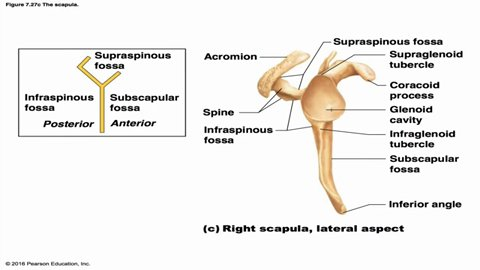
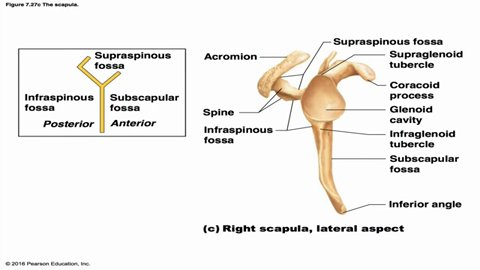
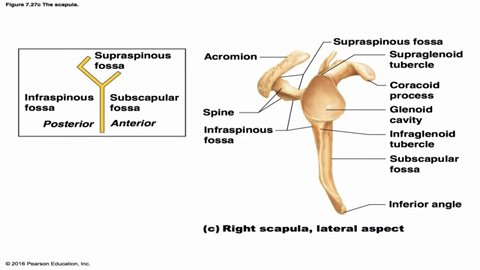
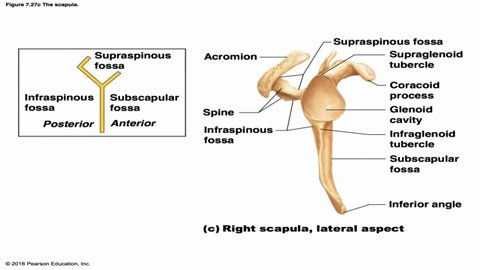
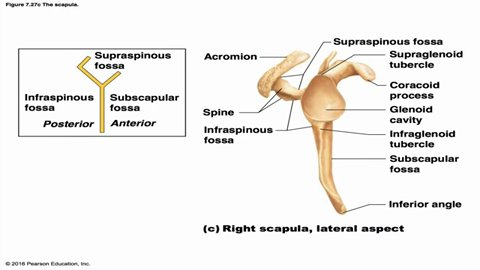

Gallery: 12 / 48 cases; 448 frames



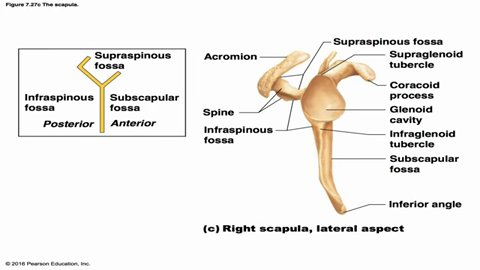
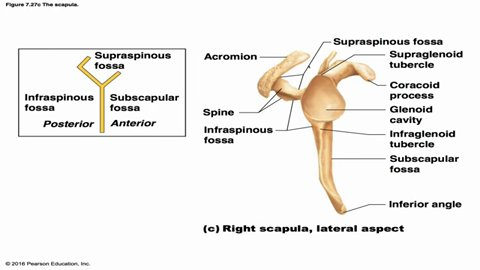
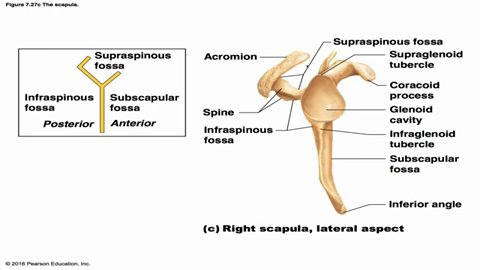
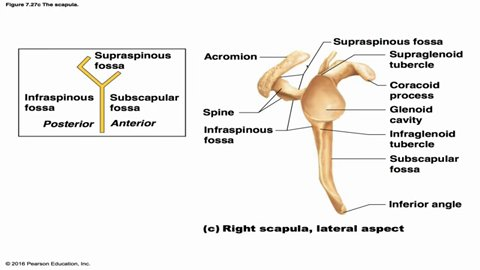
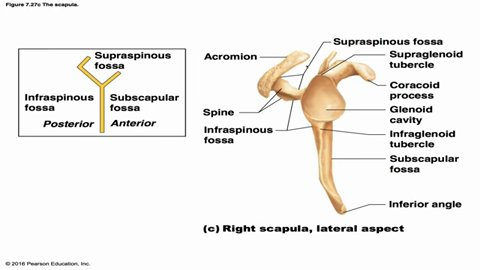
...
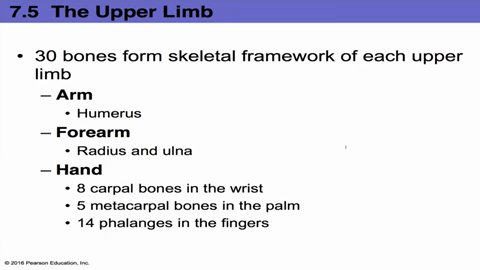
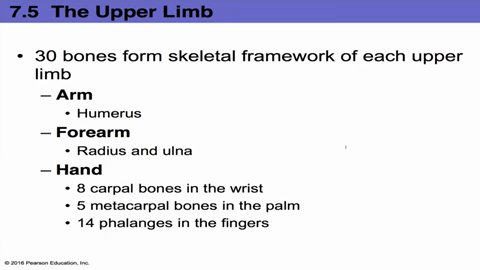
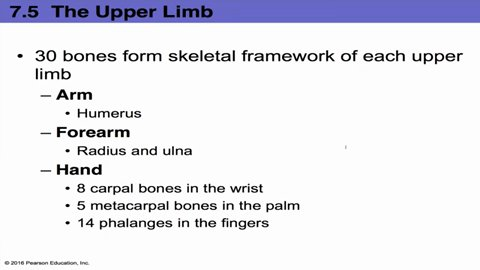
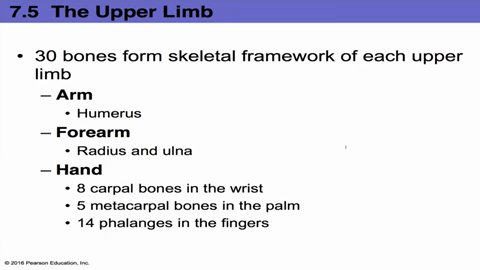
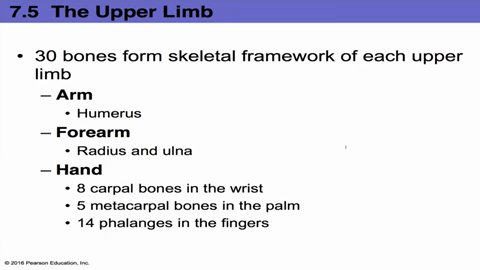

Gallery: 13 / 48 cases; 486 frames



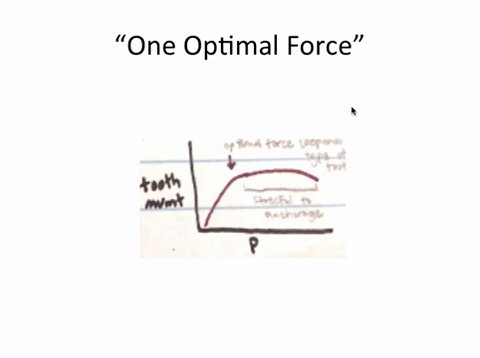
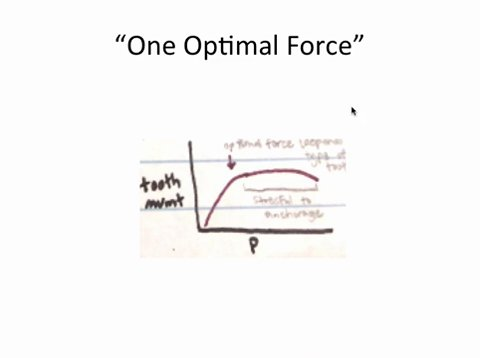
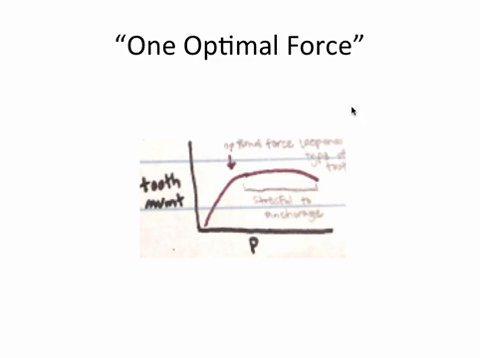
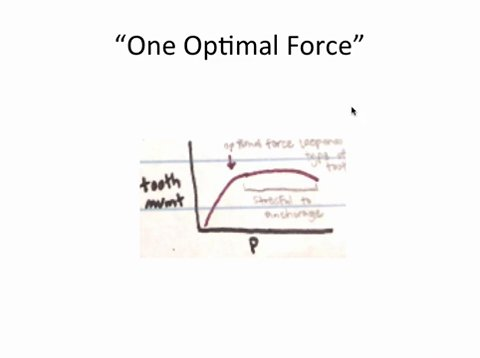
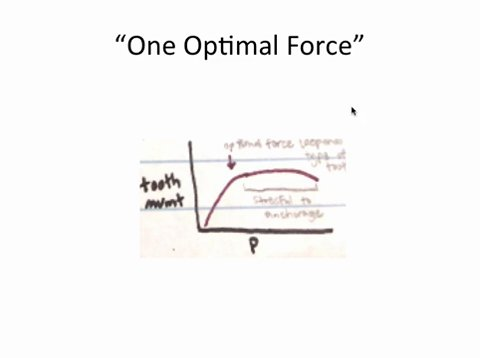
...
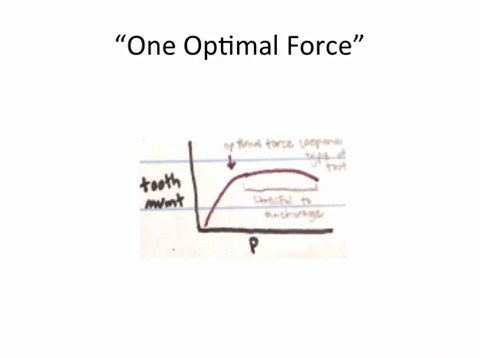
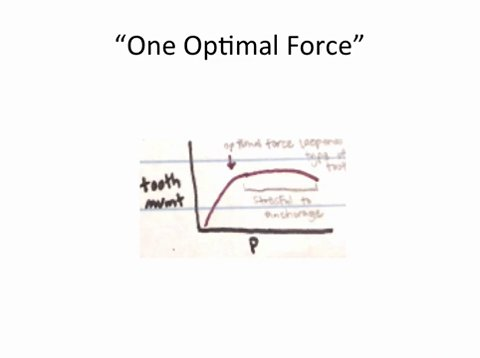
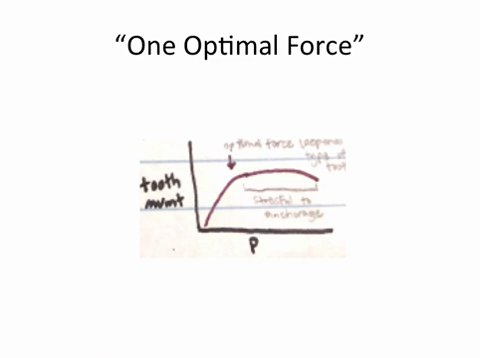
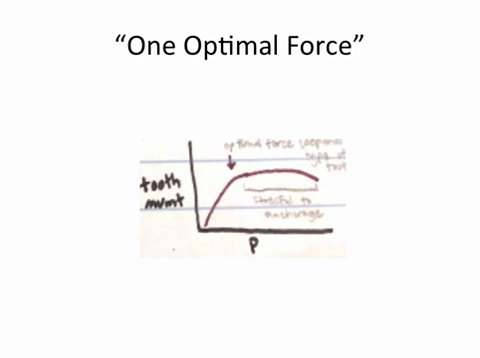
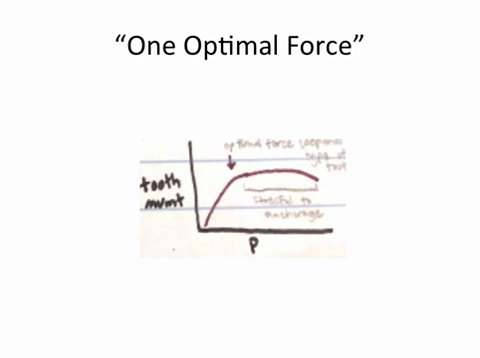

Gallery: 14 / 48 cases; 509 frames



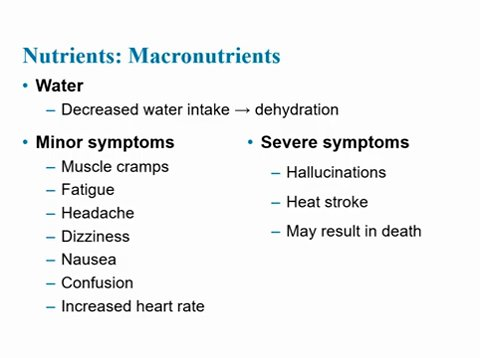
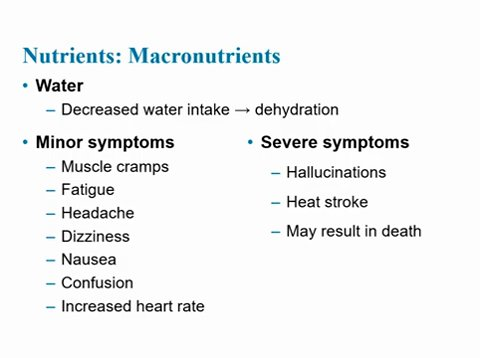
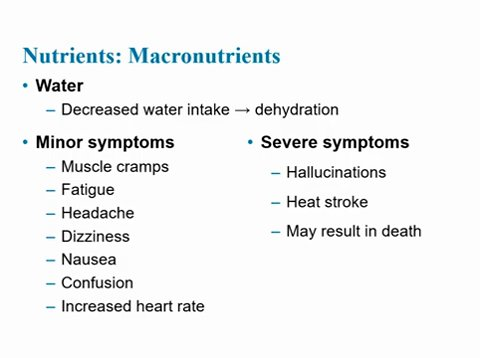
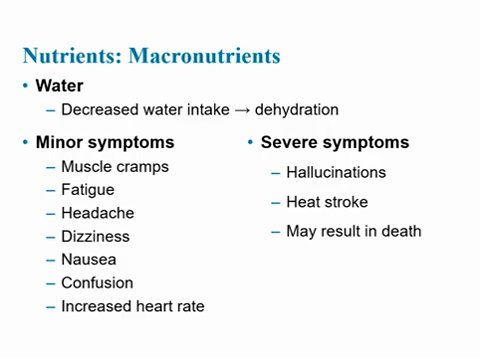
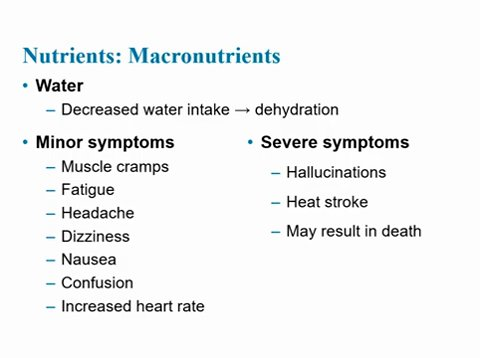
...
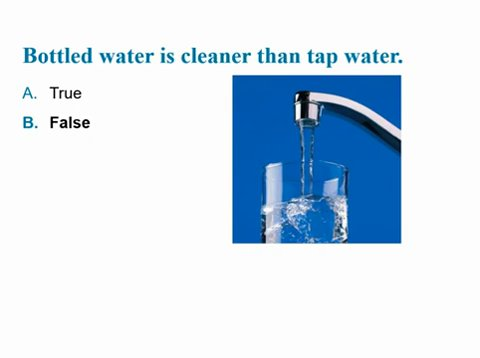
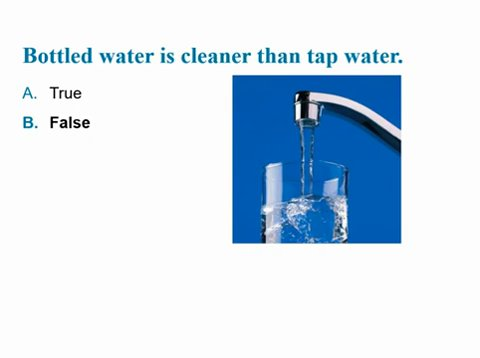
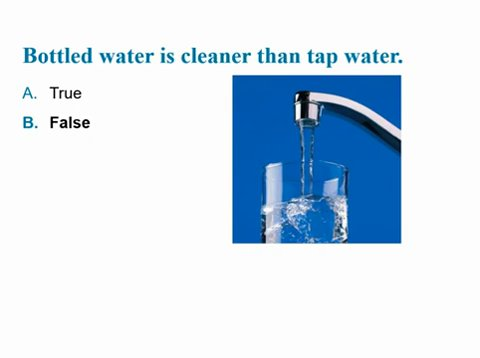
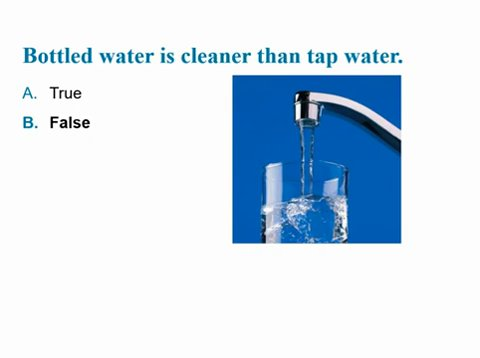
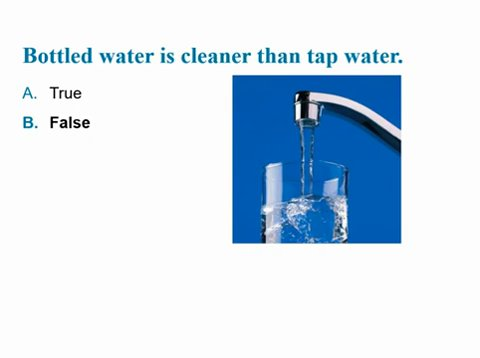

Gallery: 15 / 48 cases; 545 frames



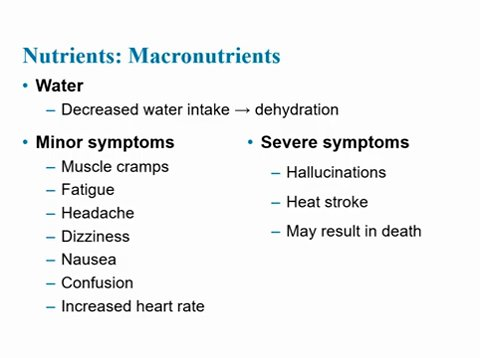
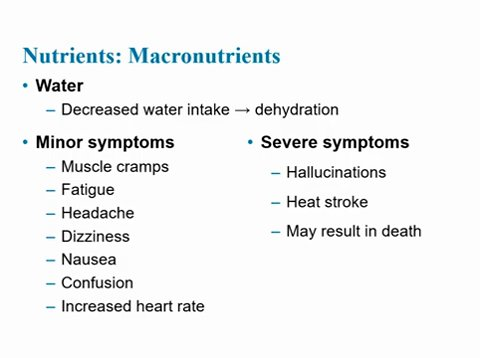
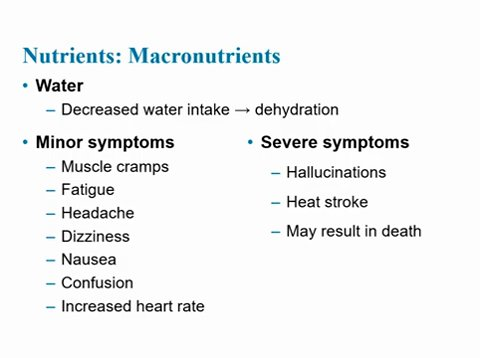
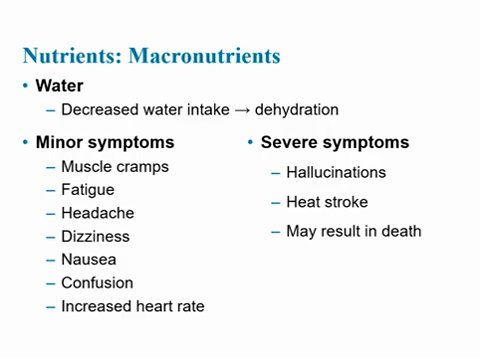
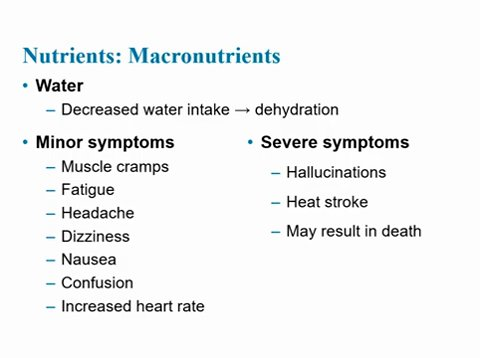
...
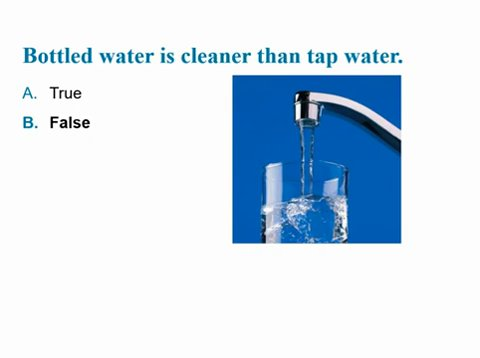
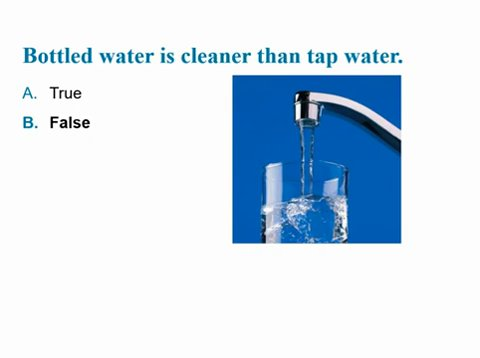
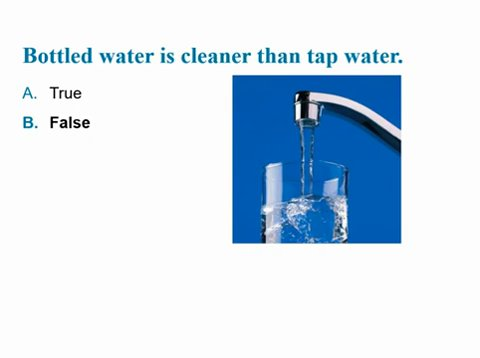
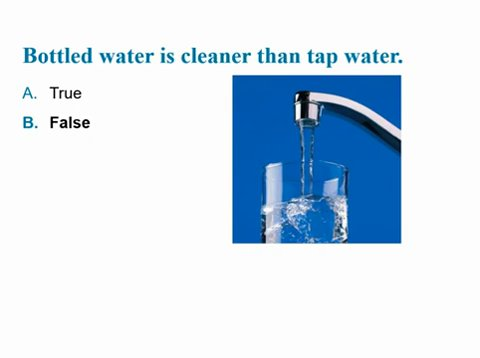
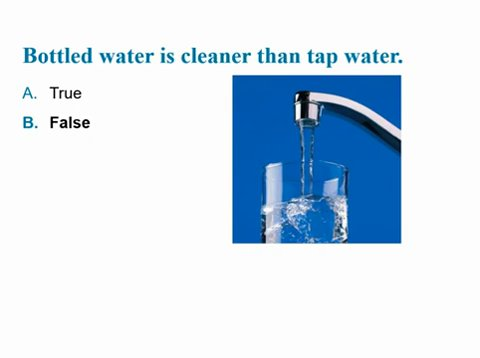

Gallery: 16 / 48 cases; 581 frames



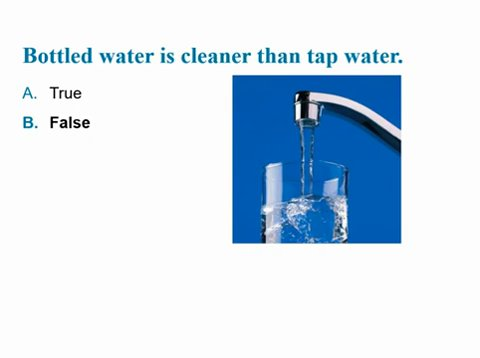
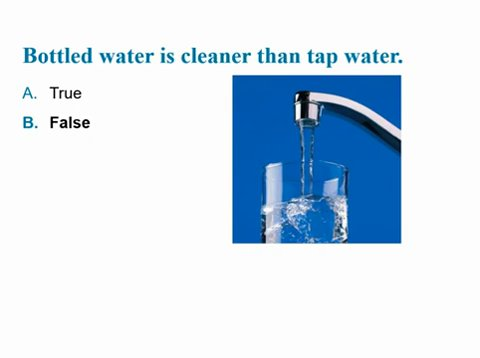
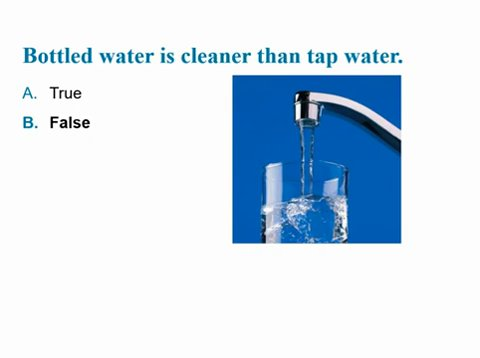
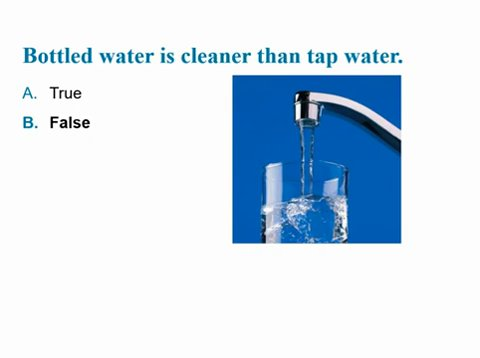
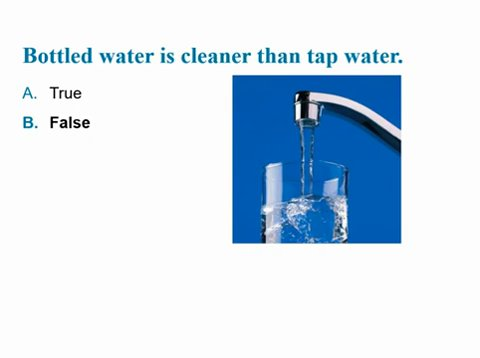
...
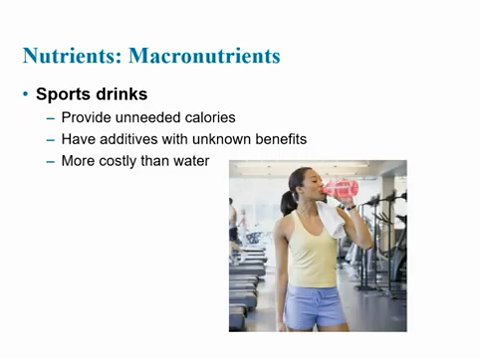
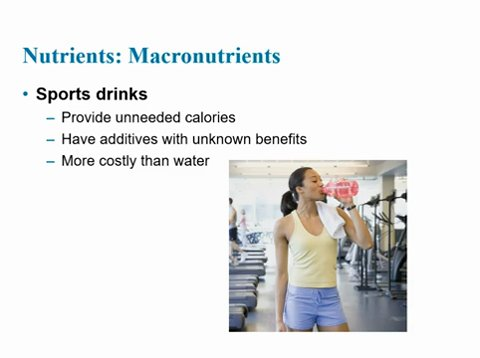
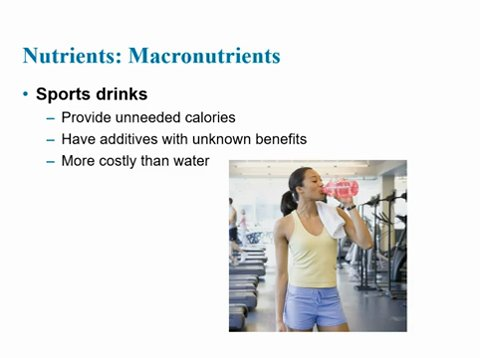
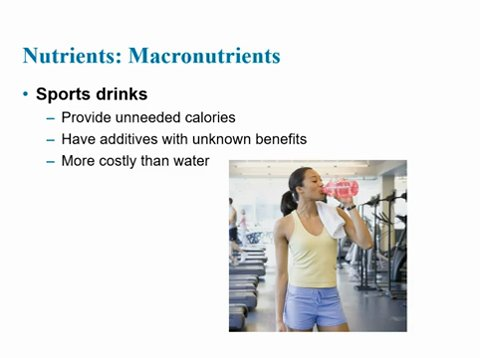
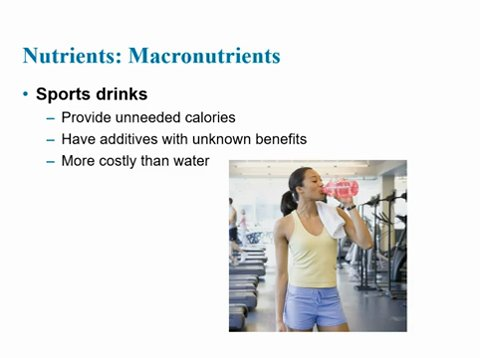

Gallery: 17 / 48 cases; 617 frames



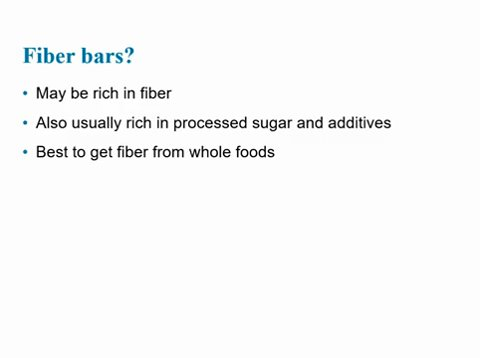
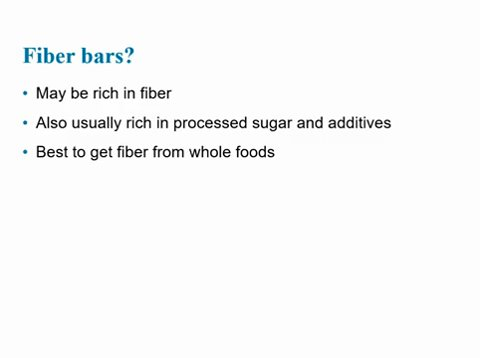
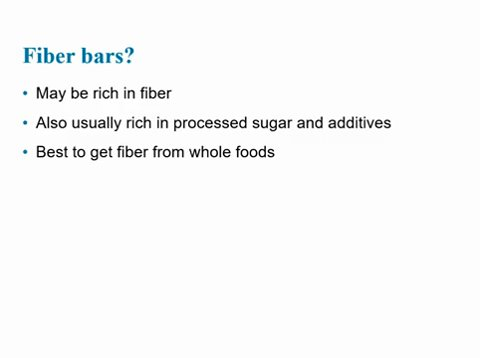
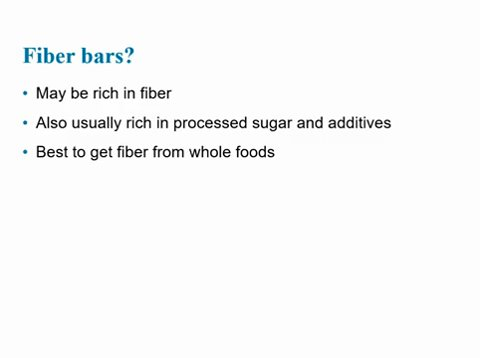
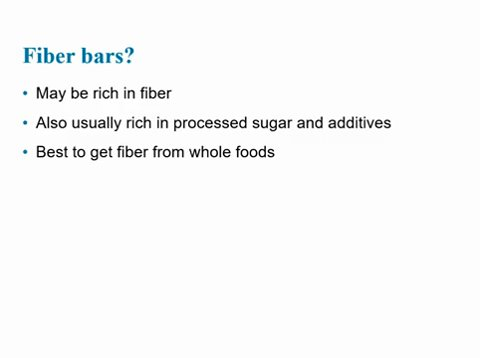
...
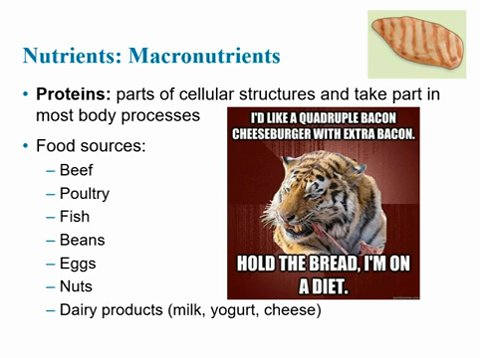
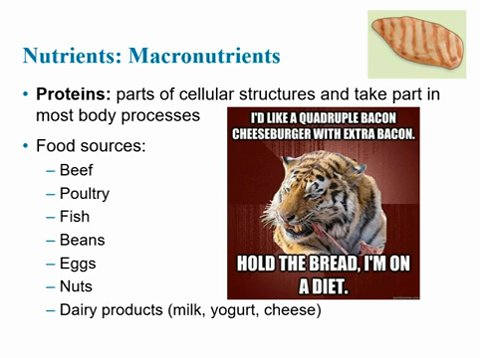
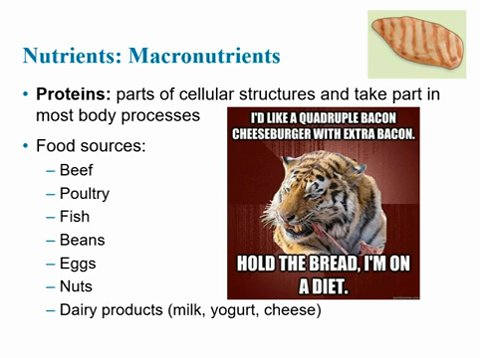
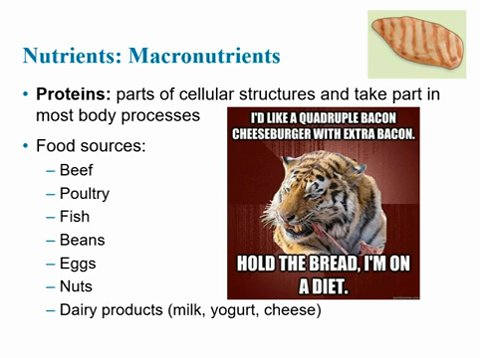
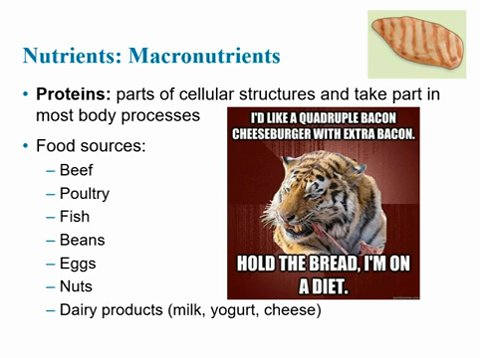

Gallery: 18 / 48 cases; 653 frames



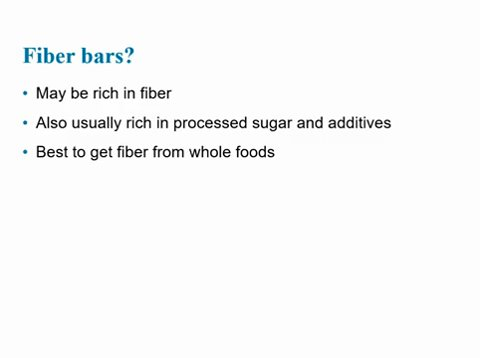
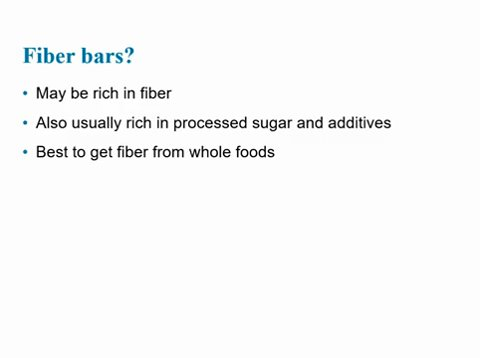
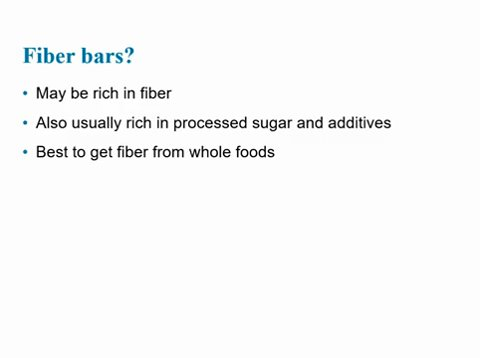
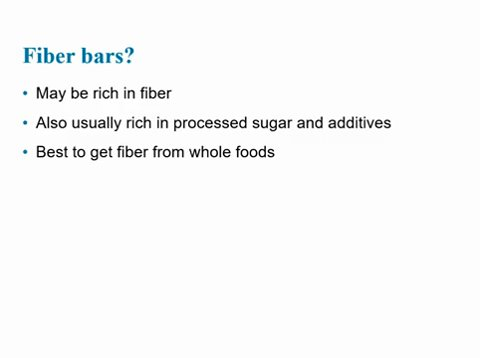
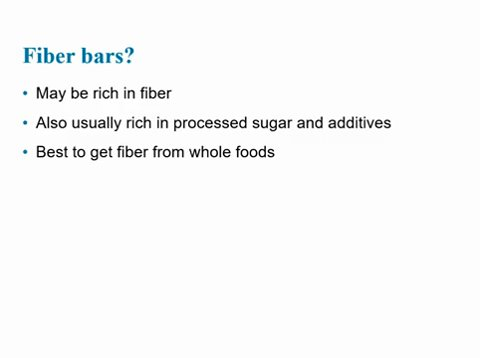
...
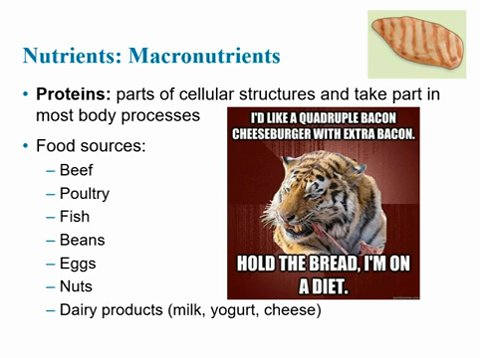
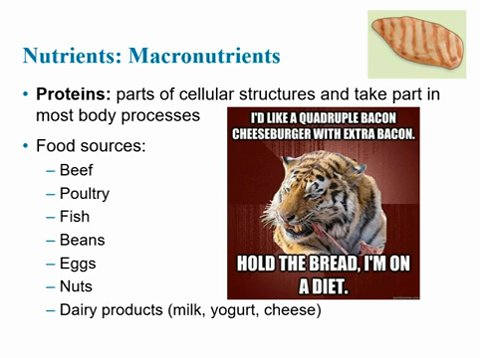
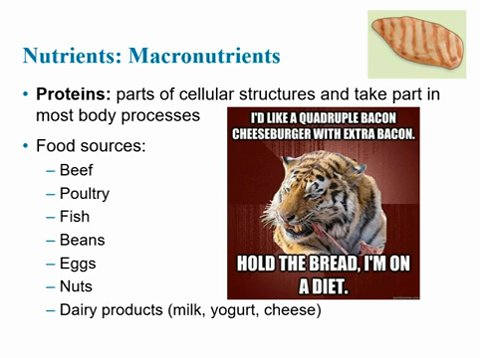
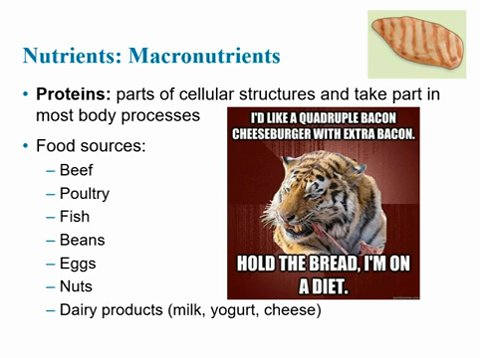
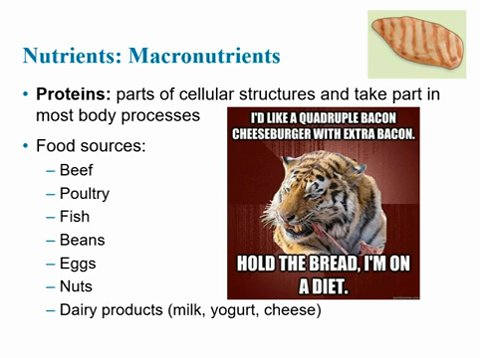

Gallery: 19 / 48 cases; 689 frames



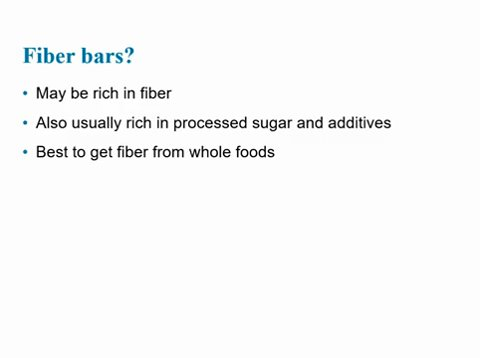
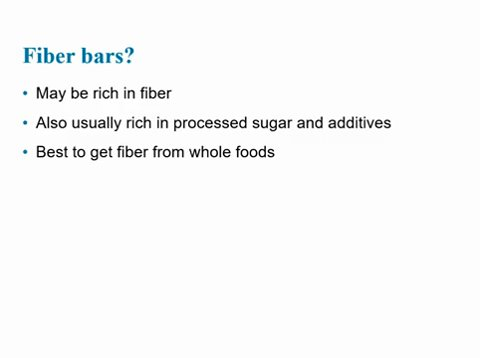
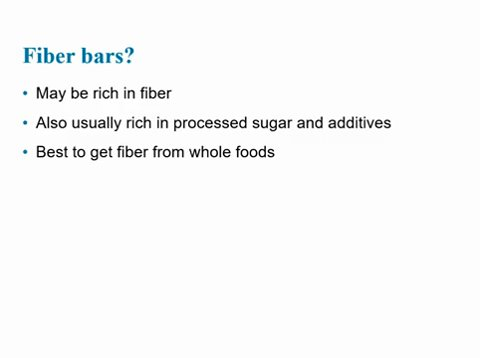
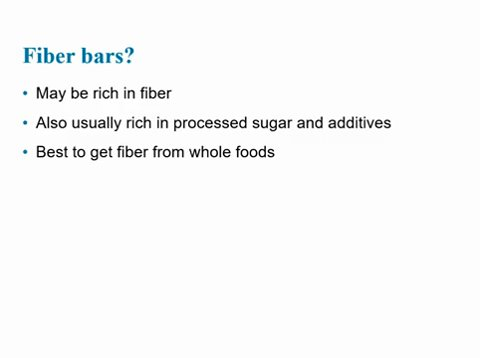
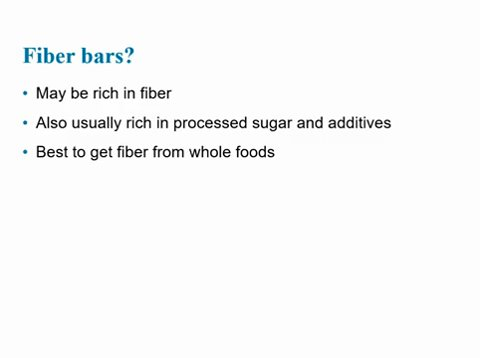
...
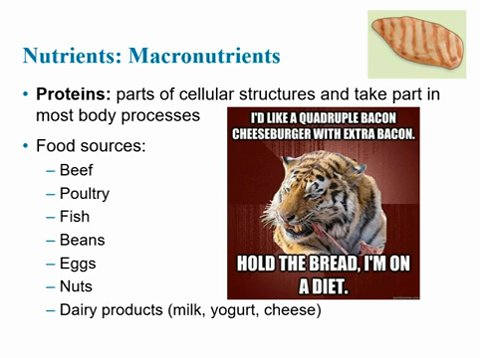
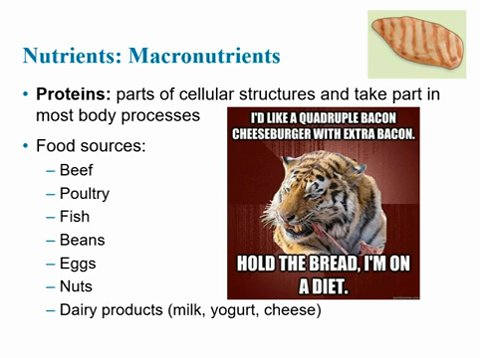
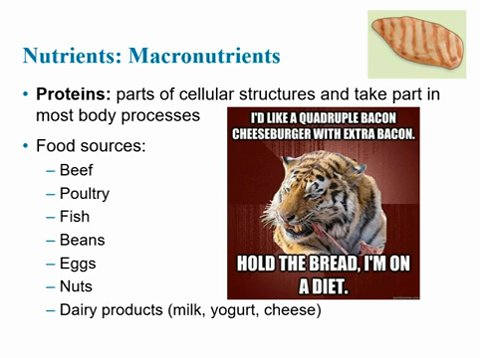
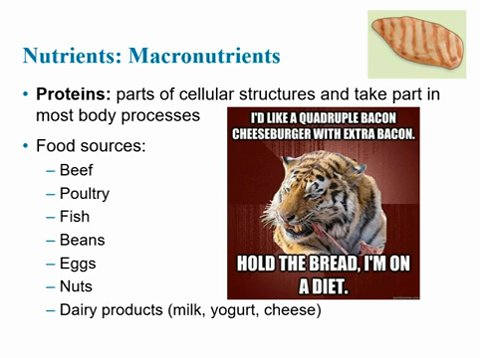
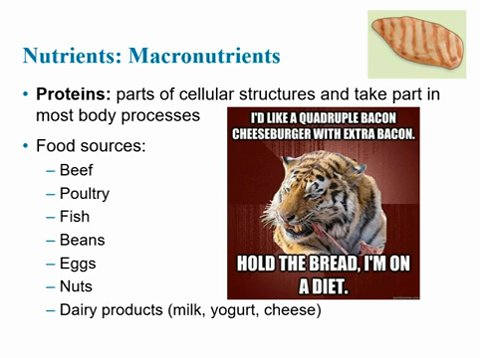

Gallery: 20 / 48 cases; 725 frames



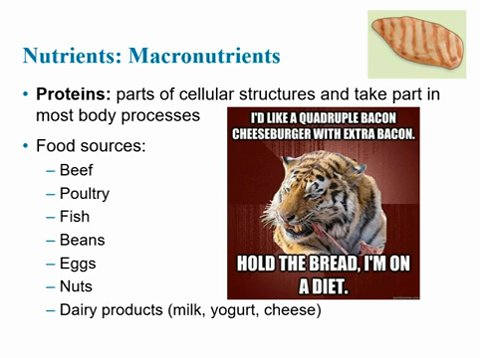
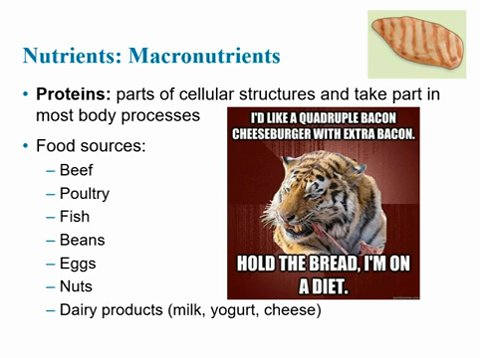
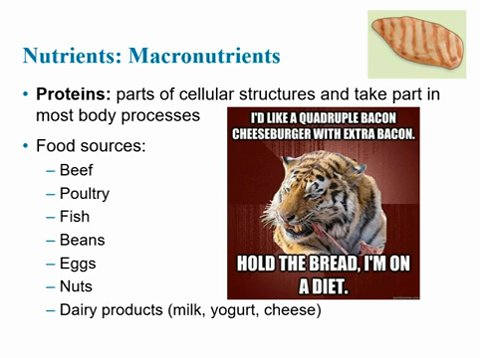
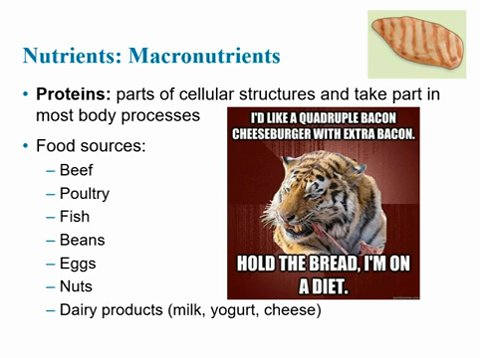
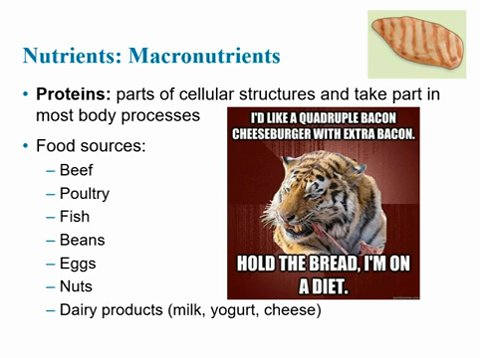
...
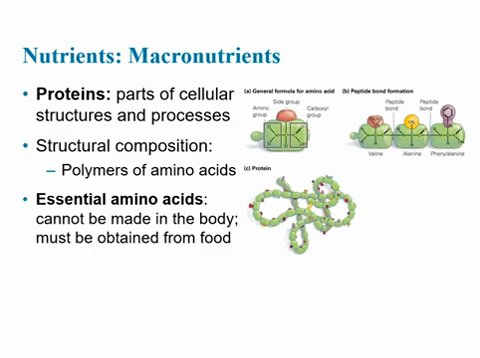
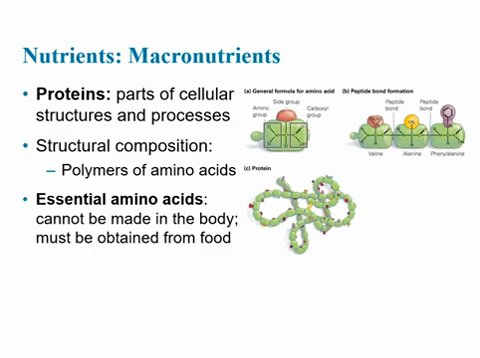
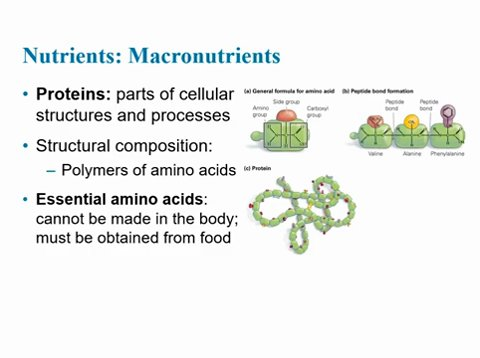
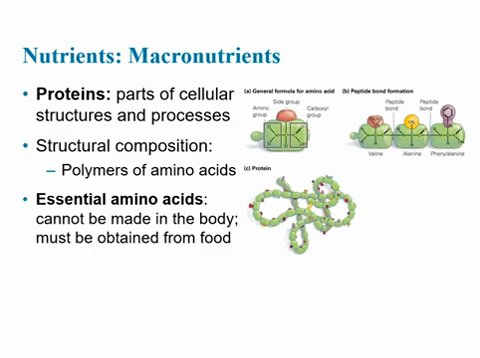
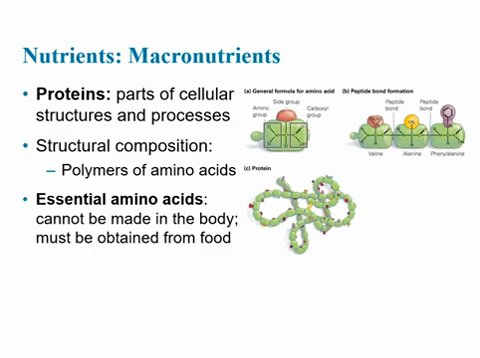

Gallery: 21 / 48 cases; 761 frames



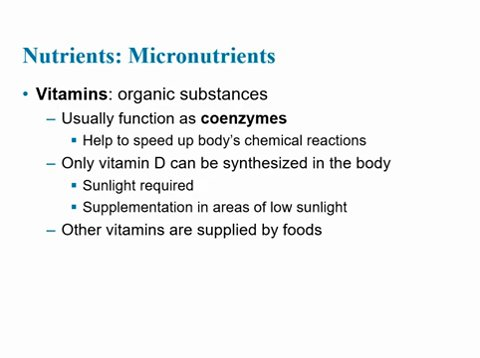
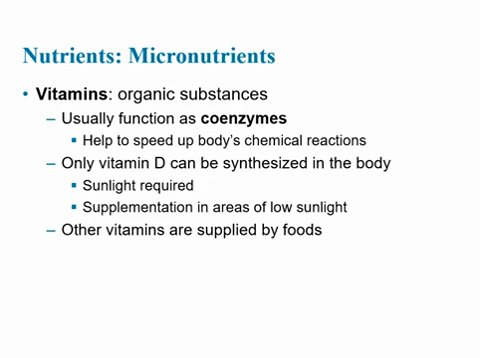
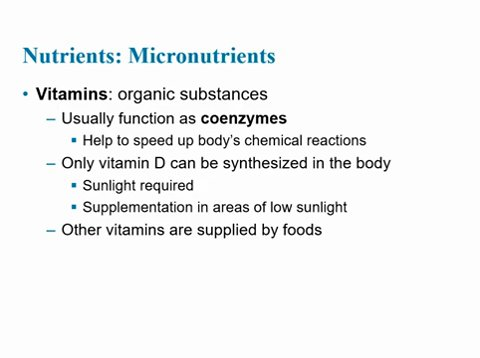
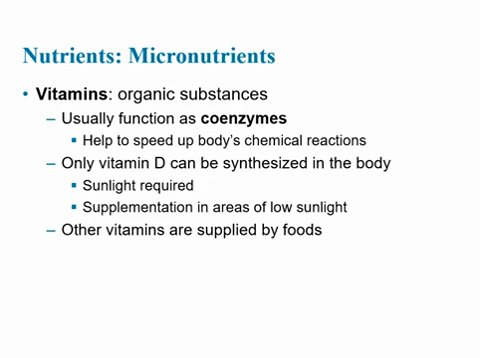
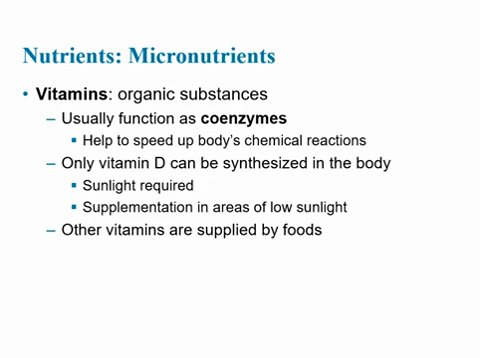
...
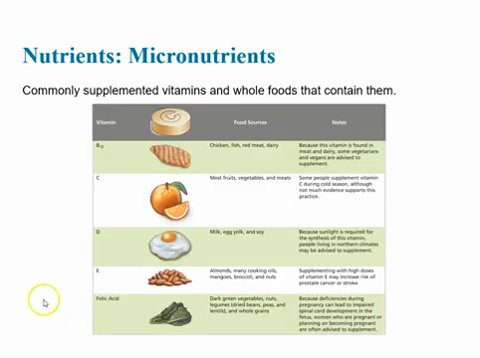
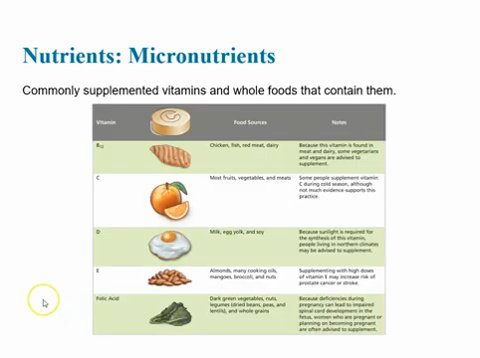
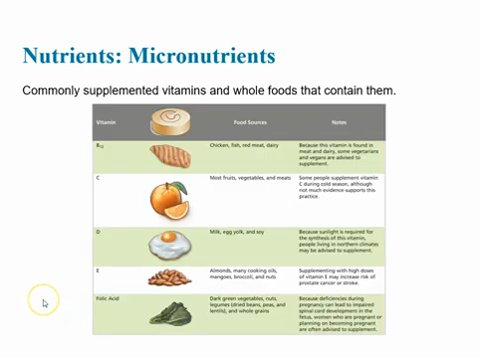
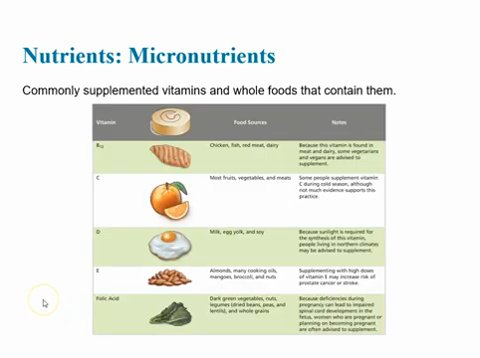
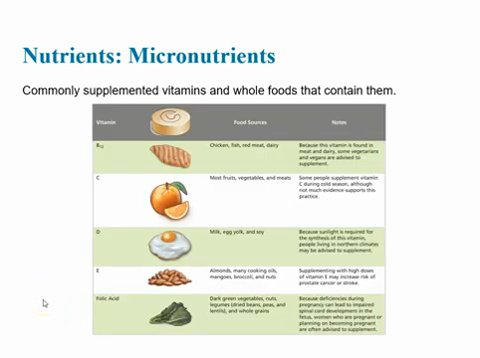

Gallery: 22 / 48 cases; 797 frames



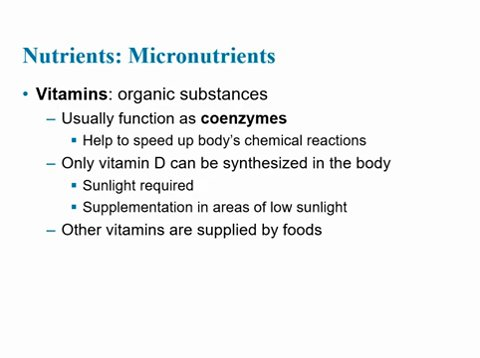
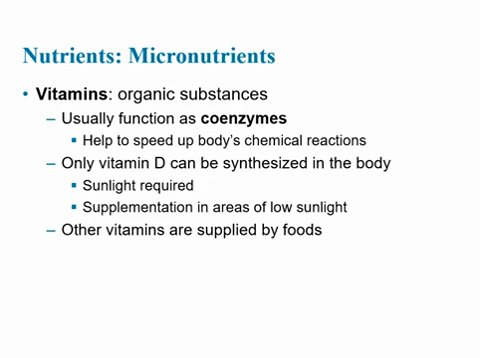
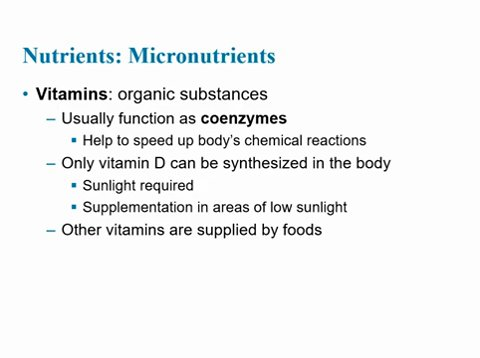
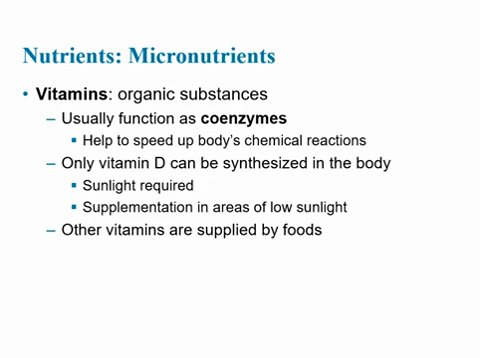
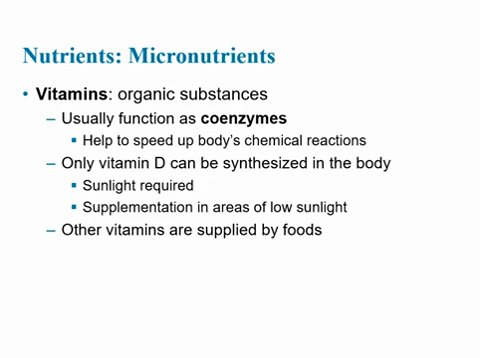
...
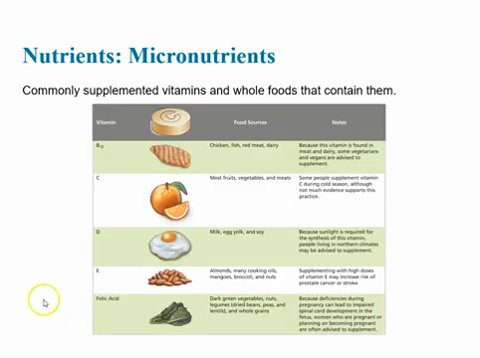
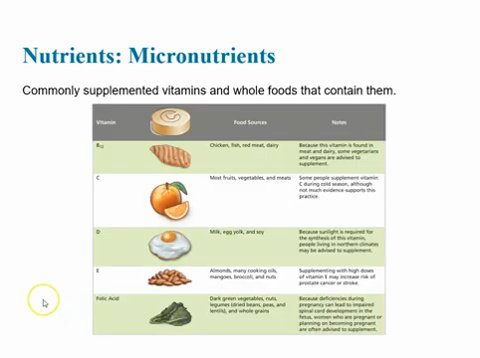
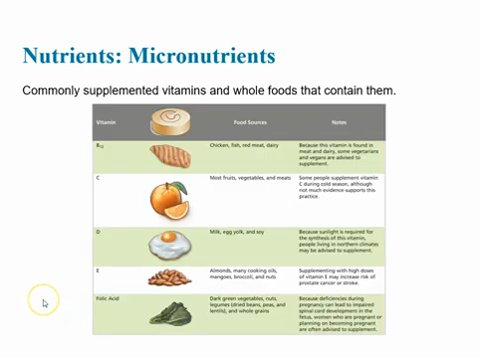
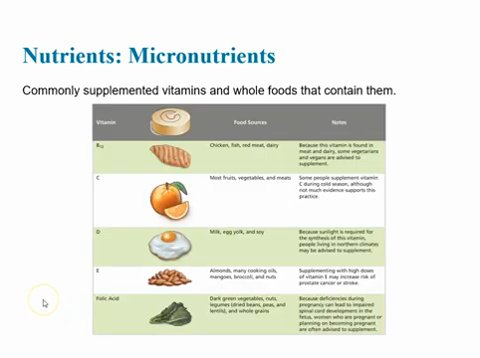
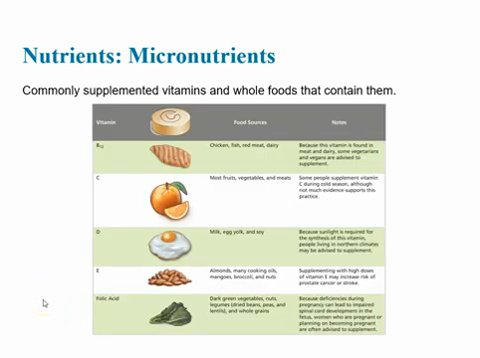

Gallery: 23 / 48 cases; 833 frames



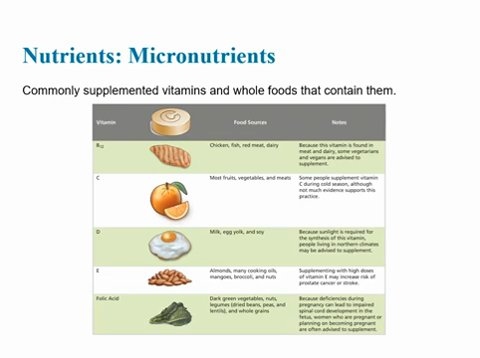
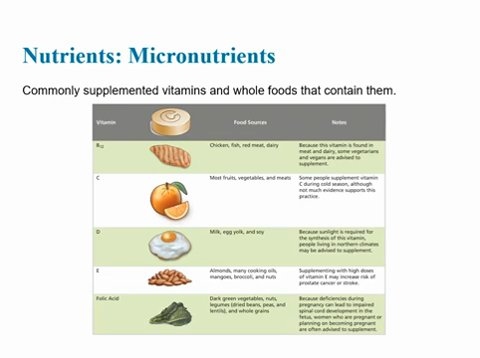
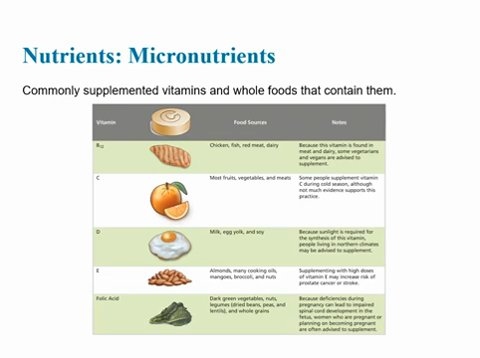
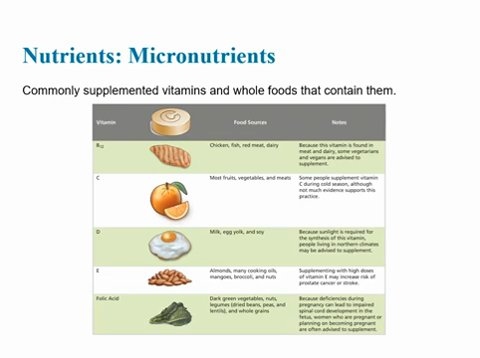
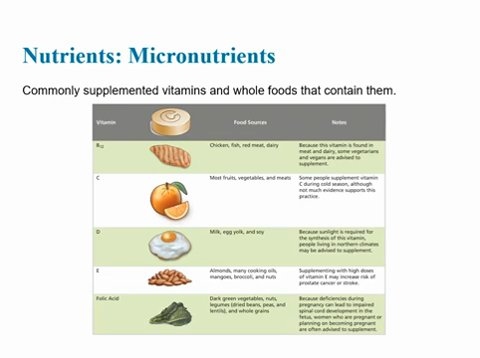
...
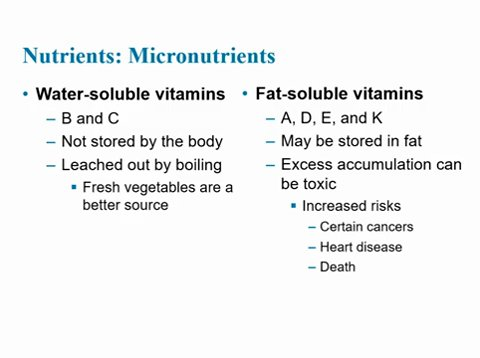
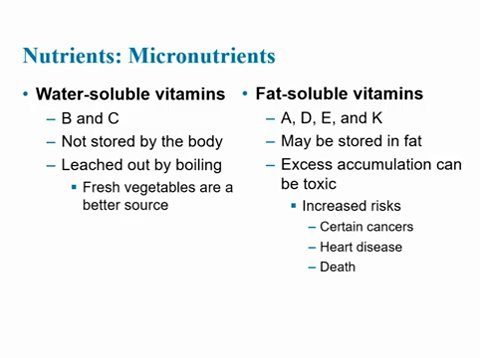
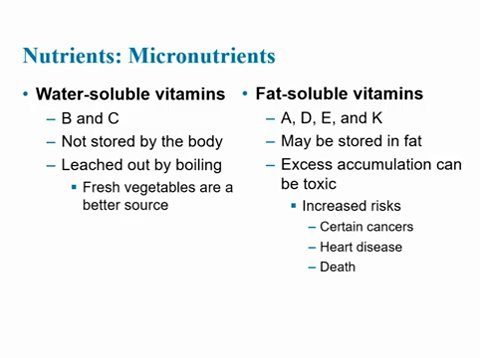
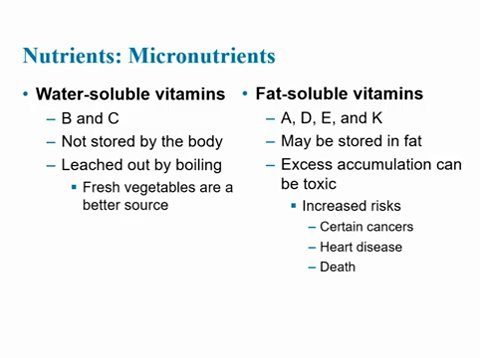
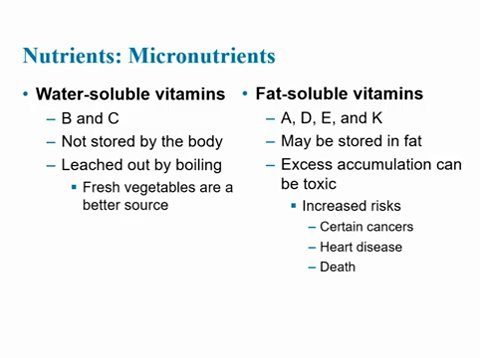

Gallery: 24 / 48 cases; 869 frames



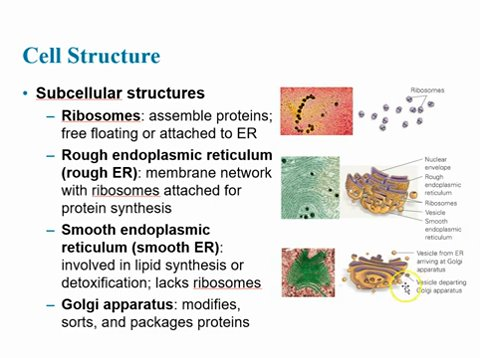
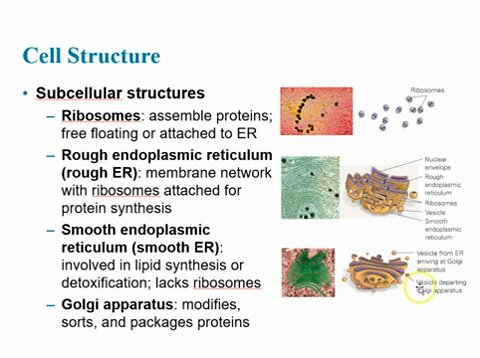
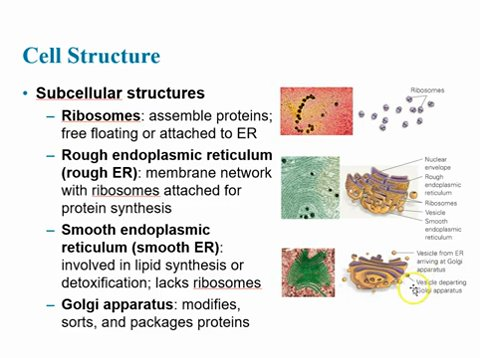
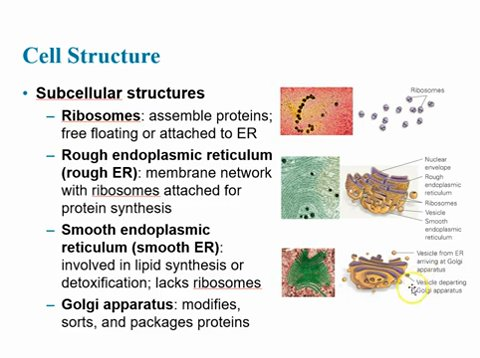
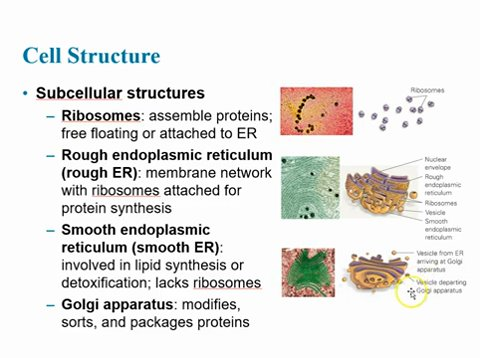
...
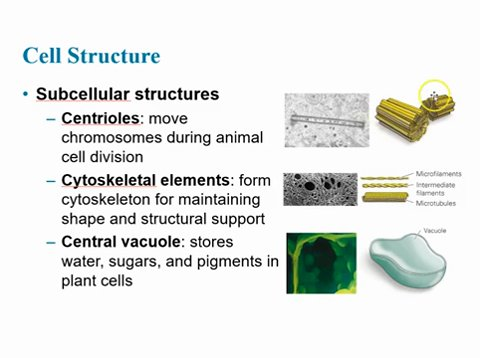
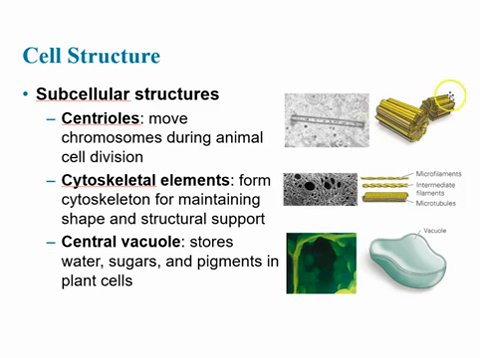
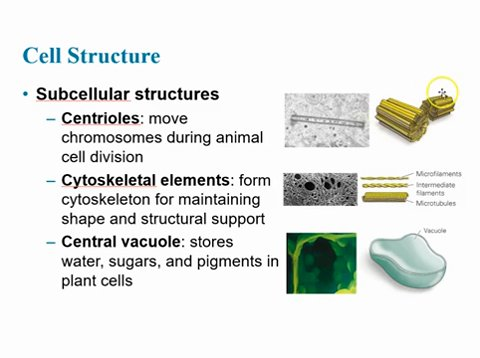
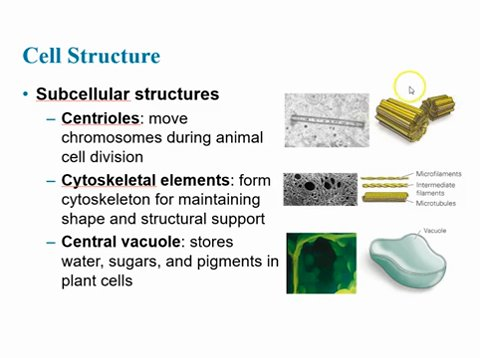
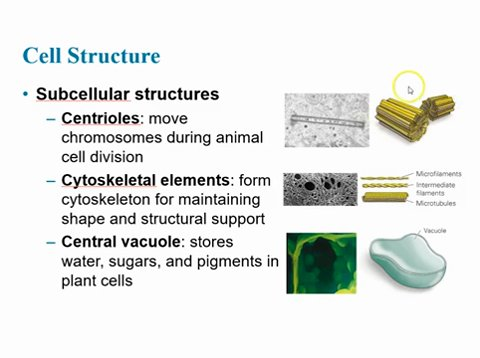

Gallery: 25 / 48 cases; 905 frames



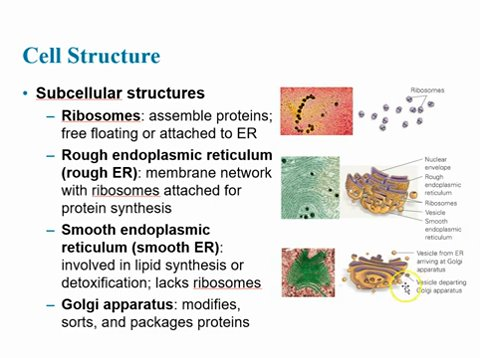
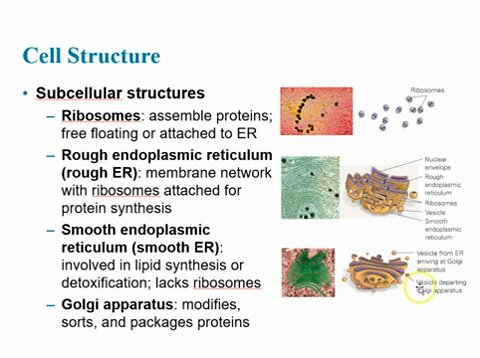
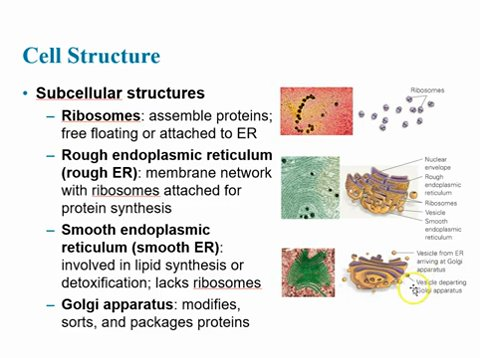
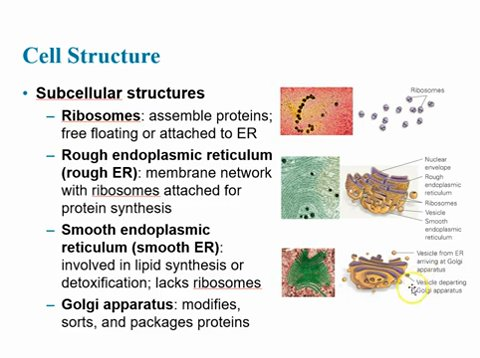
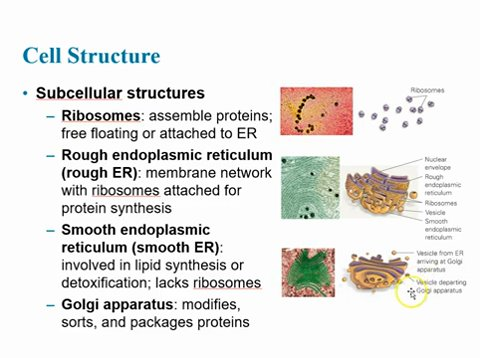
...
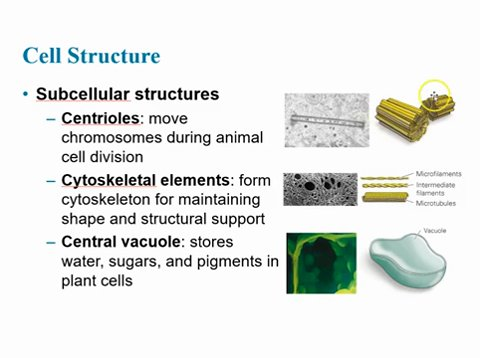
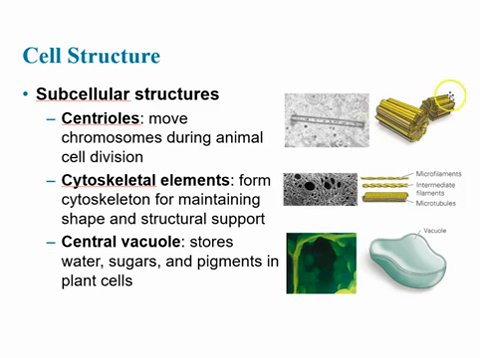
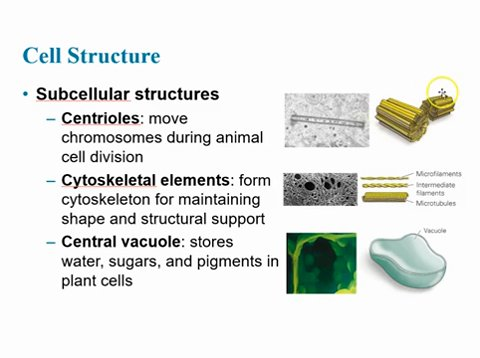
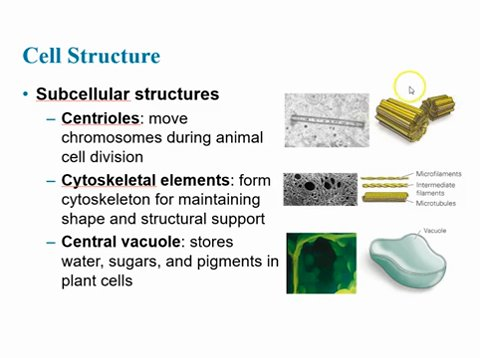
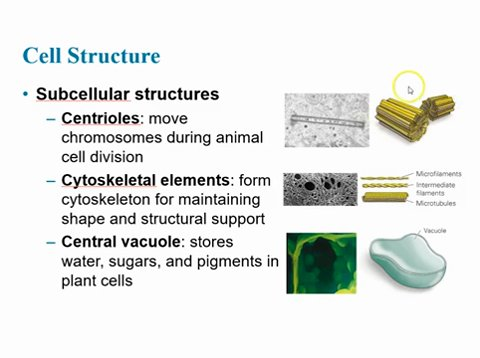

Gallery: 26 / 48 cases; 941 frames



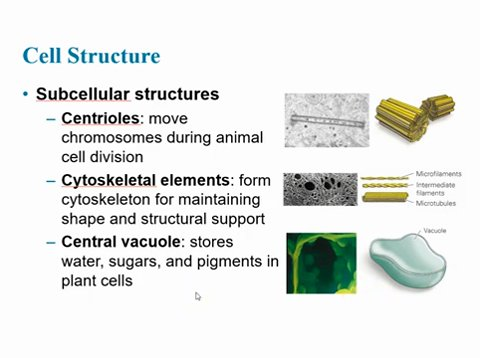
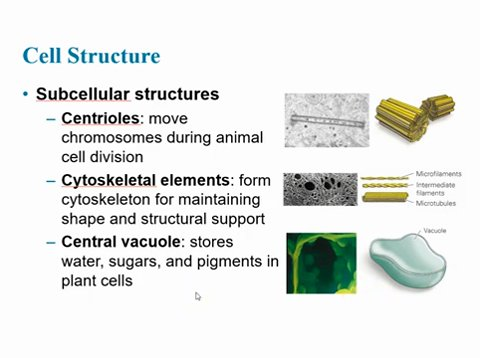
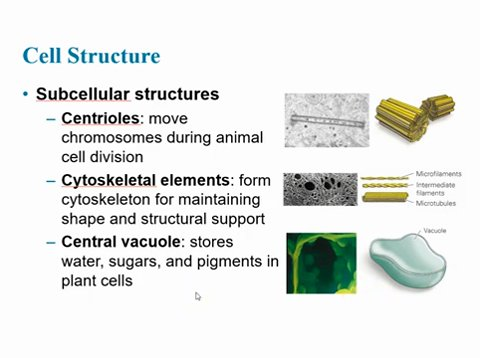
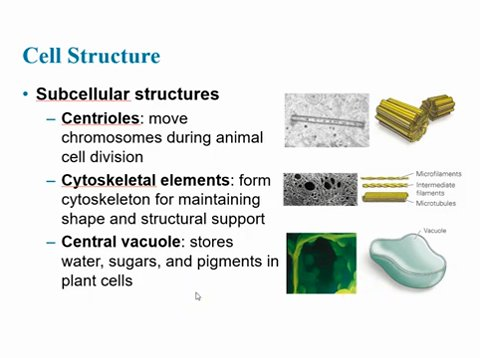
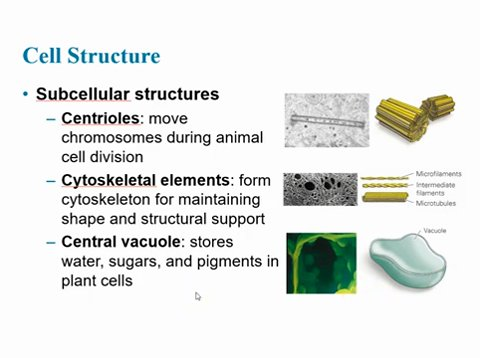
...
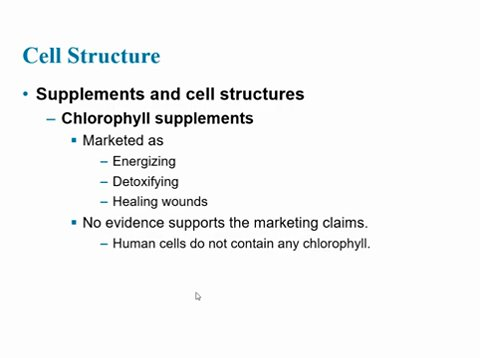
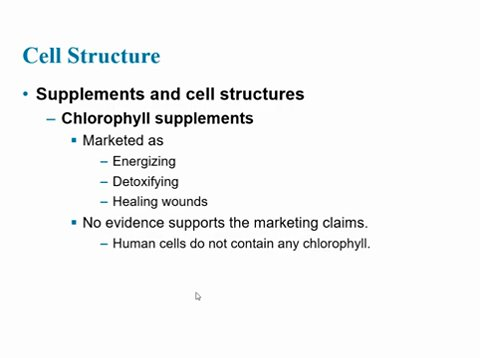
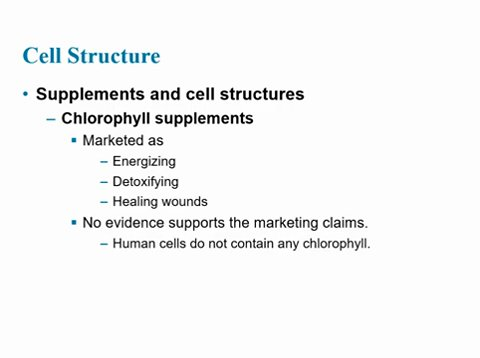
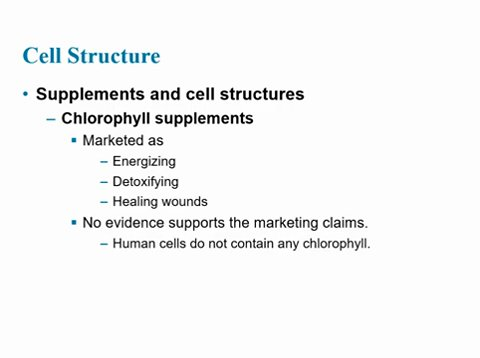
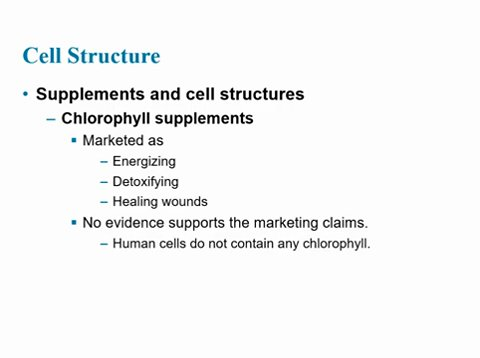

Gallery: 27 / 48 cases; 977 frames



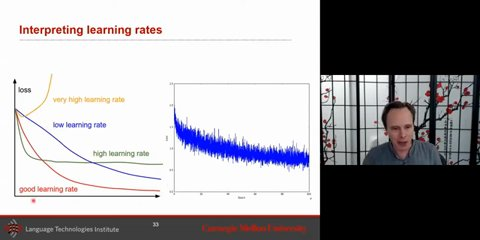
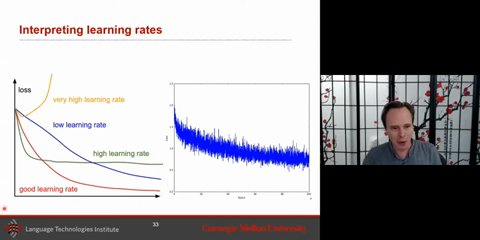
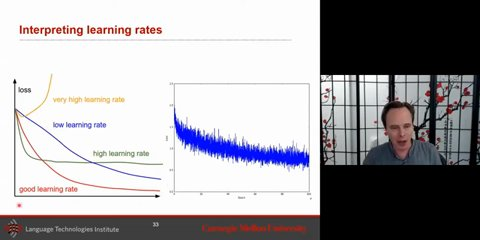
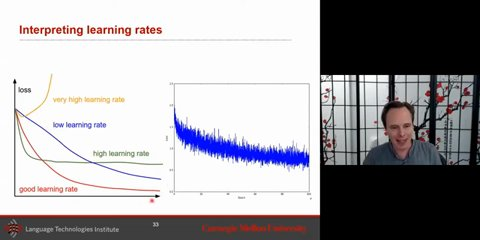
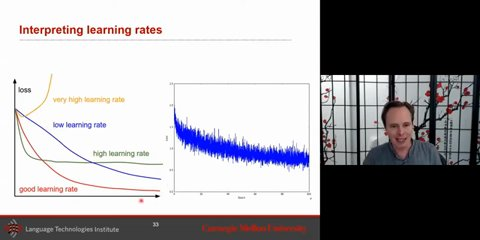
...
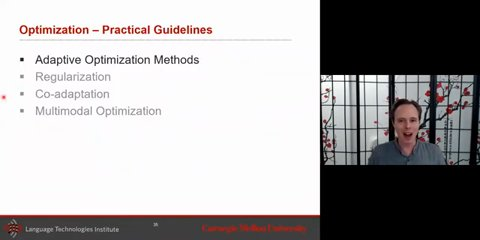
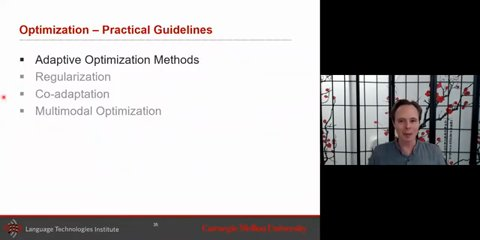
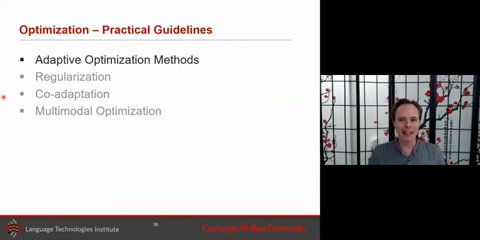
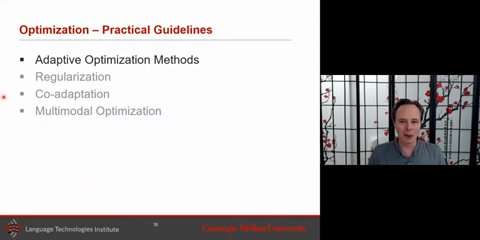
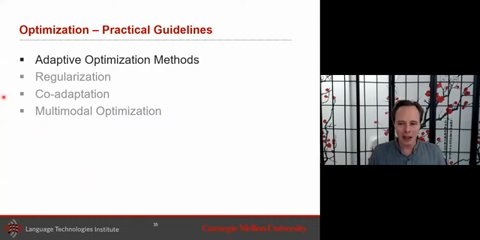

Gallery: 28 / 48 cases; 1015 frames



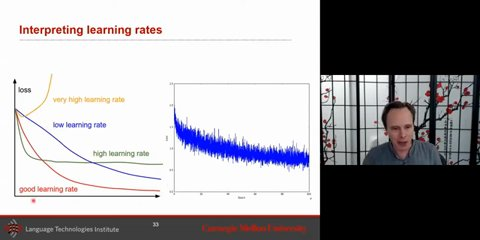
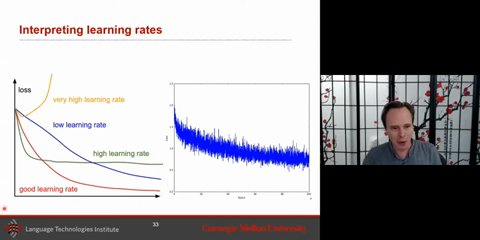
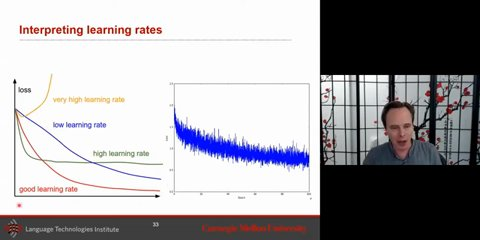
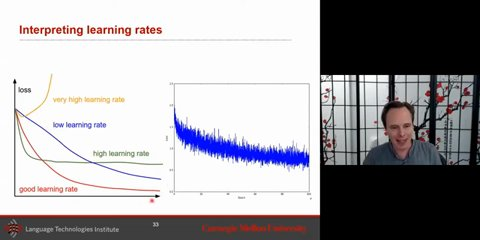
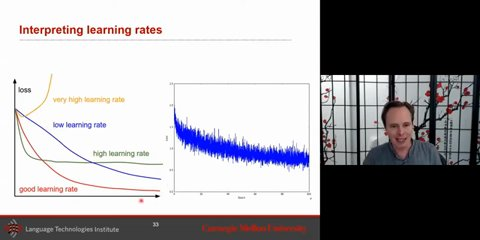
...
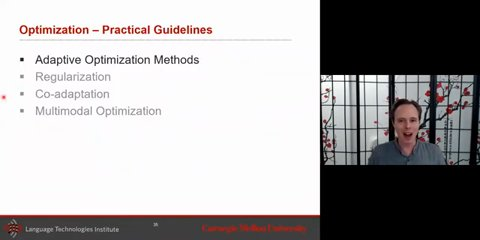
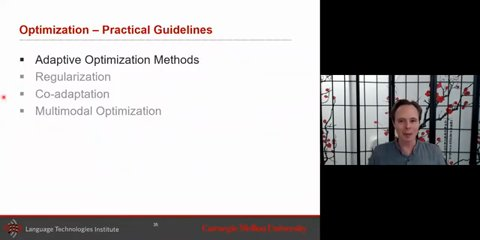
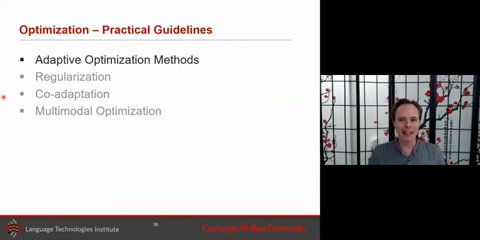
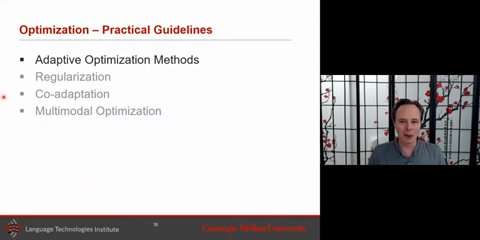
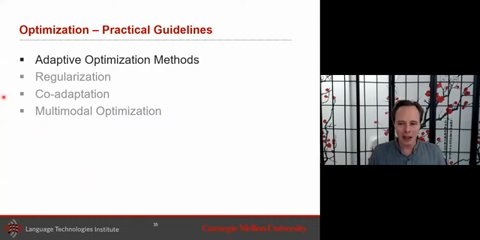

Gallery: 29 / 48 cases; 1053 frames



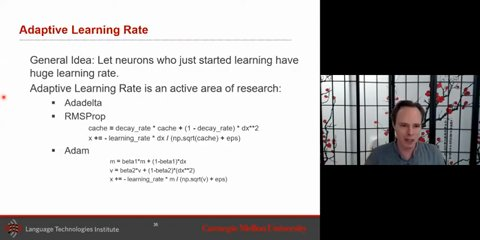
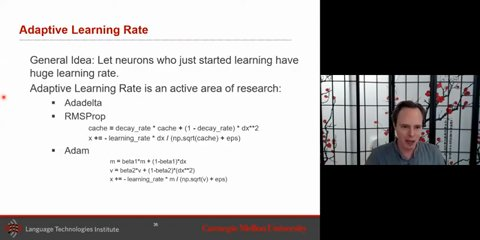
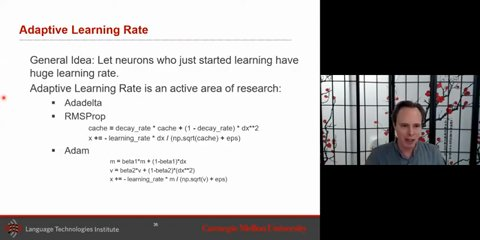
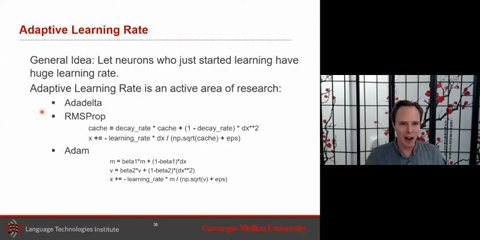
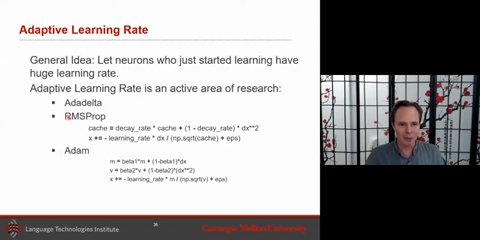
...
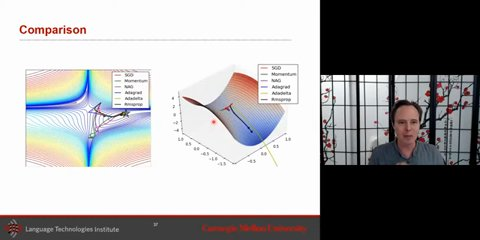
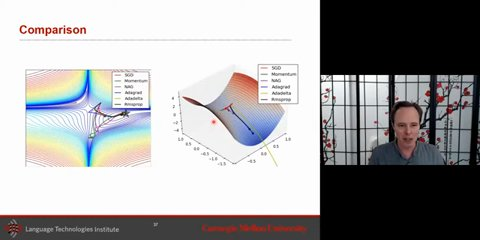
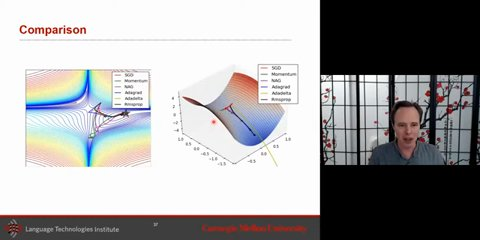
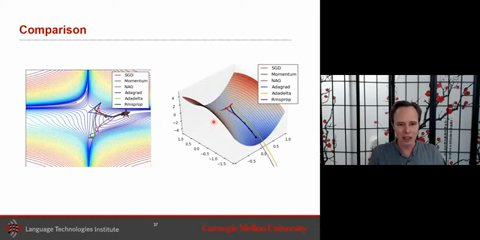
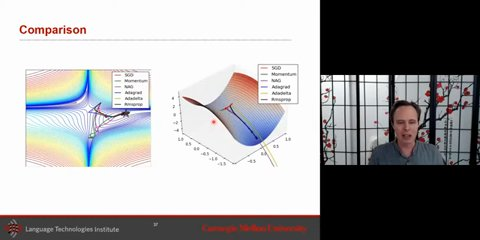

Gallery: 30 / 48 cases; 1091 frames



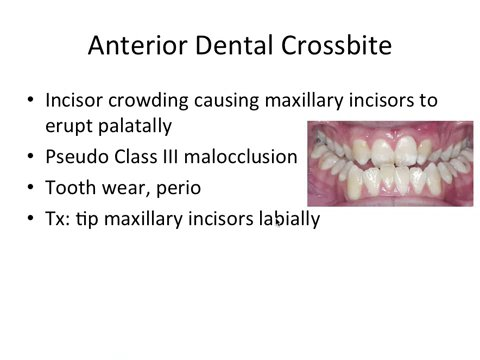
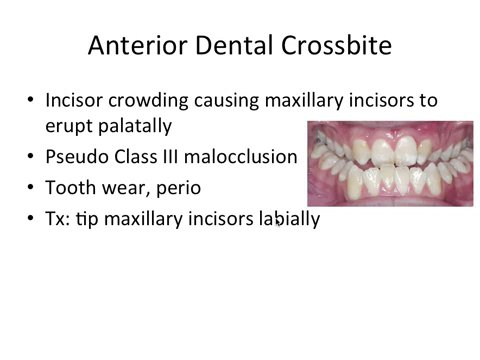
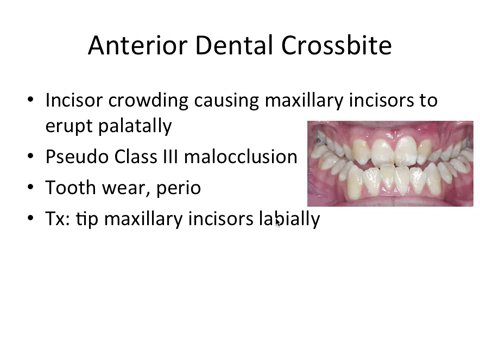
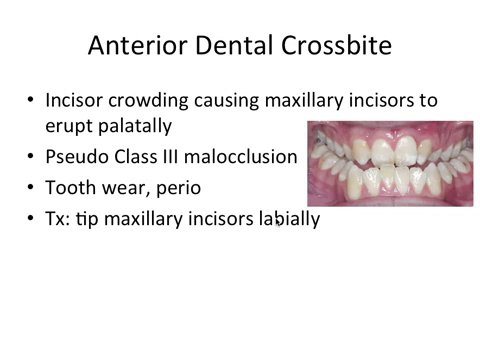
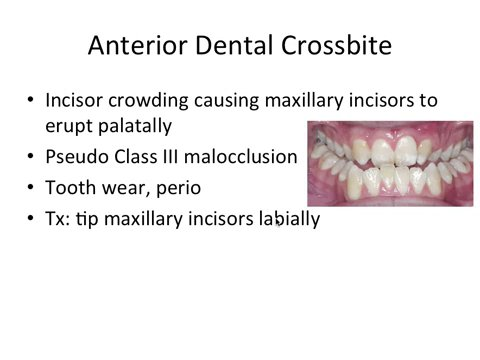
...
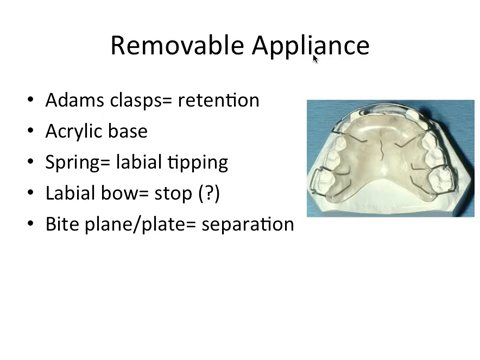
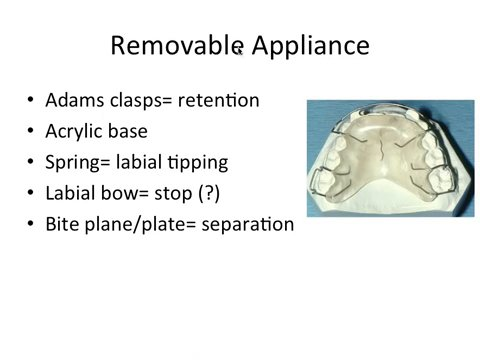
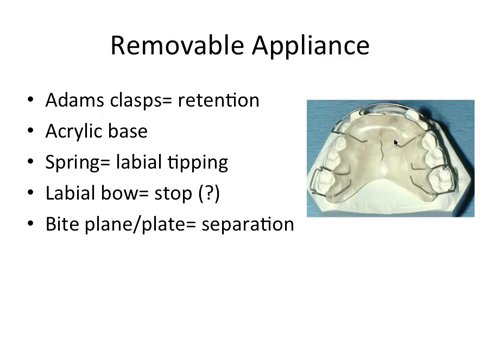
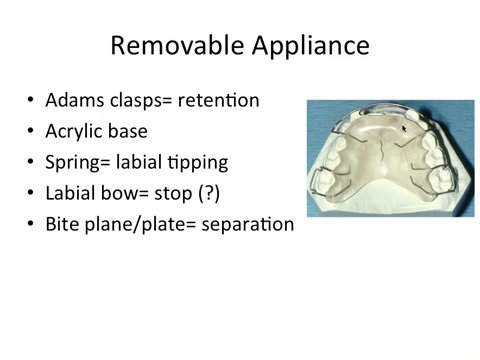
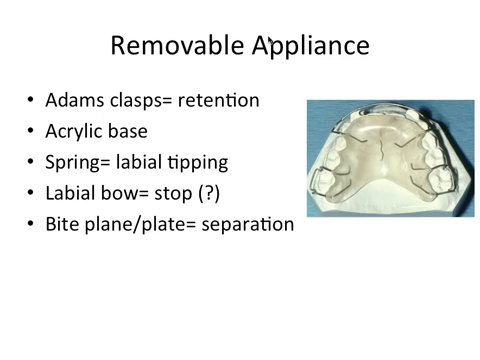

Gallery: 31 / 48 cases; 1129 frames



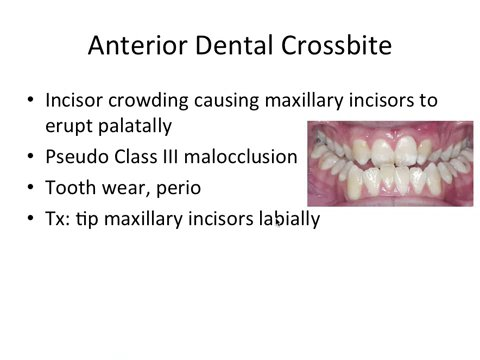
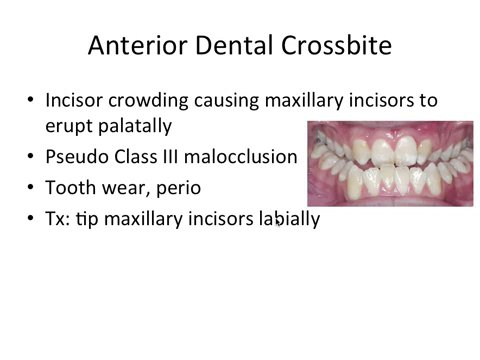
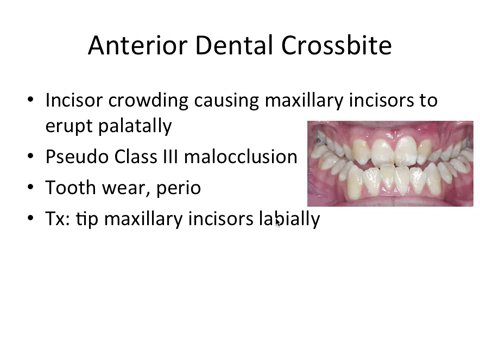
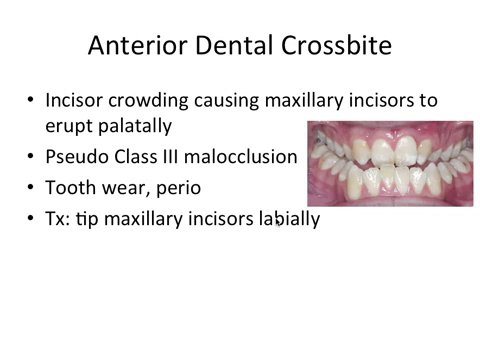
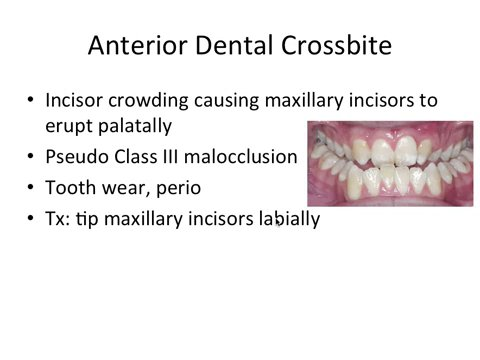
...
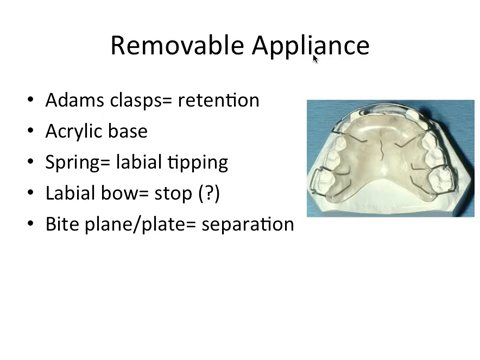
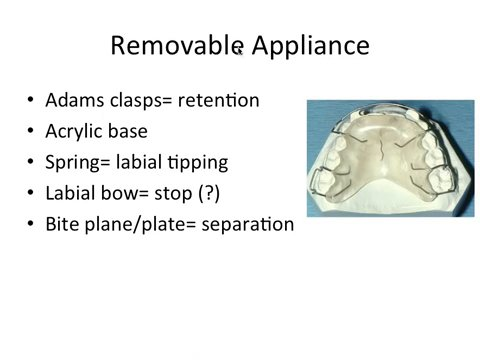
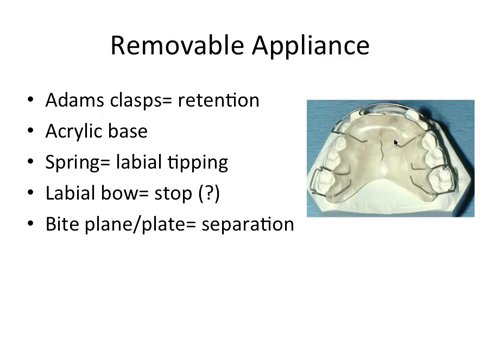
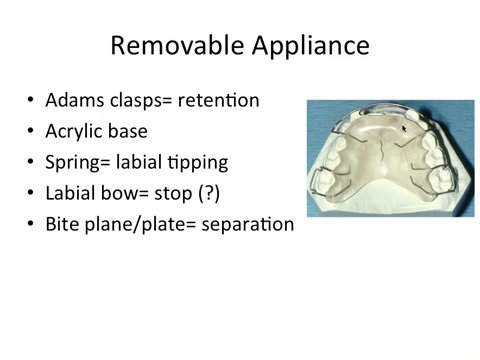
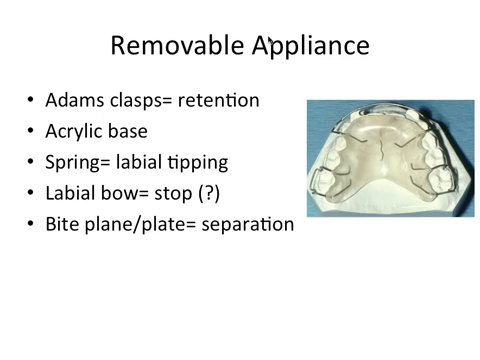

Gallery: 32 / 48 cases; 1167 frames



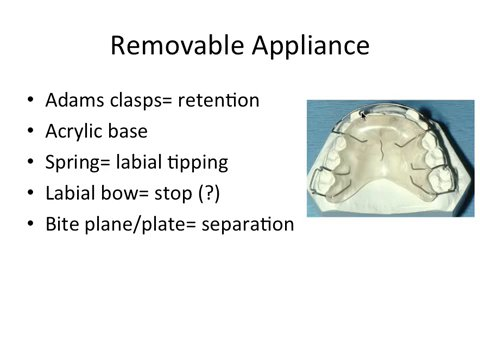
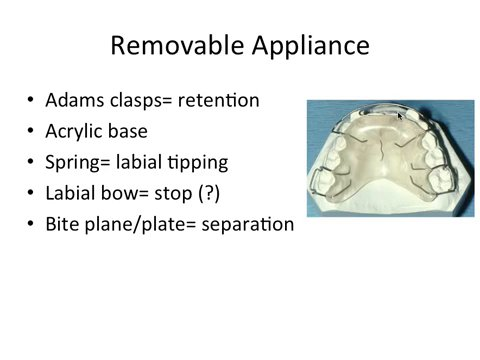
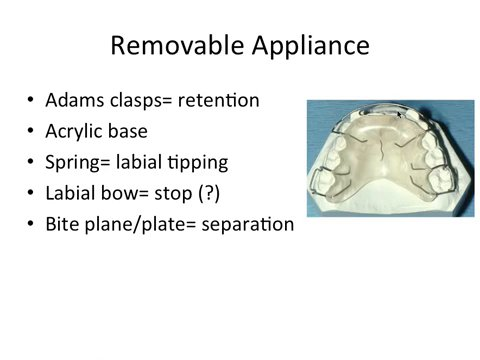
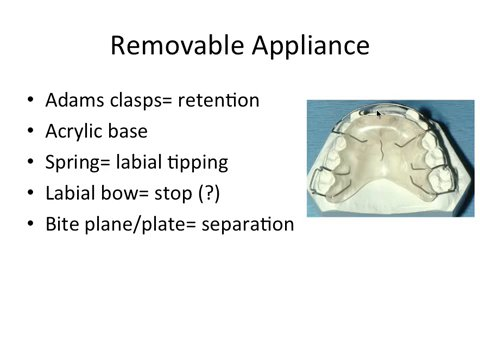
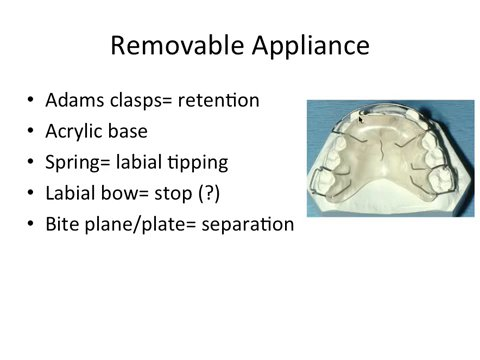
...
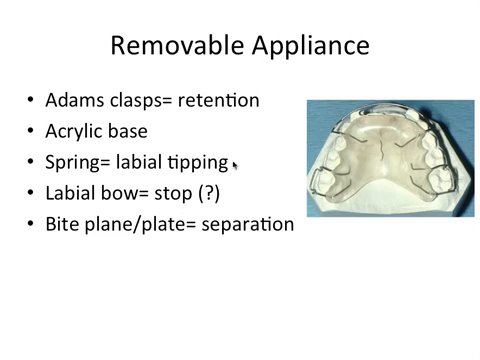
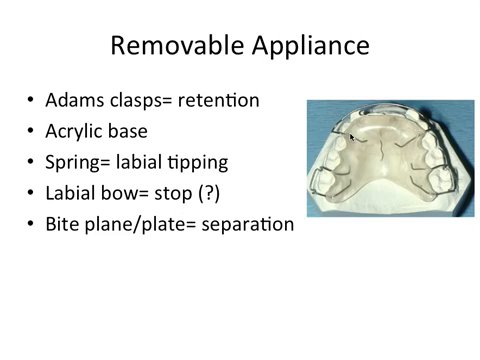
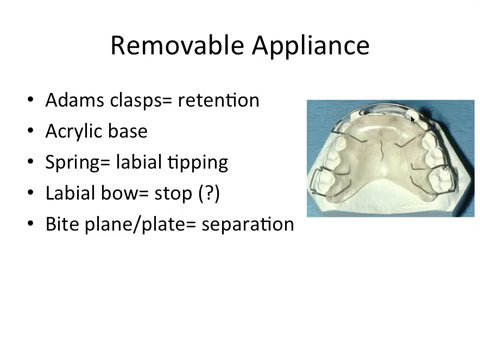
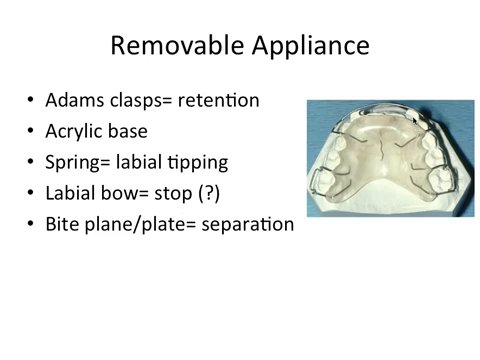
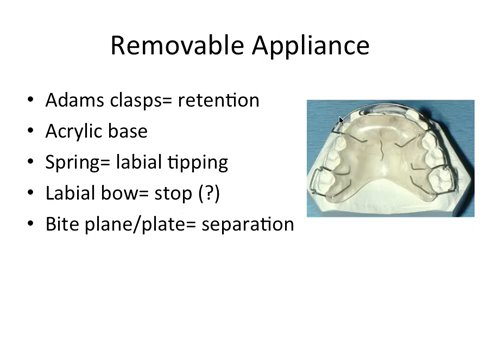

Gallery: 33 / 48 cases; 1205 frames



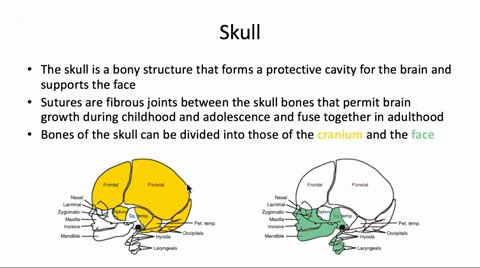
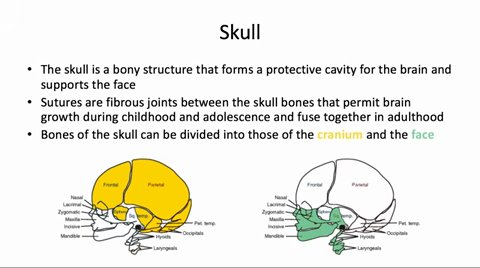
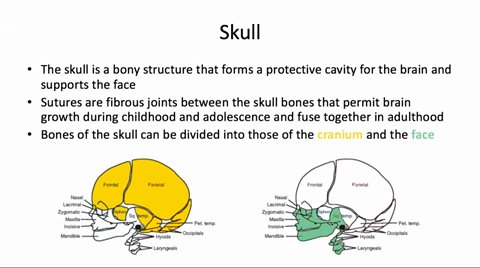
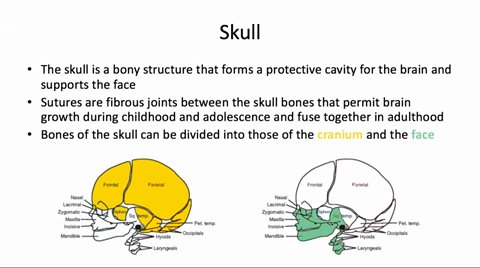
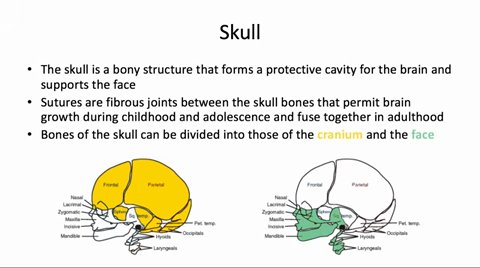
...
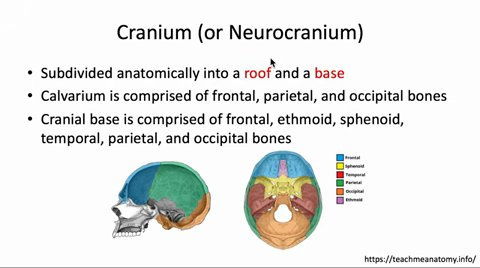
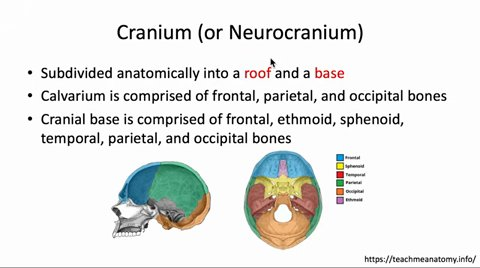
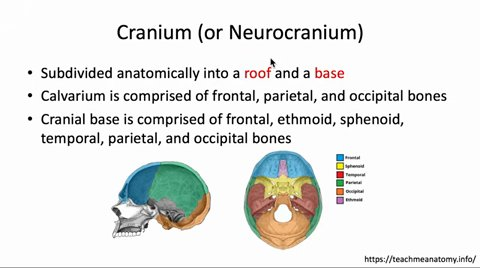
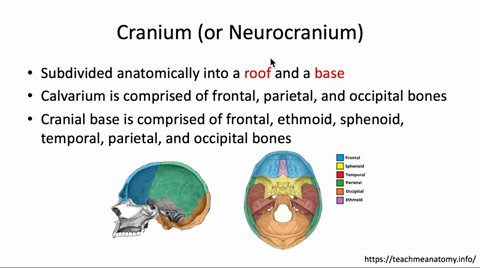
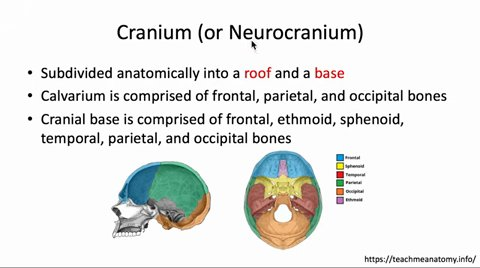

Gallery: 34 / 48 cases; 1243 frames



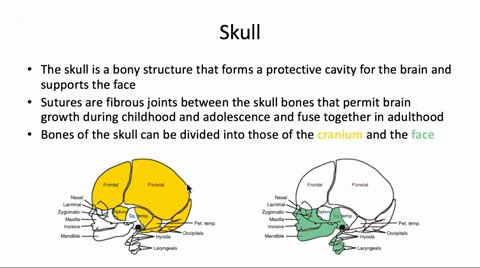
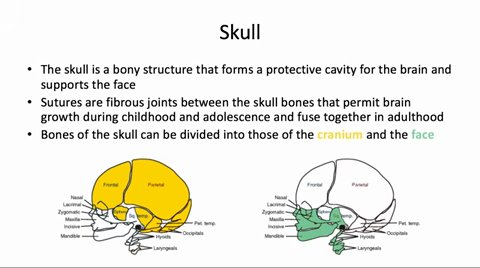
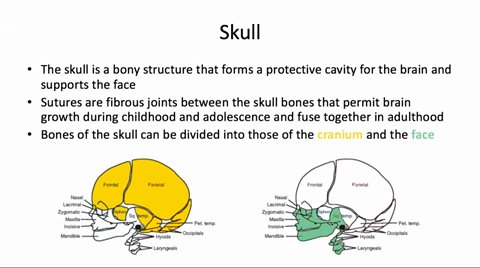
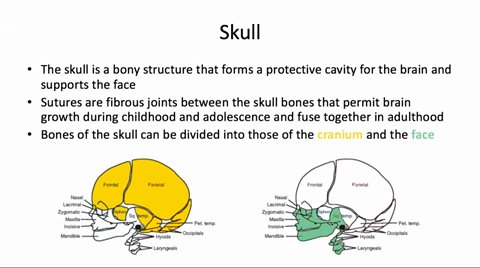
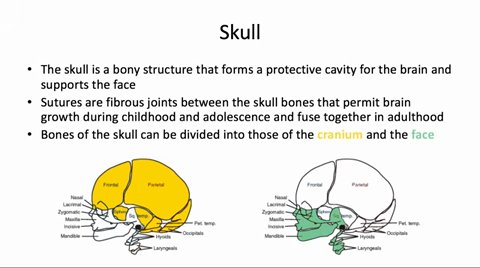
...
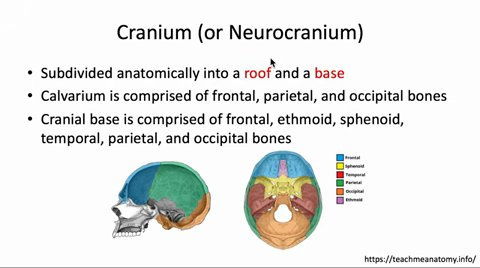
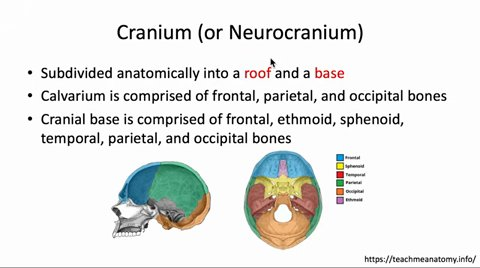
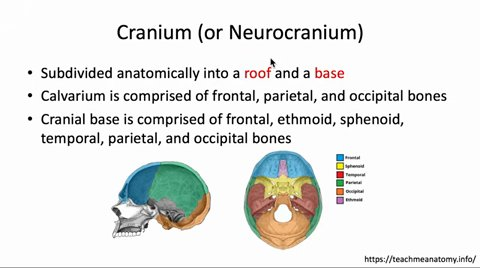
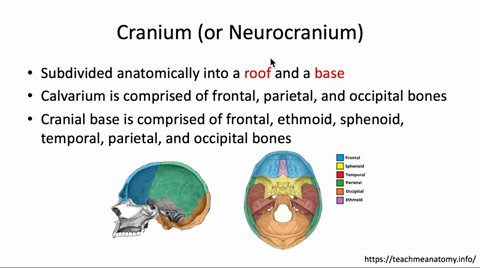
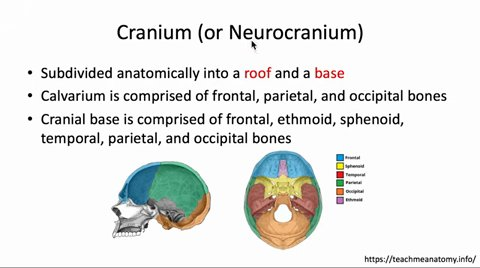

Gallery: 35 / 48 cases; 1281 frames



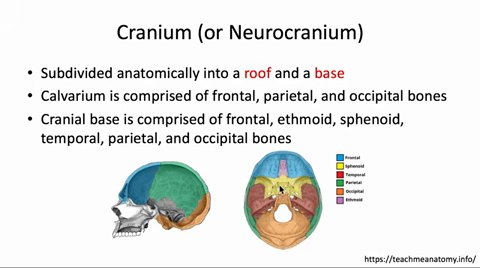
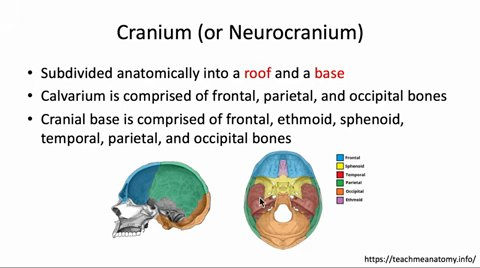
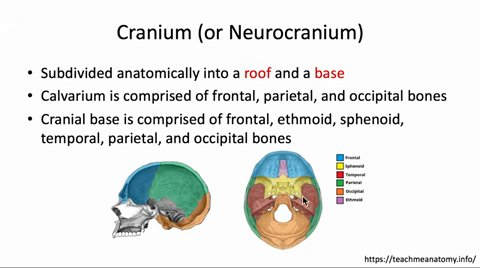
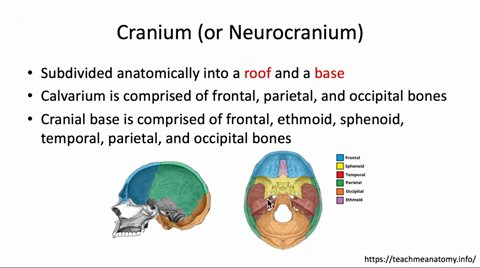
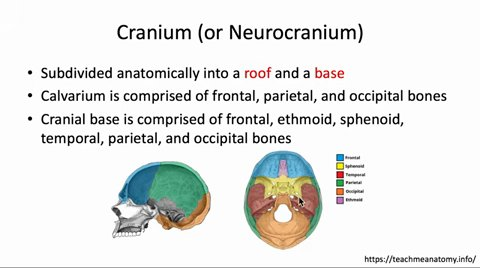
...
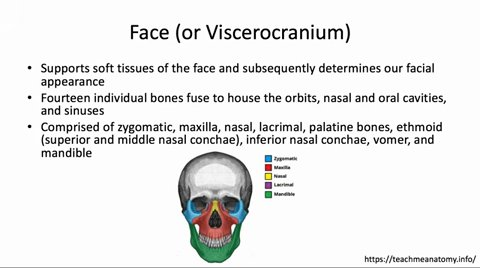
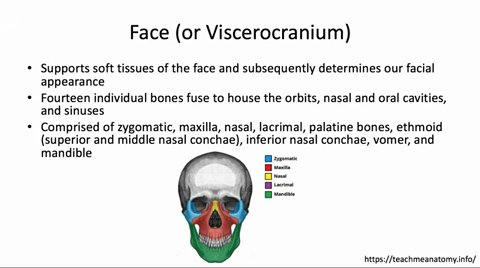
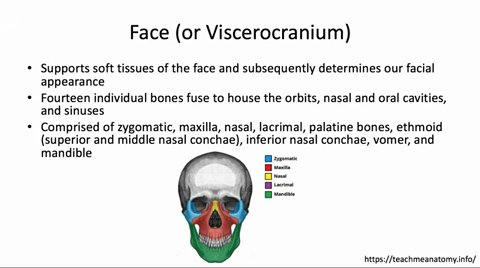
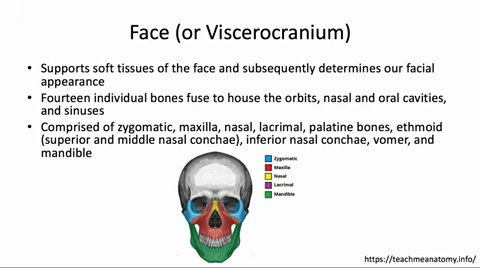
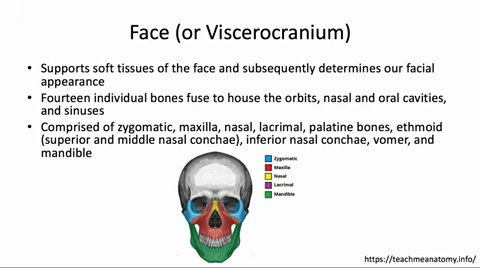

Gallery: 36 / 48 cases; 1319 frames



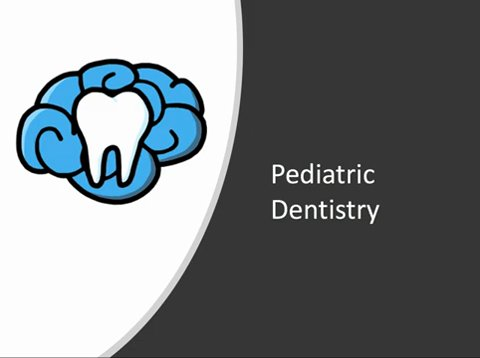
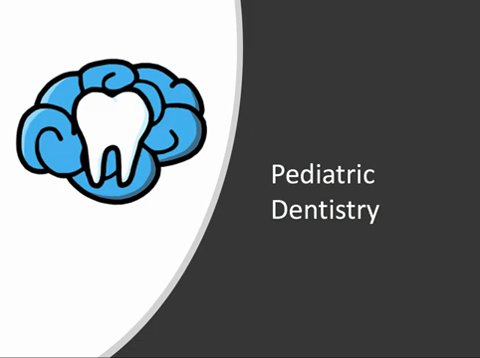
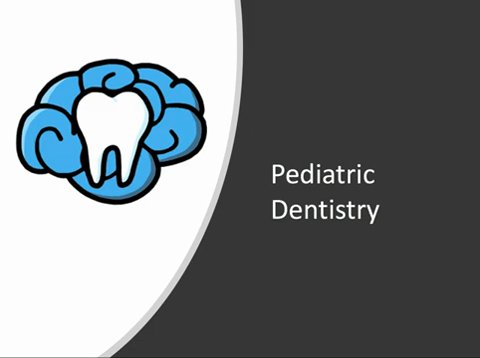
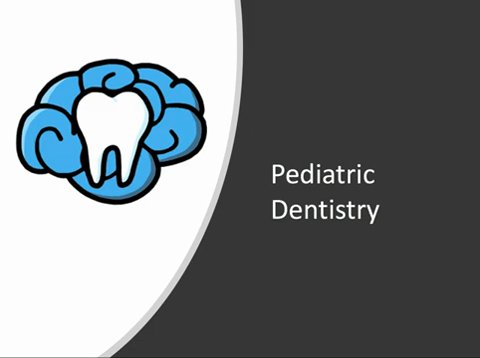
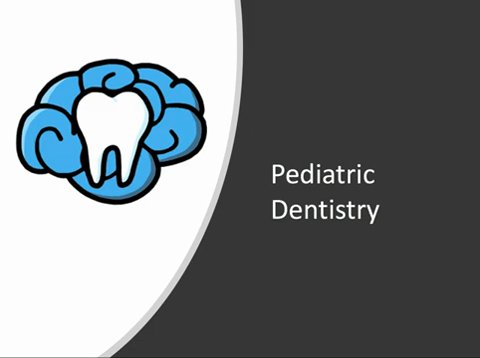
...
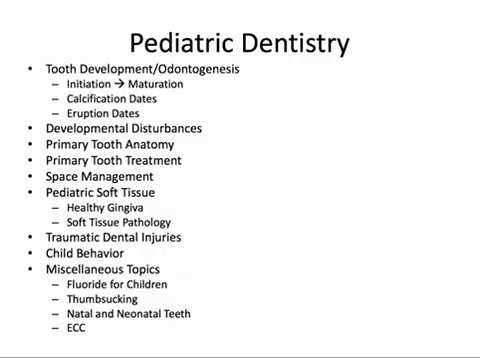
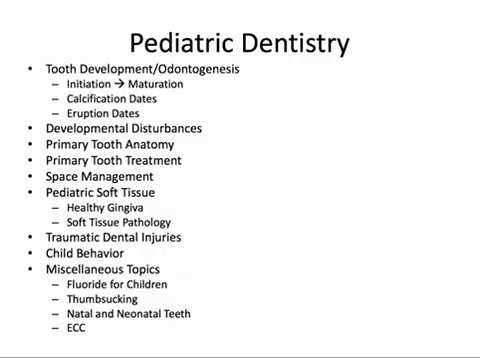
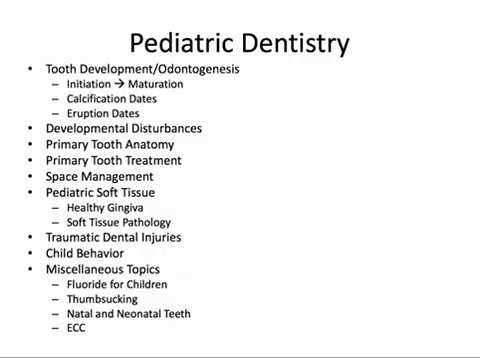
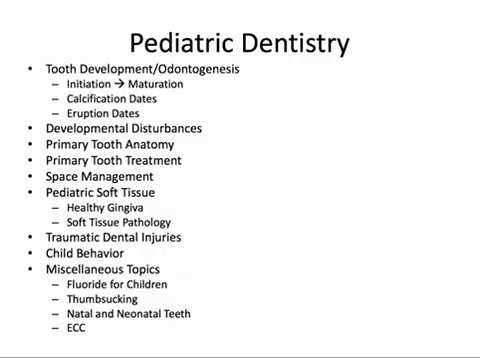
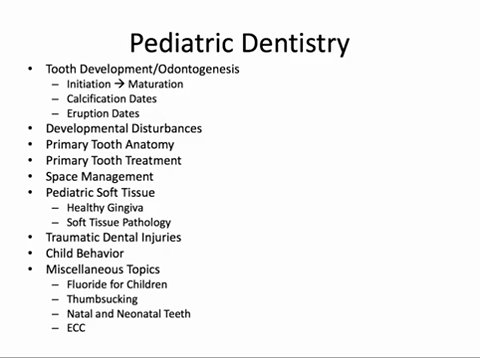

Gallery: 37 / 48 cases; 1357 frames



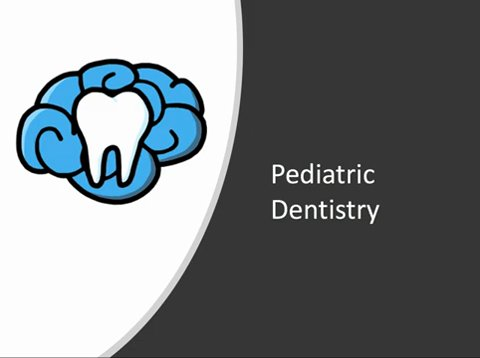
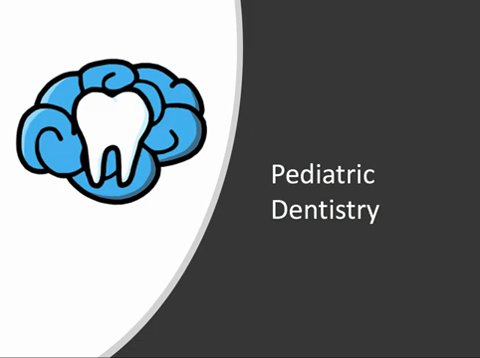
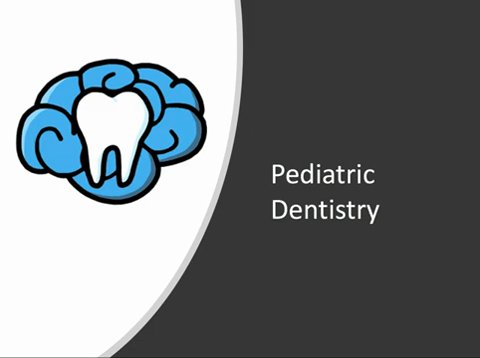
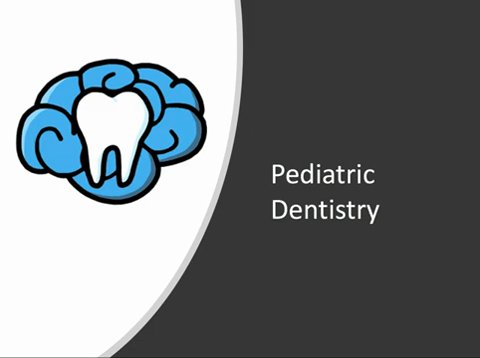
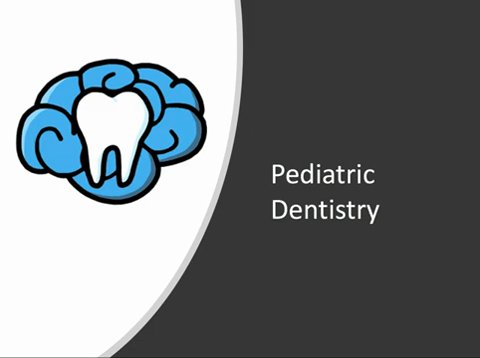
...
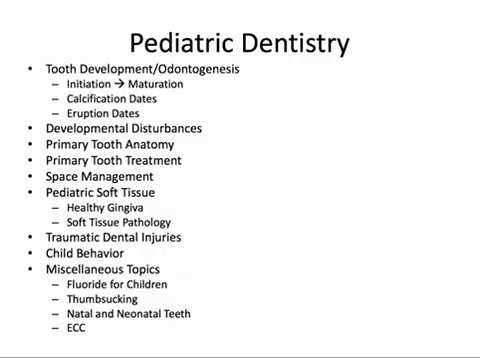
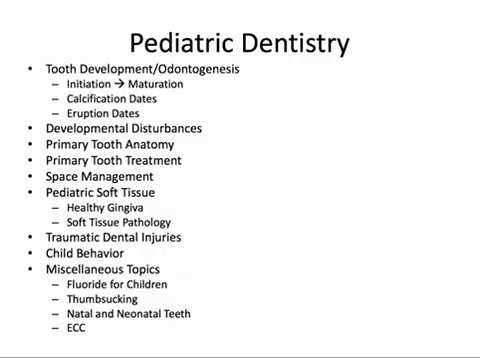
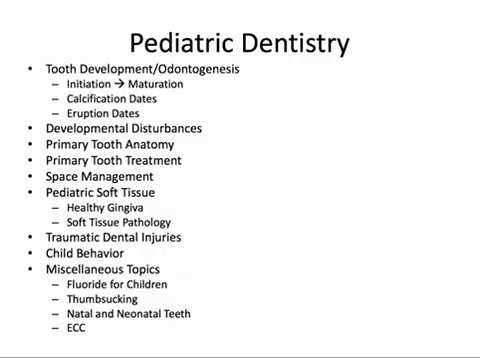
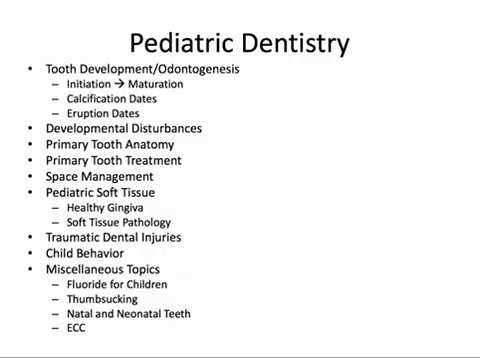
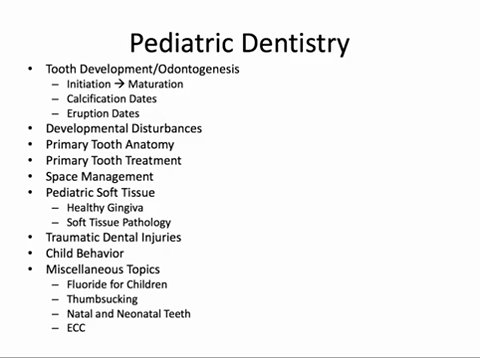

Gallery: 38 / 48 cases; 1395 frames



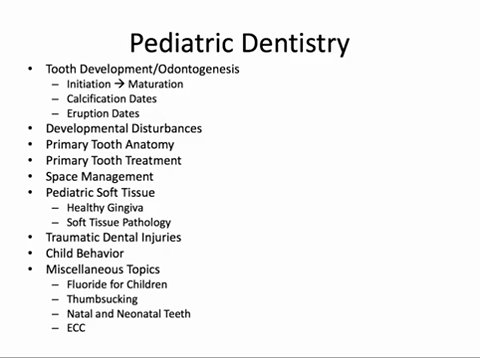
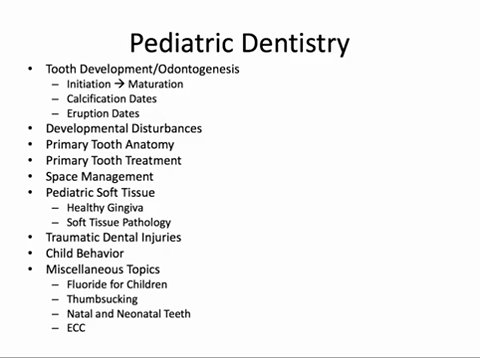
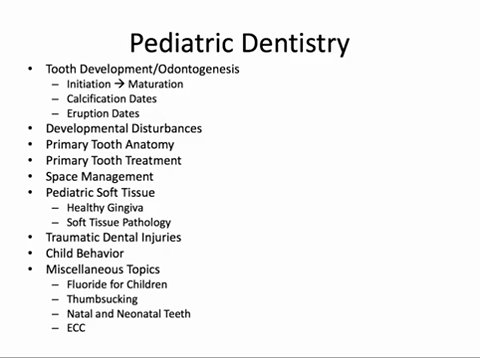
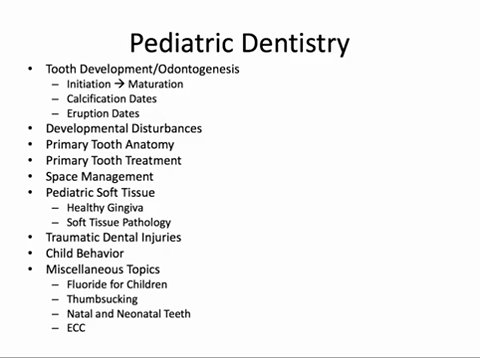
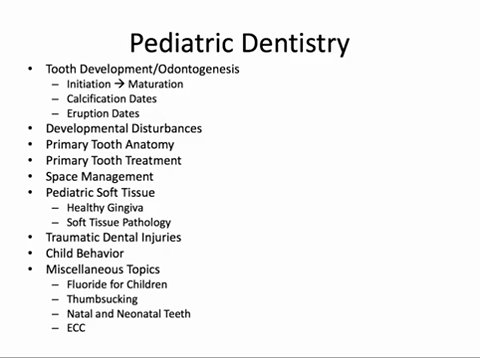
...
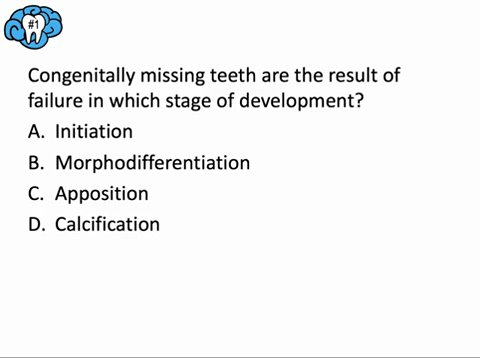
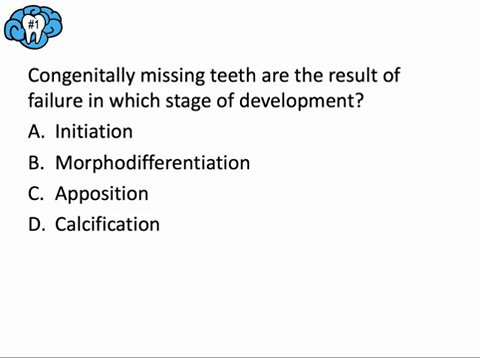
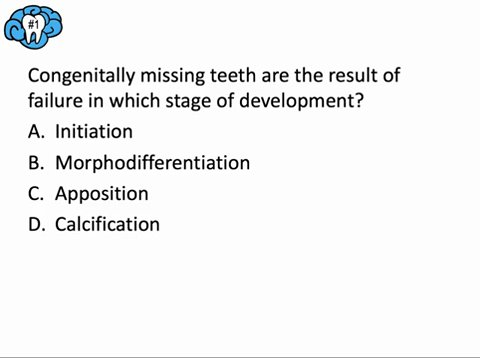
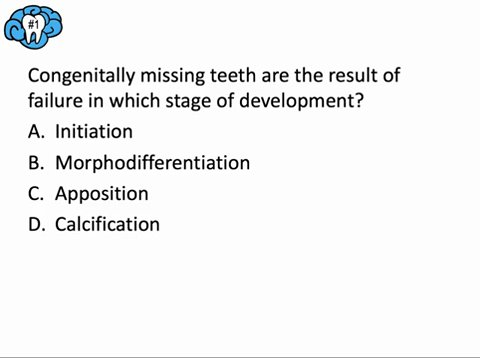
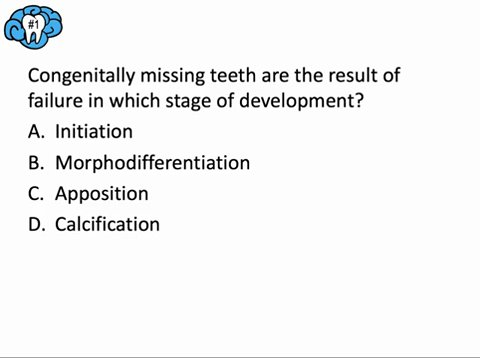

Gallery: 39 / 48 cases; 1433 frames



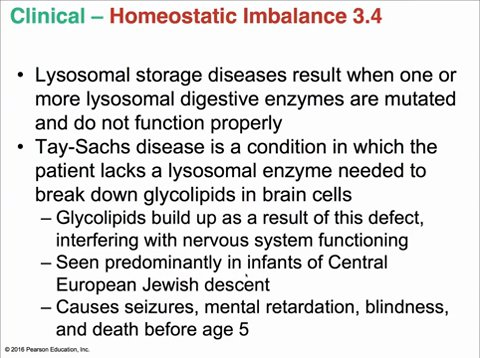
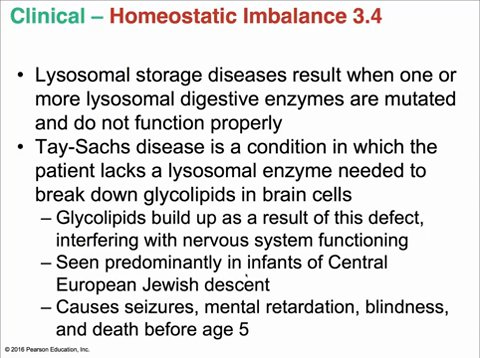
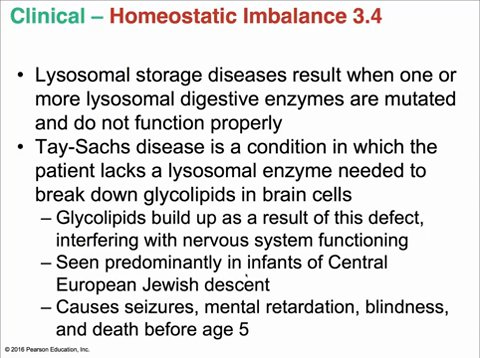
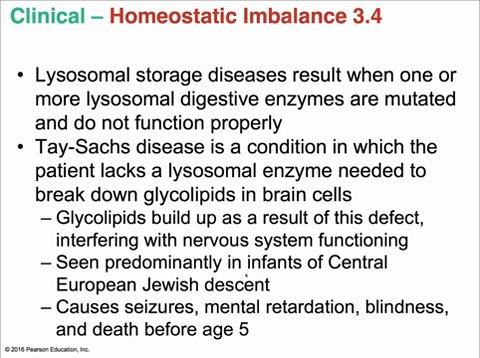
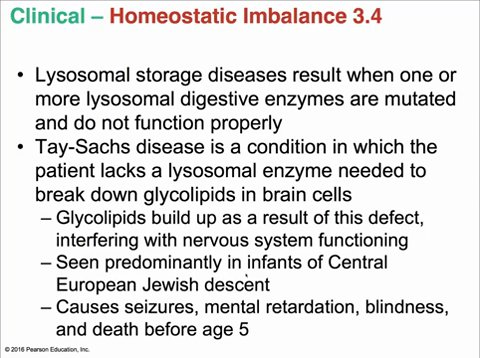
...
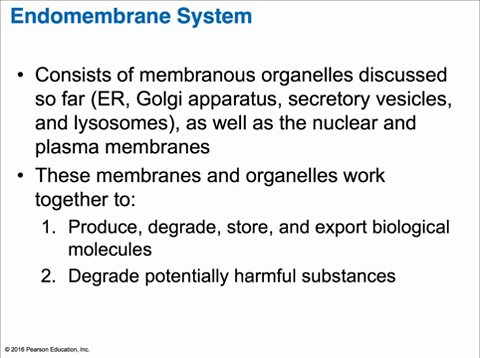
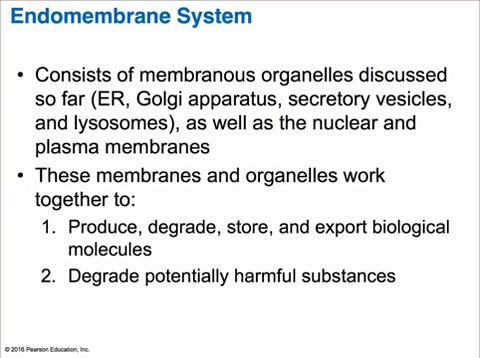
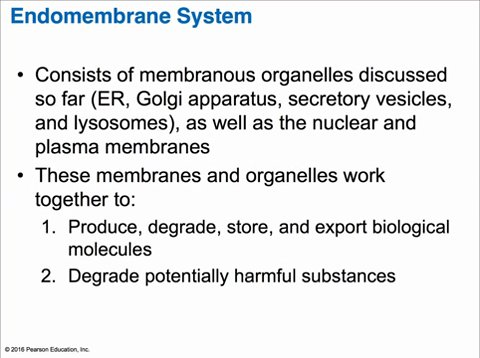
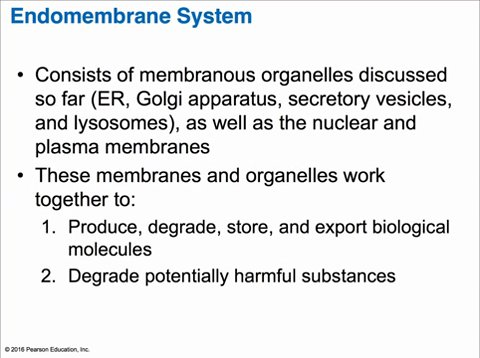
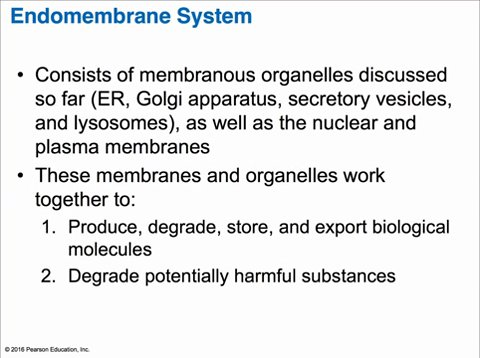

Gallery: 40 / 48 cases; 1471 frames



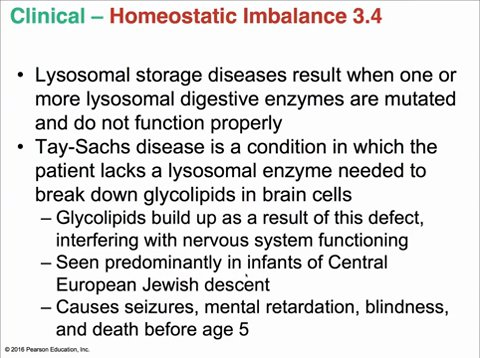
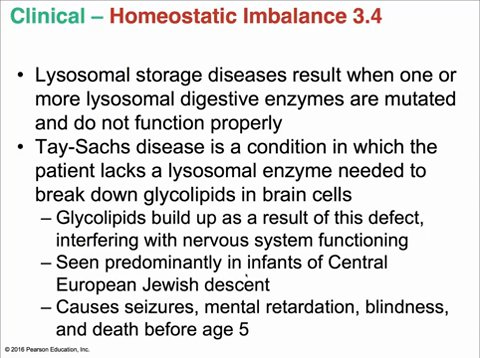
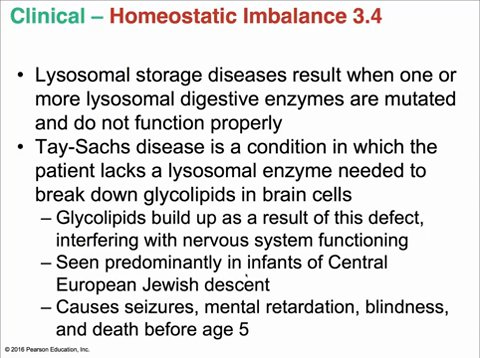
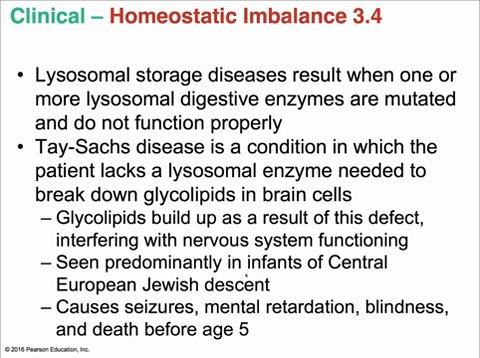
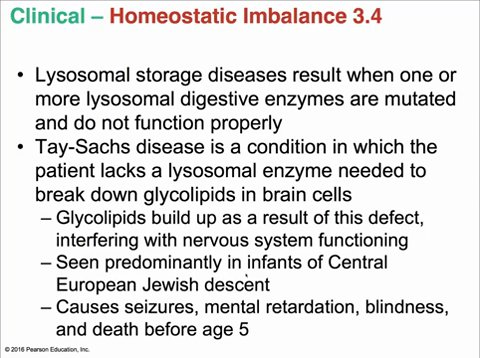
...
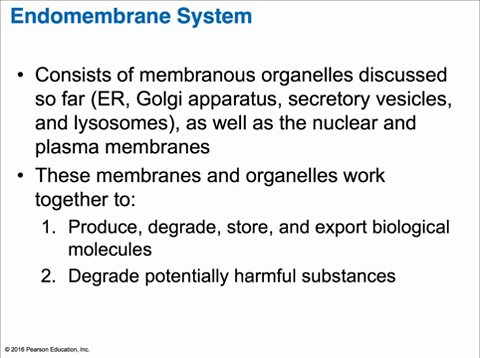
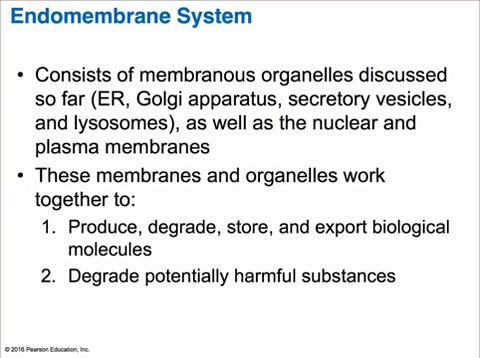
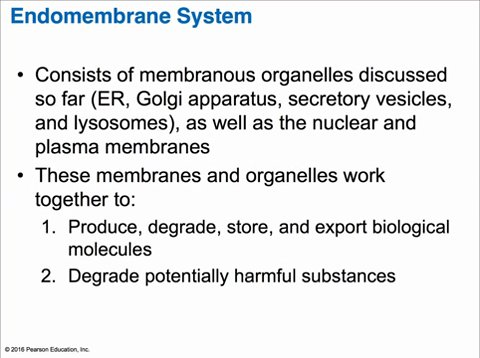
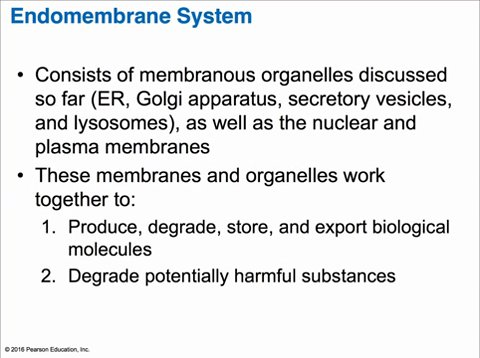
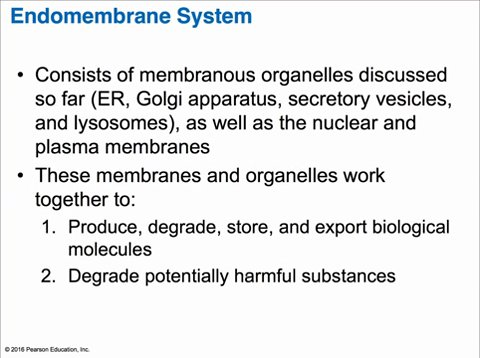

Gallery: 41 / 48 cases; 1509 frames



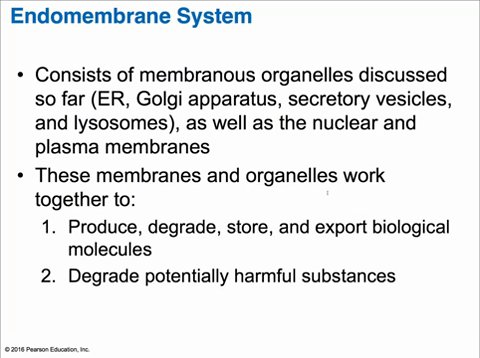
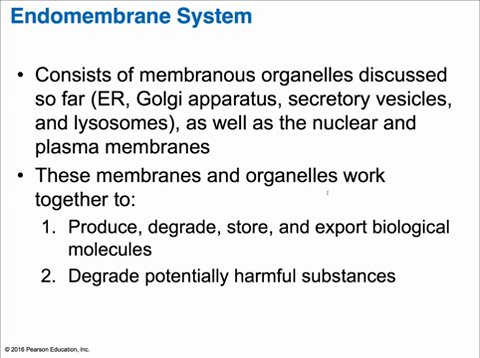
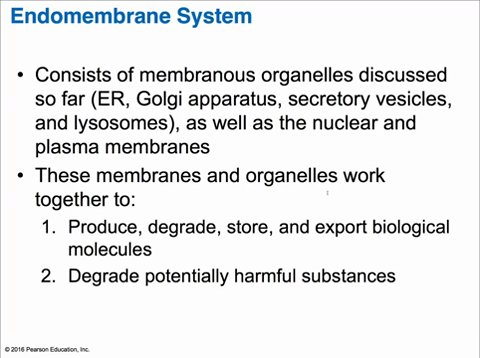
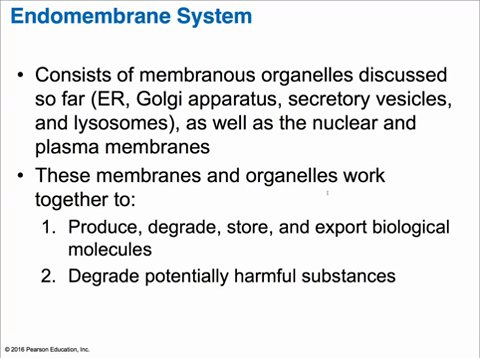
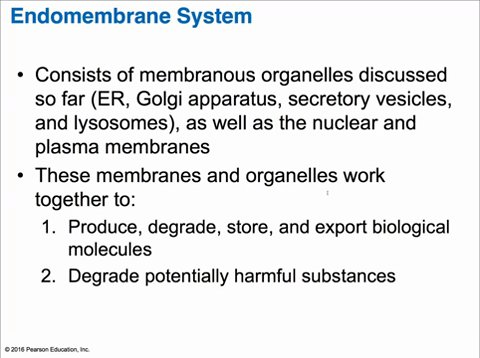
...
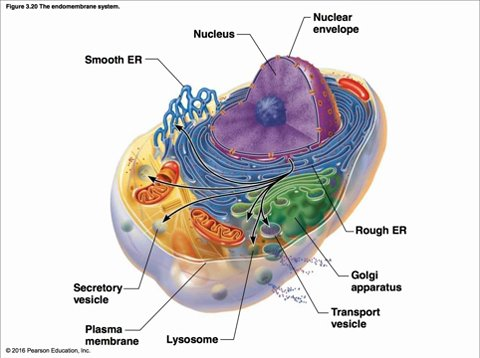
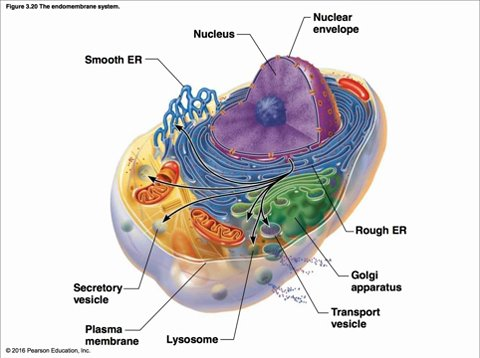
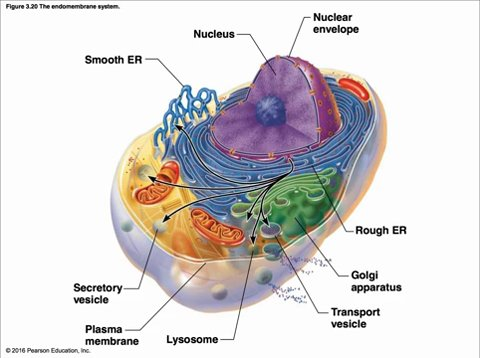
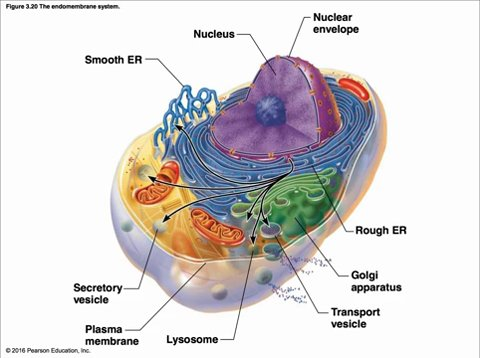
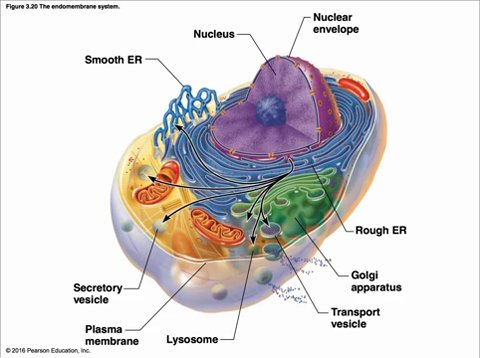

Gallery: 42 / 48 cases; 1547 frames



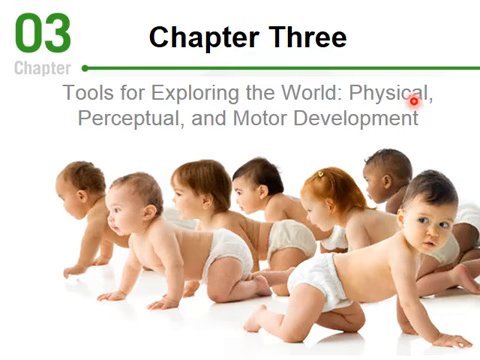
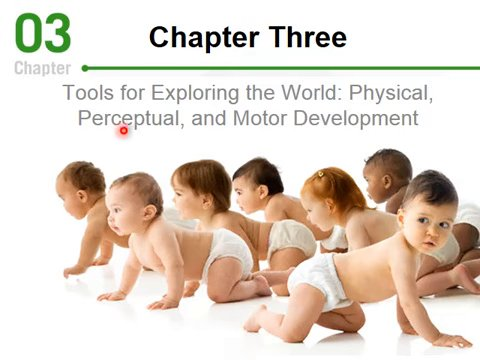
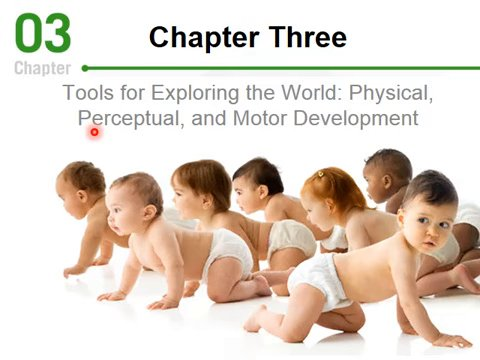
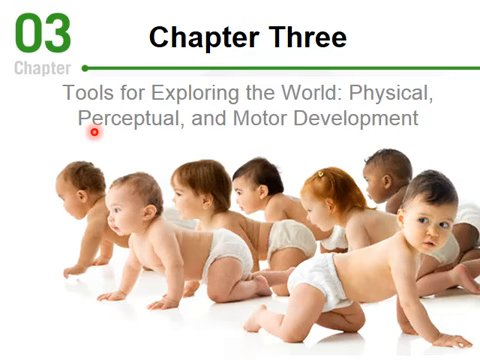
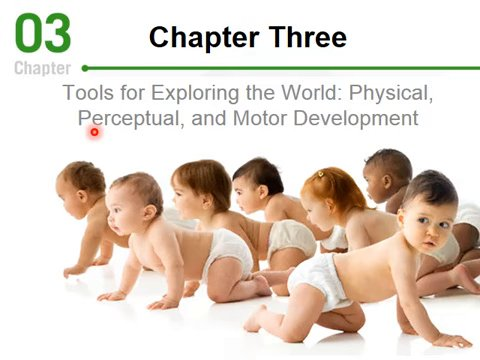
...
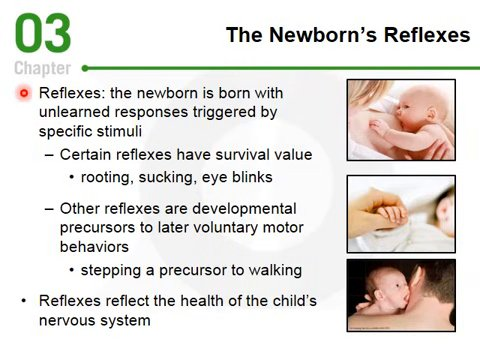
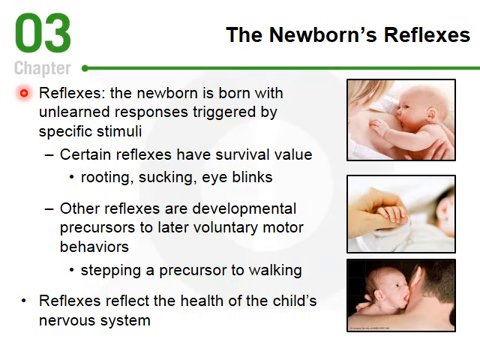
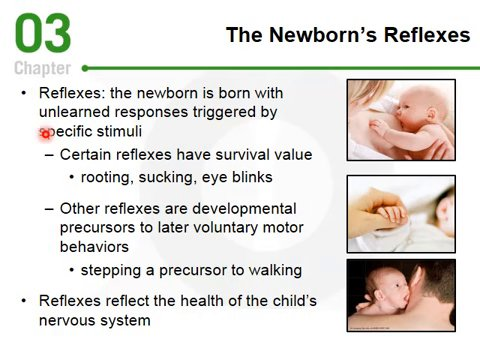
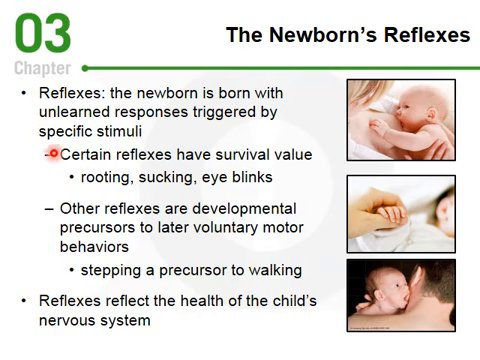
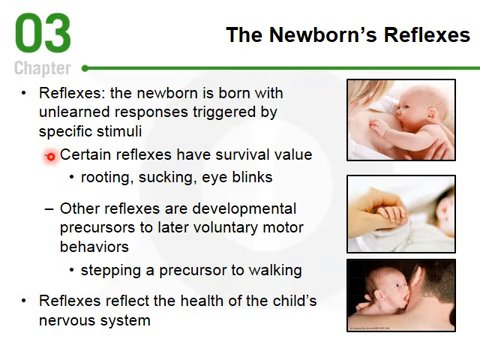

Gallery: 43 / 48 cases; 1585 frames



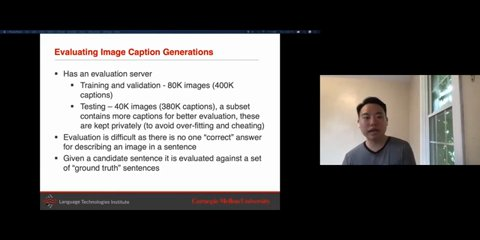
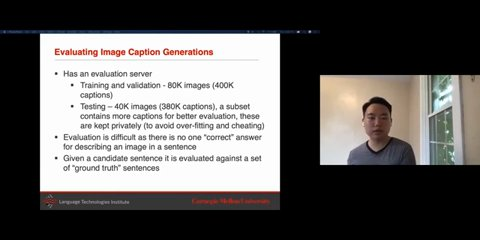
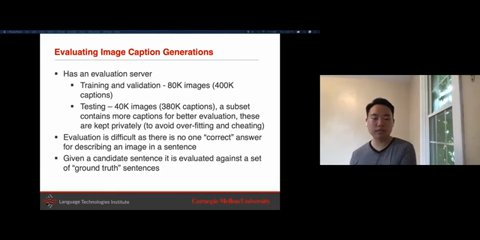
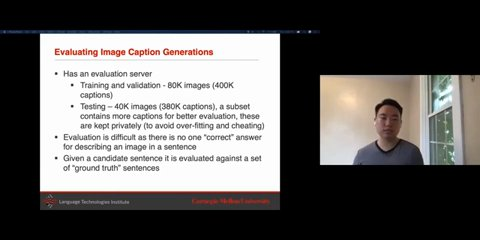
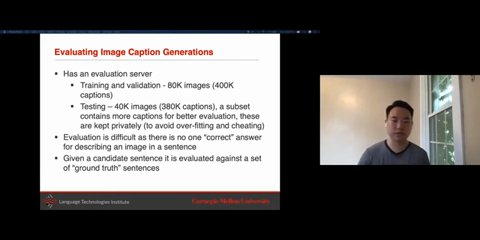
...
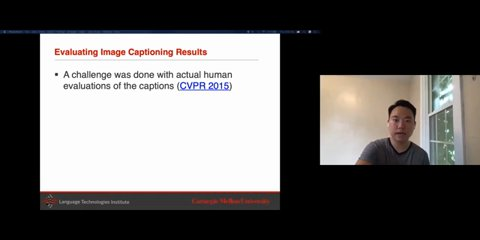
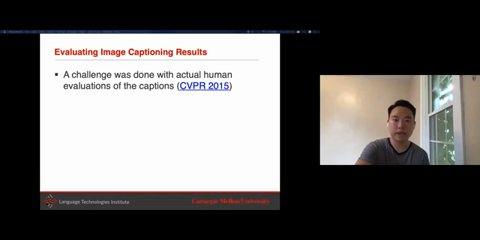
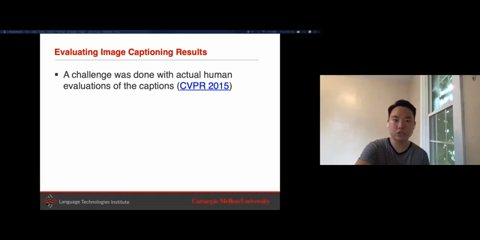
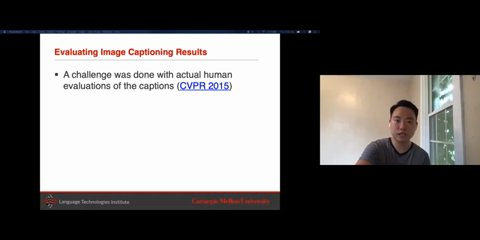
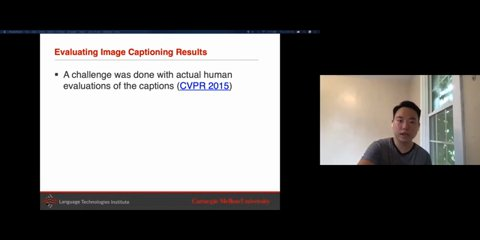

Gallery: 44 / 48 cases; 1623 frames



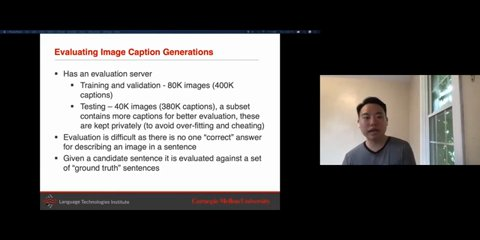
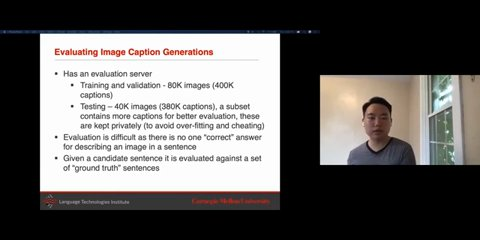
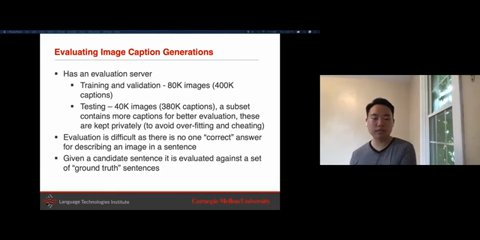
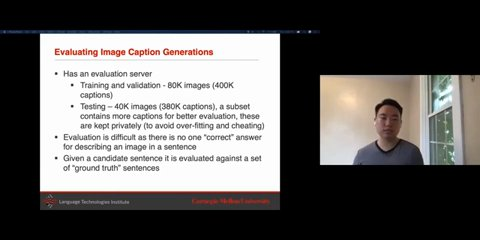
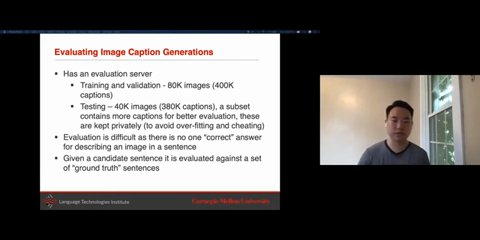
...
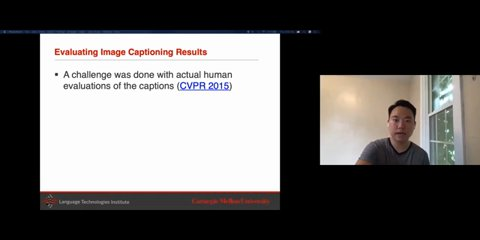
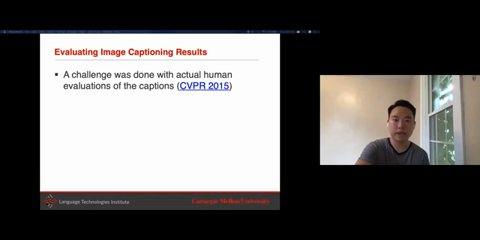
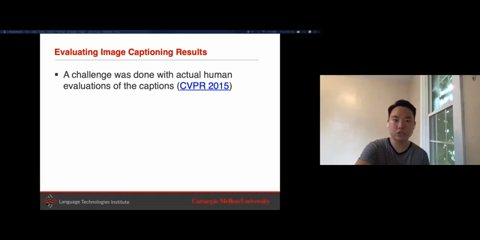
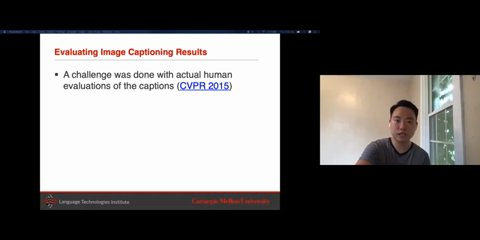
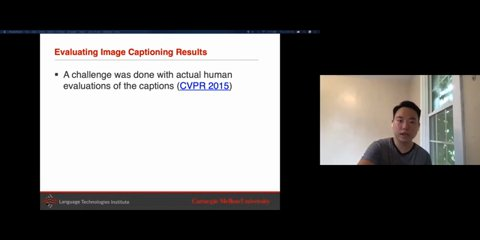

Gallery: 45 / 48 cases; 1661 frames



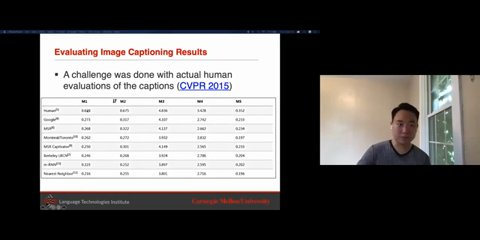
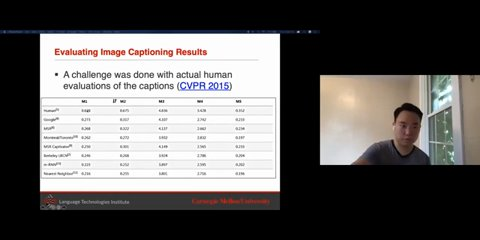
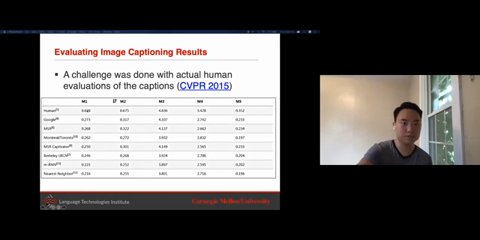
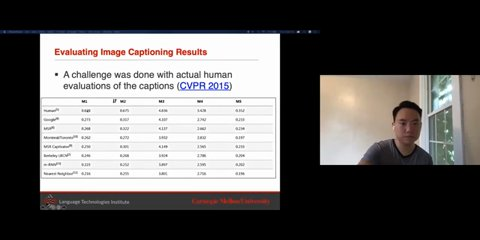
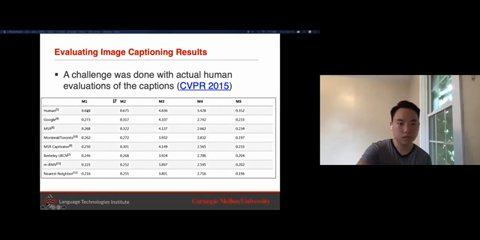
...
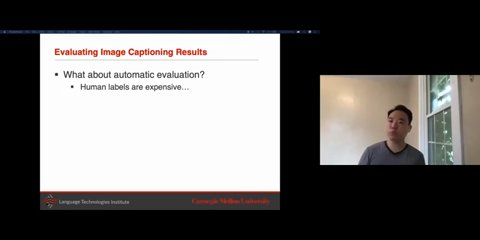
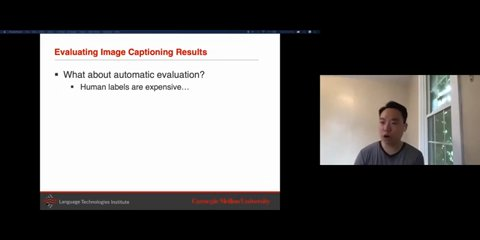
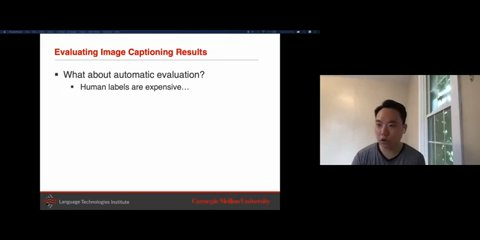
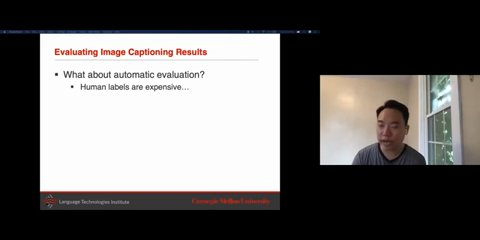
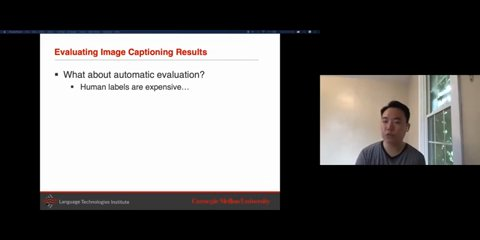

Gallery: 46 / 48 cases; 1699 frames



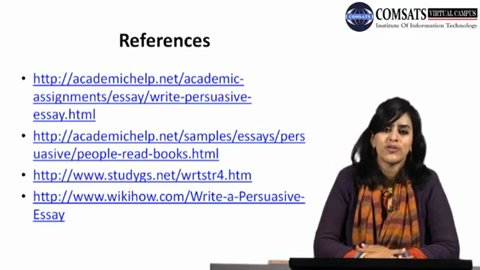
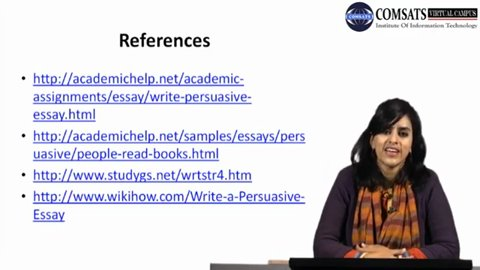
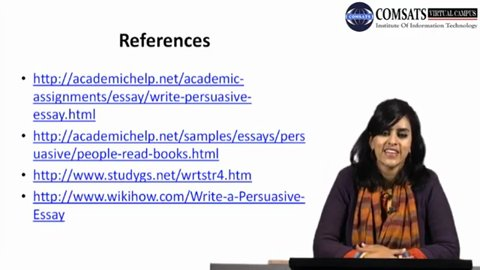
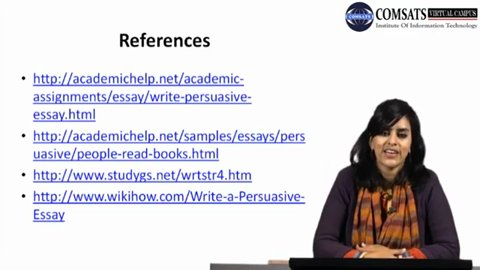
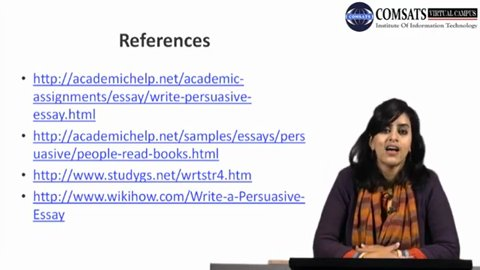
...
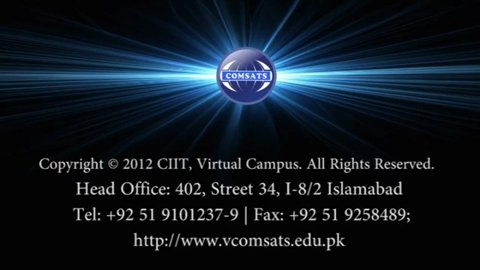
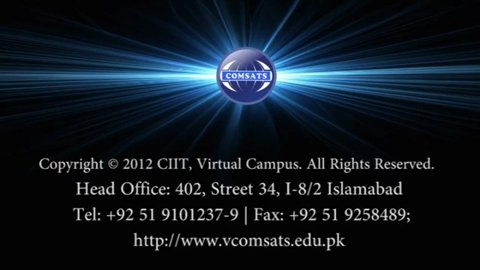
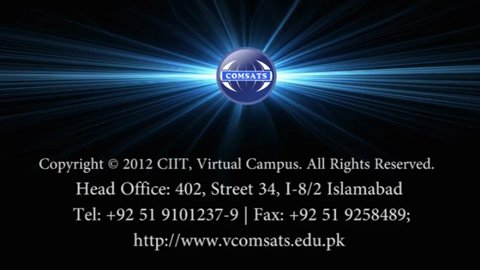
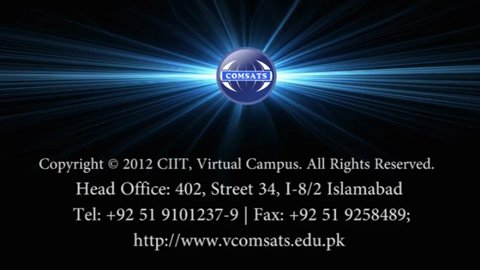
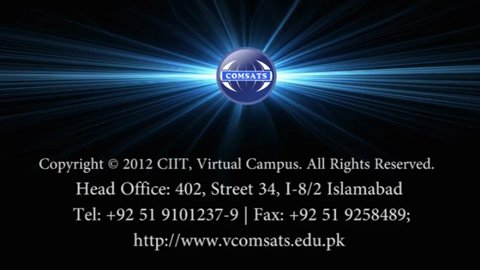

Gallery: 47 / 48 cases; 1735 frames



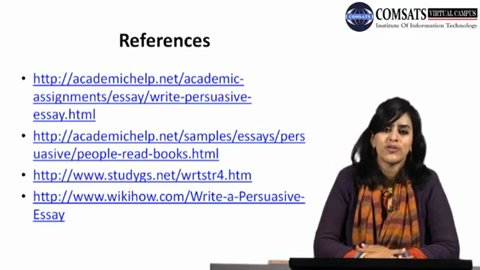
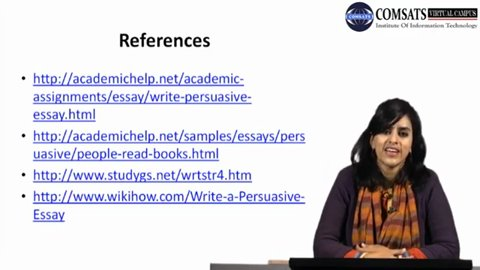
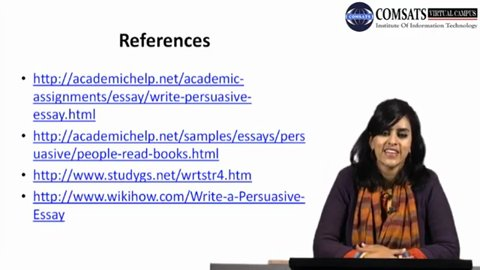
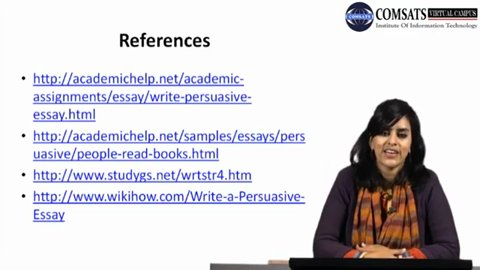
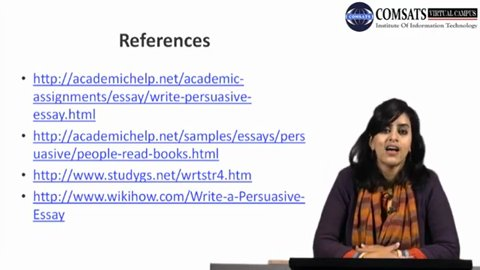
...
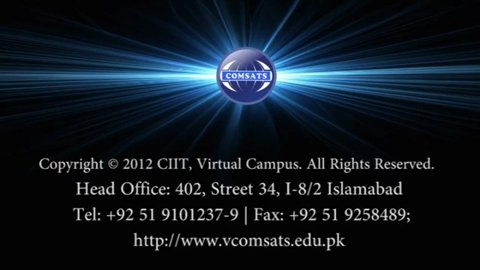
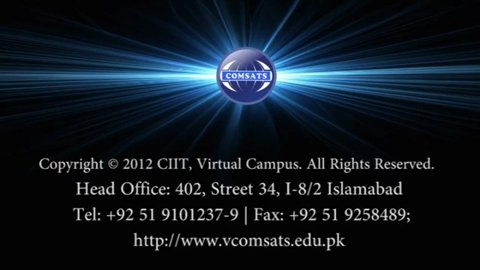
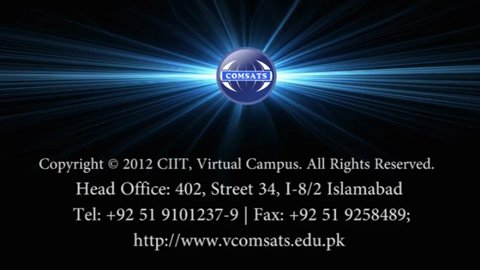
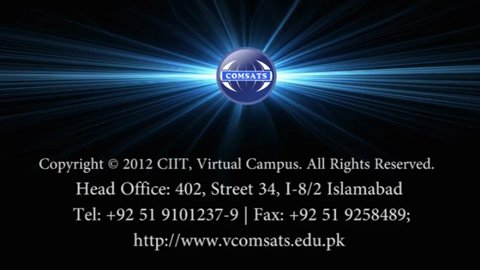
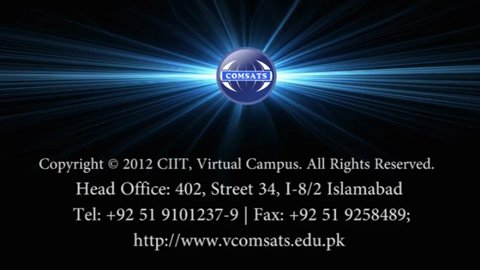

Gallery: 48 / 48 cases; 1771 frames


In [10]:
display_summary = dict(status='complete',cases=0,rendered_frames=0,display_failures=0)
try:
    for key,value in results.items():
        try:
            block,stats = render_review_case(case_by_key[key],value,REVIEW_ROOT)
            display(HTML(block))
            display_summary['cases']+=1
            for field in ['rendered_frames','display_failures']:display_summary[field]+=stats[field]
        except Exception as error:
            display_summary['display_failures']+=1
            print('Presentation failed for',key,type(error).__name__,str(error)[:200])
        print('Gallery:',display_summary['cases'],'/',len(results),'cases;',display_summary['rendered_frames'],'frames',flush=True)
except BaseException:
    display_summary['status']='interrupted_after_receipt'
    raise
finally:
    review_receipt=save_run_receipt(display_summary)


## Hồ sơ review và điều kiện bước tiếp theo
GT/cohort vẫn HOLD cho đến khi quyết định sự kiện và endpoint có bằng chứng frame gốc. Cửa sổ0.25s hỗ trợ phân loại/ngữ cảnh; nếu chưa rõ thì giữ bracket/HOLD, không lấy midpoint hoặc cộng bù timestamp hàng loạt. Không chạy detector để quyết định sửa GT.

In [11]:
template=[]
for key,case in case_by_key.items():
    template.append(dict(protocol_id=PROTOCOL['protocol_id'],protocol_sha256=BUNDLE['protocol_sha256'],video_id=case['video_id'],source_sha256=case['source_sha256'],annotation_sha256=case['annotation_sha256'],original_row_index=case['annotation_index'],released_time_sec=case['annotation_s'],reviewer='',reviewed_at='',event_class='',disposition='hold',reason='native_endpoint_or_policy_pending',confidence='',native_evidence_status='unreviewed',pts_time_base_and_origin='',point_or_bracket='',effect_fields='',evidence_paths_and_sha256='',original_to_reviewed_event_mapping=''))
pd.DataFrame(template).to_csv(REVIEW_ROOT/'review-decisions-template.csv',index=False)
review_table(template,'Decision template, deliberately not approved labels')
print(json.dumps(review_receipt,indent=2,ensure_ascii=False))
display(Markdown('**Save this notebook with outputs. Không ZIP, không tải lại nguồn, không sửa annotation. Protocol rules đã frozen; semantic GT và cohort chưa frozen.**'))


**Decision template, deliberately not approved labels: 82 rows**

protocol_id,protocol_sha256,video_id,source_sha256,annotation_sha256,original_row_index,released_time_sec,reviewer,reviewed_at,event_class,disposition,reason,confidence,native_evidence_status,pts_time_base_and_origin,point_or_bracket,effect_fields,evidence_paths_and_sha256,original_to_reviewed_event_mapping
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,-8QB3Rbeqoc,0b8e9c305bc16e56ab2af5d8ca8584445ee8761a840b76479a04828252beaf42,63d4339e7a61189f23483725e5e7853f867255d12a4fdcee30430368c23db742,5,817.4560,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,-a5-EHnZ_XA,b5e7a2c046e0af27c3efde8358cc846183338416b9c4aa5e58efa84d9d1187ef,be5572403c5a16da3655b9b6473609660d42b7eec0c88b060f47ad8b69861314,5,355.4222,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,-a5-EHnZ_XA,b5e7a2c046e0af27c3efde8358cc846183338416b9c4aa5e58efa84d9d1187ef,be5572403c5a16da3655b9b6473609660d42b7eec0c88b060f47ad8b69861314,6,355.4221,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,-a5-EHnZ_XA,b5e7a2c046e0af27c3efde8358cc846183338416b9c4aa5e58efa84d9d1187ef,be5572403c5a16da3655b9b6473609660d42b7eec0c88b060f47ad8b69861314,7,357.4221,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,077X0x07S0c,c1e9e7a89ca1fb345f7e9b677b9710eb2f027602d59c057327c566bb7c0c9446,2e526aa4d542442f9dfee2c9398d0899e9a944f7ce0b645e472c5dd1af8cff5d,32,1966.0000,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,0gf3IJFTxEA,a68df814e2b2321795d8c9bcf2e8996c6b89e1e50bc080f0f938168a6bff29c0,007d7a3c6898c1a561a574a1acd1e534289b690dc9dc967dbf5d6b117b897136,0,29.5000,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,0gf3IJFTxEA,a68df814e2b2321795d8c9bcf2e8996c6b89e1e50bc080f0f938168a6bff29c0,007d7a3c6898c1a561a574a1acd1e534289b690dc9dc967dbf5d6b117b897136,23,2780.4558,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,18SixEz5GDE,d892448c45a2074e2b19a216ec8354879afb0457d5b67dd6c47108a1428c1ac8,2d3068cf2d03094bdb242d88d291c366b4dced8114528c2ef6942565363422b6,0,17.4132,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,18SixEz5GDE,d892448c45a2074e2b19a216ec8354879afb0457d5b67dd6c47108a1428c1ac8,2d3068cf2d03094bdb242d88d291c366b4dced8114528c2ef6942565363422b6,13,1015.9130,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,
mlpdataset-slide-transition-protocol-v1,c213748c2ca733dae518e8629f7f0c86a1bd64231575d96ca460e4a1c03d0dc2,18SixEz5GDE,d892448c45a2074e2b19a216ec8354879afb0457d5b67dd6c47108a1428c1ac8,2d3068cf2d03094bdb242d88d291c366b4dced8114528c2ef6942565363422b6,26,2365.6396,,,,hold,native_endpoint_or_policy_pending,,unreviewed,,,,,


{
  "all_case_statuses": [
    {
      "key": "-8QB3Rbeqoc:5",
      "group": "dental",
      "action": "historical_coarse_review_available",
      "selected_for_extraction": false,
      "extraction_status": "historical_coarse_review_available",
      "frames": 0,
      "error": "",
      "gt_disposition": "hold"
    },
    {
      "key": "-a5-EHnZ_XA:5",
      "group": "dental",
      "action": "needs_dense_context",
      "selected_for_extraction": true,
      "extraction_status": "ready",
      "frames": 38,
      "error": "",
      "gt_disposition": "hold"
    },
    {
      "key": "-a5-EHnZ_XA:6",
      "group": "dental",
      "action": "needs_dense_context",
      "selected_for_extraction": true,
      "extraction_status": "ready",
      "frames": 38,
      "error": "",
      "gt_disposition": "hold"
    },
    {
      "key": "-a5-EHnZ_XA:7",
      "group": "dental",
      "action": "needs_dense_context",
      "selected_for_extraction": true,
      "extraction_status": "ready"

**Save this notebook with outputs. Không ZIP, không tải lại nguồn, không sửa annotation. Protocol rules đã frozen; semantic GT và cohort chưa frozen.**